### Top30 as Tgt

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Flatten, Concatenate, Reshape, RepeatVector
from tensorflow.keras.models import Model
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,roc_auc_score
from tensorflow.keras.metrics import AUC, Precision
import os

In [2]:
train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
test_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\test_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
master_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

df_train = pd.read_excel(train_data_path)
df_test = pd.read_excel(test_data_path)
df_master = pd.read_excel(master_data_path)
qtrly_returns_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\lag\Quarterly_Price_Returns_Labels.xlsx"

In [3]:
df_train.reset_index(drop=True,inplace=True)
df_test.reset_index(drop=True,inplace=True)

In [4]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

##### Scaling

In [5]:
scaler = StandardScaler()

In [6]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

In [7]:
vif_cols = list(df_train.columns)
for col in ['Ticker','Quarter','Set','Target']:
    if col in vif_cols:
        vif_cols.remove(col)

In [8]:
vif_cols

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [9]:
df_test.replace([np.inf, -np.inf], 0, inplace=True)

In [10]:
# df_test.replace([np.inf, -np.inf], 0, inplace=True)

In [10]:
train_data = scaler.fit_transform(df_train[vif_cols])
test_data = scaler.transform(df_test[vif_cols])

In [11]:
df_train1 = pd.DataFrame(train_data,columns=vif_cols)
df_test1 = pd.DataFrame(test_data,columns=vif_cols)

In [12]:
for col in ['Ticker','Target', 'Quarter']:
    df_train1[col] = df_train[col]
    df_test1[col] = df_test[col]

In [13]:


# 1. Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the La
# belEncoder on the entire set of unique labels across train, validation, and test data
all_tickers = pd.concat([df_train1['Ticker'], df_test1['Ticker']]).unique()
label_encoder.fit(all_tickers)

LabelEncoder()

In [14]:
df_train1['Ticker_encoded'] = label_encoder.transform(df_train1['Ticker'])
df_test1['Ticker_encoded'] = label_encoder.transform(df_test1['Ticker'])

In [15]:
def create_ticker_embedding(input_dim, output_dim):
    return Embedding(input_dim=input_dim, output_dim=output_dim, input_length=1)

In [16]:
# Now, the LabelEncoder is aware of all the possible tickers in all datasets
embedding_size = len(df_train1['Ticker_encoded'].unique())  # Size of the embedding

# You can now proceed with creating your ticker embedding layer and other steps
ticker_embedding_layer = create_ticker_embedding(input_dim=embedding_size, output_dim=10)


d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [17]:
features = vif_cols.copy()
features.append("Quarter")

In [18]:
features.remove("Quarter")
X_train = df_train1[features].values
y_train = df_train1['Target'].values

df_test1['Quarter'] = pd.to_datetime(df_test1['Quarter'])
df_test1['Year'] = df_test1['Quarter'].dt.year
df_test1['Quarter_number'] = df_test1['Quarter'].dt.quarter

X_test = df_test1[features].values
y_test = df_test1['Target'].values

# X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
# X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (42985, 11)
y_train shape: (42985,)
X_test shape: (10788, 11)
y_test shape: (10788,)


In [19]:
ticker_encoded_train = df_train1['Ticker_encoded'].values
ticker_encoded_test = df_test1['Ticker_encoded'].values

In [20]:

def calculate_metrics(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':f'{confusion}'
    }


def process_and_evaluate1(model, X_train, y_train,X_test, y_test, ticker_encoded_train,ticker_encoded_test,epochs,checkpoint_path,batch_size,k=5):
    
    
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    for train_index, val_index in kf.split(X_train):
        X_train1, X_val = X_train[train_index], X_train[val_index]
        y_train1, y_val = y_train[train_index], y_train[val_index]
        ticker_train, ticker_val = ticker_encoded_train[train_index], ticker_encoded_train[val_index]

    early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                    save_weights_only=False,save_freq=epochs*batch_size,
                                                    verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.35, patience=7, min_lr=1e-6, verbose=1)
    history = model.fit([ticker_train, X_train1], y_train1,
            validation_data=([ticker_val, X_val], y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[early_stop, reduce_lr, cp_callback], verbose=0)

    # history = model.fit([ticker_encoded_train, X_train], y_train, epochs=epochs, batch_size=batch_size, validation_data=([ticker_encoded_test, X_test], y_test),callbacks=[cp_callback,early_stop])
    # model.load_weights(checkpoint_path)

    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.legend()
    

#### CNN

In [21]:
from tensorflow.keras.layers import Input, Embedding, Flatten, RepeatVector, Concatenate, Conv1D, GlobalAveragePooling1D, Dense, Reshape
from tensorflow.keras.models import Model
from tensorflow.keras.metrics import AUC, Precision

def build_cnn_model_top30(input_shape, embedding_size, num_tickers):
    continuous_input = Input(shape=input_shape[1:], name="continuous_input")  # shape: (11,)
    ticker_input = Input(shape=(1,), name="ticker_input")

    # Ticker embedding
    ticker_embedding = Embedding(input_dim=num_tickers, output_dim=embedding_size)(ticker_input)
    ticker_embedding = Flatten()(ticker_embedding)
    ticker_embedding = RepeatVector(input_shape[1])(ticker_embedding)  # shape: (None, 11, embedding_size)

    # Reshape continuous input to match dimensions
    reshaped_continuous = Reshape((input_shape[1], 1))(continuous_input)  # shape: (None, 11, 1)

    # Merge inputs
    merged = Concatenate(axis=2)([ticker_embedding, reshaped_continuous])  # shape: (None, 11, embedding_size + 1)

    # CNN layers
    x = Conv1D(filters=64, kernel_size=1, activation='relu')(merged)
    x = GlobalAveragePooling1D()(x)
    output = Dense(1, activation='sigmoid')(x)

    model = Model(inputs=[ticker_input, continuous_input], outputs=output)
    return model


In [22]:
num_tickers = len(label_encoder.classes_)

In [23]:
cnn_top30_model = build_cnn_model_top30(X_train.shape, embedding_size, num_tickers)
cnn_top30_model.compile(optimizer='adam', 
                   loss='binary_crossentropy',  # Binary classification problem
                   metrics=[AUC(),Precision()])

In [24]:
X_train = X_train.reshape(-1, 11)
X_test = X_test.reshape(-1, 11)

In [25]:
np.isnan(X_test).sum()

np.int64(0)

In [26]:
df_train1['Ticker_encoded'].shape

(42985,)

In [27]:
X_train.shape

(42985, 11)

In [28]:
y_test.shape

(10788,)

In [29]:
checkpoints_path = r"D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts"


Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top30.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top30.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top30.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top30.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top30.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top30.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top30.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top30.keras

Epoch 3: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top30.keras



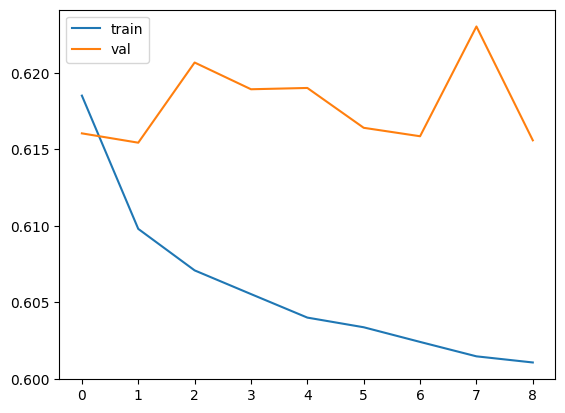

In [30]:
process_and_evaluate1(
    cnn_top30_model,
    X_train, y_train,
    X_test, y_test,
    np.array(df_train1['Ticker_encoded']), np.array(df_test1['Ticker_encoded'])
    ,checkpoint_path=rf'{checkpoints_path}\cnn_top30.keras',epochs=30,batch_size=16
)

In [31]:
bi_lstm_model_loaded = tf.keras.models.load_model(rf'{checkpoints_path}\cnn_top30.keras')

In [32]:
pred_probs_test = bi_lstm_model_loaded.predict([ticker_encoded_test, X_test])
pred_probs_train = bi_lstm_model_loaded.predict([ticker_encoded_train, X_train])



338/338 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
1344/1344 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step


In [33]:
np.isnan(pred_probs_test).sum()

np.int64(0)

In [34]:
np.isnan(pred_probs_train).sum()

np.int64(0)

In [35]:

def calculate_metrics1(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':confusion
    }



In [36]:
train_metrics1 = calculate_metrics1(y_train,(pred_probs_train>=0.5).astype(int),pred_probs_train)
test_metrics1 = calculate_metrics1(y_test,(pred_probs_test>=0.5).astype(int),pred_probs_test)

In [37]:
train_metrics_df1 = pd.DataFrame([train_metrics1])
train_metrics_df1['Set'] = "Train"
test_metrics_df1 = pd.DataFrame([test_metrics1])
test_metrics_df1['Set'] = "Test"
model_metrics1 = pd.concat([train_metrics_df1,test_metrics_df1],axis=0)
model_metrics1.reset_index(drop=True,inplace=True)
model_metrics1.head()

,accuracy,roc,precision,recall,f1,confusion_matrix,Set
0,0.693312,0.614876,0.524632,0.061840,0.110639,"[[28982, 743], [12440, 820]]",Train
1,0.760011,0.519267,0.249541,0.058722,0.095072,"[[8063, 409], [2180, 136]]",Test


In [38]:
model_name = 'cnn_top30'
top_n = 30

In [39]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [40]:
df_master = pd.read_excel(master_data_path)

In [41]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [51]:
# df_pred1.columns

In [42]:
def label_prediction(row, model_name,top_n):
    in_top_50 = row[f'Top_{top_n}_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_50 and target == 1:
        return 'TP'
    elif in_top_50 and target == 0:
        return 'FP'
    elif not in_top_50 and target == 0:
        return 'TN'
    elif not in_top_50 and target == 1:
        return 'FN'

def flag_top50_nlargest(group, pred_prob_col,top_n):
    # If all pred_probs are zero, return all False
    if group[pred_prob_col].sum() == 0:
        return pd.Series([False] * len(group), index=group.index)
    # Use nlargest to get exactly 50
    top50_idx = group[pred_prob_col].nlargest(top_n).index
    flag = pd.Series(False, index=group.index)
    flag.loc[top50_idx] = True
    return flag

def label_prediction1(row, model_name):
    has_more_prob_than_threshold = row[f'Pred_Prob_Threshold_{model_name}']
    target = row['Target']
    
    if has_more_prob_than_threshold and target == 1:
        return 'TP'
    elif has_more_prob_than_threshold and target == 0:
        return 'FP'
    elif not has_more_prob_than_threshold and target == 0:
        return 'TN'
    elif not has_more_prob_than_threshold and target == 1:
        return 'FN'
    
def add_suffix_to_cols(df, suffix, exclude_cols):
    return df.rename(
        columns={col: f"{col}{suffix}" for col in df.columns if col not in exclude_cols + ['Quarter', 'Set']}
    )


In [43]:

if len(set(['Rank','Returns'])-set(df_train1.columns))!=0:
    print("There are no rank and returns columns, merging now..!")
    df_train1 = df_train1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')
    df_test1 = df_test1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')

if np.isnan(pred_probs_train).all():
    print("All predictionsa re NaNs")

df_train_pred = df_train1[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test1[['Ticker','Quarter','Target','Returns','Rank']]

df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)

#### Top30 as fund - irrespective of the prob values
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)



df_pred.reset_index(drop=True,inplace=True)
df_pred.sort_values(by=['Quarter',f'Pred_Prob_{model_name}'],ascending=False,inplace=True)
df_pred[f'Top_{top_n}_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',top_n)

df_pred[f'Top_50_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',50)
# df_pred[(df_pred['Top_{top_n}_Pred_Prob_lstm_top50']==True)&(df_pred['Quarter']=='2005-12-31')]

# test_qtr_preds = df_pred[(df_pred['Quarter']=='2005-12-31')]['Pred_Prob_lstm_top50']
# test_qtr_preds[test_qtr_preds>0.9].shape
df_pred['Pred_Category_Top30'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=30), axis=1)
df_pred['Pred_Category_Top50'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=50), axis=1)
df_pred.reset_index(drop=True,inplace=True)

qtr_summary_df = df_pred.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Top30=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_30_Pred_Prob_{model_name}'] == True].mean()),
                    Avg_Returns_Predicted_Top50=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_50_Pred_Prob_{model_name}'] == True].mean()),
                    Count_TP_Top30=('Pred_Category_Top30', lambda x: (x == 'TP').sum()),
                    Count_TN_Top30=('Pred_Category_Top30', lambda x: (x == 'TN').sum()),
                    Count_FP_Top30=('Pred_Category_Top30', lambda x: (x == 'FP').sum()),
                    Count_FN_Top30=('Pred_Category_Top30', lambda x: (x == 'FN').sum()),
                    Count_TP_Top50=('Pred_Category_Top50', lambda x: (x == 'TP').sum()),
                    Count_TN_Top50=('Pred_Category_Top50', lambda x: (x == 'TN').sum()),
                    Count_FP_Top50=('Pred_Category_Top50', lambda x: (x == 'FP').sum()),
                    Count_FN_Top50=('Pred_Category_Top50', lambda x: (x == 'FN').sum())
                    
                    ).reset_index()

# set_summary_df = qtr_summary_df.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

df_pred1 = df_pred[['Ticker','Quarter','Target','Returns','Rank',f'Pred_Prob_{model_name}','Set']].copy()
df_pred1[f'Pred_Prob_Threshold_{model_name}'] = df_pred1[f'Pred_Prob_{model_name}'].between(0.5,1)



df_pred1['Pred_Category'] = df_pred1.apply(lambda row: label_prediction1(row, model_name=model_name), axis=1)
quarterly_returns_f2 = df_pred1.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Thresh=('Returns', lambda x: x[df_pred1.loc[x.index, f'Pred_Prob_Threshold_{model_name}'] == True].mean()),
                    Count_TP_Thresh=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN_Thresh=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP_Thresh=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN_Thresh=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()
# if quarterly_returns_f2['Avg_Returns_Predicted'].isna().any():
#     print("there are quarters where there were no 1s by the model")
# else:
#     print("there are no quarters where there were no 1s by the model")
qtr_summary_df2 = pd.DataFrame(quarterly_returns_f2)


#### Actual and Index returns mapping
##### Actual returns
act_returns = df_pred[df_pred['Target']==1].groupby(by='Quarter')['Returns'].mean()
df_act_returns = pd.DataFrame(act_returns)
df_act_returns.reset_index(inplace=True)
df_act_returns.rename(columns={'Returns':'Avg_Returns_Actual'},inplace=True)
qtr_summary_df = qtr_summary_df.merge(df_act_returns,on='Quarter',how='left')

##### Index returns - Qtrly
df_index = pd.read_excel(qtrly_returns_path,sheet_name='Qtrly_Stock_Returns')
df_index1 = df_index[df_index['Ticker'] == 'Nsemcap'].drop(columns=['Industry']).set_index(keys=['Ticker'])
df_index1 = df_index1.T
df_index1.reset_index(inplace=True)
df_index1.rename(columns={'index':'Quarter','Nsemcap':'Index_Returns'},inplace=True)

df_index1['Quarter'] = df_index1['Quarter'].apply(convert_qtr_to_date)
df_index1['Quarter'] = pd.to_datetime(df_index1['Quarter'],dayfirst=True)

qtr_summary_df = qtr_summary_df.merge(df_index1,how='left',on='Quarter')
qtr_summary_df['delta_returns_act_vs_pred_Top30'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top30']
qtr_summary_df['delta_returns_pred_vs_index_Top30'] = qtr_summary_df['Avg_Returns_Predicted_Top30']-qtr_summary_df['Index_Returns']
qtr_summary_df['delta_returns_act_vs_pred_Top50'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top50']
qtr_summary_df['delta_returns_pred_vs_index_Top50'] = qtr_summary_df['Avg_Returns_Predicted_Top50']-qtr_summary_df['Index_Returns']

qtr_summary_df2 = qtr_summary_df2.merge(df_act_returns,on='Quarter',how='left')
qtr_summary_df2 = qtr_summary_df2.merge(df_index1,on='Quarter',how='left')

qtr_summary_df2['delta_returns_act_vs_pred_Thresh'] = qtr_summary_df2['Avg_Returns_Actual']-qtr_summary_df2['Avg_Returns_Predicted_Thresh']
qtr_summary_df2['delta_returns_pred_vs_index_Thresh'] = qtr_summary_df2['Avg_Returns_Predicted_Thresh']-qtr_summary_df2['Index_Returns']

# set_summary_df2 = qtr_summary_df2.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

exclude_cols = ['Avg_Returns_Actual', 'Index_Returns']
# suffix_map = {
#     'qtr_summary_df2': '_thresh',
#     'qtr_summary_df': '_top'
# }


# Reset index for merge
qtr_summary_df2_reset = qtr_summary_df2.reset_index(drop=True)
qtr_summary_df_reset = qtr_summary_df.reset_index(drop=True)

# Add suffixes
# qtr_summary_df2_suff = add_suffix_to_cols(qtr_summary_df2_reset, suffix_map['qtr_summary_df2'], exclude_cols)
# qtr_summary_df_suff = add_suffix_to_cols(qtr_summary_df_reset, suffix_map['qtr_summary_df'], exclude_cols)
# ...existing code...

# Merge as before
merged_qtr_summary = pd.merge(
    qtr_summary_df_reset, qtr_summary_df2_reset,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

# Define the desired column order
ordered_cols = [
    'Quarter','Set',
    'Avg_Returns_Predicted_Top30','Avg_Returns_Predicted_Top50',
    'Avg_Returns_Predicted_Thresh',
    'Avg_Returns_Actual', 'Index_Returns',
    'delta_returns_act_vs_pred_Top30','delta_returns_pred_vs_index_Top30',
    'delta_returns_act_vs_pred_Top50','delta_returns_pred_vs_index_Top50',
    'delta_returns_act_vs_pred_Thresh','delta_returns_pred_vs_index_Thresh',
    'Count_TP_Top30', 'Count_TP_Top50', 'Count_TP_Thresh',
    'Count_TN_Top30', 'Count_TN_Top50', 'Count_TN_Thresh',
    'Count_FP_Top30', 'Count_FP_Top50', 'Count_FP_Thresh',
    'Count_FN_Top30', 'Count_FN_Top50', 'Count_FN_Thresh'
]

# Add any other columns that might exist but are not in the list
ordered_cols += [col for col in merged_qtr_summary.columns if col not in ordered_cols]

# Reorder columns
merged_qtr_summary = merged_qtr_summary[ordered_cols]
# merged_qtr_summary.reset_index(inplace=True)
merged_qtr_summary.head()

There are no rank and returns columns, merging now..!


C:\Users\43737\AppData\Local\Temp\ipykernel_37916\4113010357.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_37916\4113010357.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_37916\4113010357.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.297618,0.293448,0.399082,0.462237,-0.019376,0.164619,0.316993,0.168789,...,18,281,276,287,10,15,4,174,159,176
1,2005-06-30,Train,0.297203,0.365044,0.300546,0.495418,0.045476,0.198215,0.251727,0.130374,...,21,284,280,284,8,12,8,171,155,172
2,2005-09-30,Train,0.088641,0.119400,0.105630,0.180268,0.244277,0.091627,-0.155636,0.060867,...,16,276,267,279,13,22,10,179,168,180
3,2005-12-31,Train,0.183118,0.209246,0.358275,0.407782,0.058583,0.224665,0.124534,0.198537,...,2,278,268,289,12,22,1,177,167,193
4,2006-03-31,Train,0.024097,-0.031791,0.102668,0.018142,0.187746,-0.005956,-0.163648,0.049933,...,14,285,278,289,10,17,6,175,162,181


In [44]:
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].isna().all()

np.False_

In [45]:
merged_qtr_summary.columns

Index(['Quarter', 'Set', 'Avg_Returns_Predicted_Top30',
       'Avg_Returns_Predicted_Top50', 'Avg_Returns_Predicted_Thresh',
       'Avg_Returns_Actual', 'Index_Returns',
       'delta_returns_act_vs_pred_Top30', 'delta_returns_pred_vs_index_Top30',
       'delta_returns_act_vs_pred_Top50', 'delta_returns_pred_vs_index_Top50',
       'delta_returns_act_vs_pred_Thresh',
       'delta_returns_pred_vs_index_Thresh', 'Count_TP_Top30',
       'Count_TP_Top50', 'Count_TP_Thresh', 'Count_TN_Top30', 'Count_TN_Top50',
       'Count_TN_Thresh', 'Count_FP_Top30', 'Count_FP_Top50',
       'Count_FP_Thresh', 'Count_FN_Top30', 'Count_FN_Top50',
       'Count_FN_Thresh'],
      dtype='object')

In [46]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.9994257 , 0.8445896 , 0.80039686, ..., 0.03146668, 0.01317686,
       0.00409925], dtype=float32)

In [47]:
set_summary_df3 =  merged_qtr_summary.groupby('Set').agg(
    Count_TP_Thresh = ('Count_TP_Thresh','sum'),
    Count_TN_Thresh = ('Count_TN_Thresh','sum'),
    Count_FP_Thresh = ('Count_FP_Thresh','sum'),
    Count_FN_Thresh = ('Count_FN_Thresh','sum'),
    Count_TP_Top30 = ('Count_TP_Top30','sum'),
    Count_TN_Top30 = ('Count_TN_Top30','sum'),
    Count_FP_Top30 = ('Count_FP_Top30','sum'),
    Count_FN_Top30 = ('Count_FN_Top30','sum'),
    Count_TP_Top50 = ('Count_TP_Top50','sum'),
    Count_TN_Top50 = ('Count_TN_Top50','sum'),
    Count_FP_Top50 = ('Count_FP_Top50','sum'),
    Count_FN_Top50 = ('Count_FN_Top50','sum')
)
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,136,8063,409,2180,102,8214,258,2214,152,8024,448,2164
Train,820,28982,743,12440,1047,28732,993,12213,1661,27986,1739,11599


In [48]:

def calc_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return accuracy, precision, recall, f1


In [49]:
for suffix in ['_Top30','_Top50', '_Thresh']:
    print(f"\nMetrics for {suffix}:")
    for set_name, row in set_summary_df3.iterrows():
        tp = row[f'Count_TP{suffix}']
        tn = row[f'Count_TN{suffix}']
        fp = row[f'Count_FP{suffix}']
        fn = row[f'Count_FN{suffix}']
        accuracy, precision, recall, f1 = calc_metrics(tp, tn, fp, fn)
        print(f"{set_name}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")


Metrics for _Top30:
Test: accuracy=0.7709, precision=0.2833, recall=0.0440, f1=0.0762
Train: accuracy=0.6928, precision=0.5132, recall=0.0790, f1=0.1369

Metrics for _Top50:
Test: accuracy=0.7579, precision=0.2533, recall=0.0656, f1=0.1043
Train: accuracy=0.6897, precision=0.4885, recall=0.1253, f1=0.1994

Metrics for _Thresh:
Test: accuracy=0.7600, precision=0.2495, recall=0.0587, f1=0.0951
Train: accuracy=0.6933, precision=0.5246, recall=0.0618, f1=0.1106


In [50]:
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean():
    print("Both the stock picking strategies (Top 30 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 30 and Top 50) have same returns")
else:
    print("All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns")

All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns


In [51]:
qtr_summary_df[qtr_summary_df['Quarter']=='2021-09-30']

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
66,2021-09-30,Train,0.154103,0.211635,14,611,16,181,20,597,30,175,0.362195,0.126554,0.208093,0.027549,0.15056,0.085081


In [52]:
qtr_summary_df2[qtr_summary_df2['Quarter']=='2021-09-30']

,Quarter,Set,Avg_Returns_Predicted_Thresh,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Thresh,delta_returns_pred_vs_index_Thresh
66,2021-09-30,Train,0.253425,23,597,30,172,0.362195,0.126554,0.10877,0.126871


In [53]:
df_pred.columns

Index(['Ticker', 'Quarter', 'Target', 'Returns', 'Rank', 'Pred_Prob_cnn_top30',
       'Set', 'Top_30_Pred_Prob_cnn_top30', 'Top_50_Pred_Prob_cnn_top30',
       'Pred_Category_Top30', 'Pred_Category_Top50'],
      dtype='object')

In [54]:
df_pred1.columns

Index(['Ticker', 'Quarter', 'Target', 'Returns', 'Rank', 'Pred_Prob_cnn_top30',
       'Set', 'Pred_Prob_Threshold_cnn_top30', 'Pred_Category'],
      dtype='object')

In [55]:
merged_qtr_summary[merged_qtr_summary['Quarter']=='2021-09-30']

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
66,2021-09-30,Train,0.154103,0.211635,0.253425,0.362195,0.126554,0.208093,0.027549,0.15056,...,23,611,597,597,16,30,30,181,175,172


In [56]:
merged_qtr_summary[merged_qtr_summary['Avg_Returns_Predicted_Top30'].isna()].shape

(1, 25)

In [57]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.9994257 , 0.8445896 , 0.80039686, ..., 0.03146668, 0.01317686,
       0.00409925], dtype=float32)

In [58]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].describe()

count    10788.000000
mean         0.323142
std          0.109309
min          0.000278
25%          0.260614
50%          0.325287
75%          0.384357
max          1.000000
Name: Pred_Prob_cnn_top30, dtype: float64

In [59]:
merged_qtr_summary['Quarter'].is_monotonic_increasing

True

In [60]:
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,136,8063,409,2180,102,8214,258,2214,152,8024,448,2164
Train,820,28982,743,12440,1047,28732,993,12213,1661,27986,1739,11599


In [61]:
merged_qtr_summary.columns

Index(['Quarter', 'Set', 'Avg_Returns_Predicted_Top30',
       'Avg_Returns_Predicted_Top50', 'Avg_Returns_Predicted_Thresh',
       'Avg_Returns_Actual', 'Index_Returns',
       'delta_returns_act_vs_pred_Top30', 'delta_returns_pred_vs_index_Top30',
       'delta_returns_act_vs_pred_Top50', 'delta_returns_pred_vs_index_Top50',
       'delta_returns_act_vs_pred_Thresh',
       'delta_returns_pred_vs_index_Thresh', 'Count_TP_Top30',
       'Count_TP_Top50', 'Count_TP_Thresh', 'Count_TN_Top30', 'Count_TN_Top50',
       'Count_TN_Thresh', 'Count_FP_Top30', 'Count_FP_Top50',
       'Count_FP_Thresh', 'Count_FN_Top30', 'Count_FN_Top50',
       'Count_FN_Thresh'],
      dtype='object')

In [62]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'] = merged_qtr_summary['Avg_Returns_Predicted_Top30'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top50'] = merged_qtr_summary['Avg_Returns_Predicted_Top50'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Thresh'] = merged_qtr_summary['Avg_Returns_Predicted_Thresh'].ffill()

In [63]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Top50'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].fillna(0,inplace=True)

C:\Users\43737\AppData\Local\Temp\ipykernel_37916\4263771019.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
C:\Users\43737\AppData\Local\Temp\ipykernel_37916\4263771019.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beh

In [64]:
merged_qtr_summary.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.297618,0.293448,0.399082,0.462237,-0.019376,0.164619,0.316993,0.168789,...,18,281,276,287,10,15,4,174,159,176
1,2005-06-30,Train,0.297203,0.365044,0.300546,0.495418,0.045476,0.198215,0.251727,0.130374,...,21,284,280,284,8,12,8,171,155,172
2,2005-09-30,Train,0.088641,0.119400,0.105630,0.180268,0.244277,0.091627,-0.155636,0.060867,...,16,276,267,279,13,22,10,179,168,180
3,2005-12-31,Train,0.183118,0.209246,0.358275,0.407782,0.058583,0.224665,0.124534,0.198537,...,2,278,268,289,12,22,1,177,167,193
4,2006-03-31,Train,0.024097,-0.031791,0.102668,0.018142,0.187746,-0.005956,-0.163648,0.049933,...,14,285,278,289,10,17,6,175,162,181


In [65]:
df_pred.head()

,Ticker,Quarter,Target,Returns,Rank,Pred_Prob_cnn_top30,Set,Top_30_Pred_Prob_cnn_top30,Top_50_Pred_Prob_cnn_top30,Pred_Category_Top30,Pred_Category_Top50
0,uel,2024-12-31,0,NaN,NaN,0.999426,Test,True,True,FP,FP
1,mrf,2024-12-31,0,NaN,NaN,0.844590,Test,True,True,FP,FP
2,yasho,2024-12-31,1,-0.125178,311.0,0.800397,Test,True,True,TP,TP
3,dixon,2024-12-31,1,-0.265205,598.0,0.766699,Test,True,True,TP,TP
4,greenp,2024-12-31,0,-0.400053,768.0,0.726717,Test,True,True,FP,FP


In [66]:
qtr_summary_df.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
0,2005-03-31,Train,0.297618,0.293448,20,281,10,174,35,276,15,159,0.462237,-0.019376,0.164619,0.316993,0.168789,0.312824
1,2005-06-30,Train,0.297203,0.365044,22,284,8,171,38,280,12,155,0.495418,0.045476,0.198215,0.251727,0.130374,0.319569
2,2005-09-30,Train,0.088641,0.119400,17,276,13,179,28,267,22,168,0.180268,0.244277,0.091627,-0.155636,0.060867,-0.124876
3,2005-12-31,Train,0.183118,0.209246,18,278,12,177,28,268,22,167,0.407782,0.058583,0.224665,0.124534,0.198537,0.150662
4,2006-03-31,Train,0.024097,-0.031791,20,285,10,175,33,278,17,162,0.018142,0.187746,-0.005956,-0.163648,0.049933,-0.219537


In [67]:
qtr_summary_df['Set'].value_counts()

Set
Train    68
Test     12
Name: count, dtype: int64

In [68]:
with pd.ExcelWriter(r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\results\lag\top30\3yrs_as_test_data_ts\Pred_Vs_Act_CNN_time_split_25_07_2025.xlsx", ) as writer:
    merged_qtr_summary.to_excel(writer, sheet_name='Qtr_Summary', index=False)
    qtr_summary_df.to_excel(writer, sheet_name='Qtr_Summary_Top', index=False)
    qtr_summary_df2.to_excel(writer, sheet_name='Qtr_Summary_Thresh', index=False)
    df_pred.to_excel(writer, sheet_name='Pred_Vs_Act_Top', index=False)
    df_pred1.to_excel(writer, sheet_name='Pred_Vs_Act_Thresh', index=False)
    set_summary_df3.to_excel(writer, sheet_name='Set_Summary')

### Top30 Xform

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Flatten, Concatenate, Reshape, RepeatVector
from tensorflow.keras.models import Model
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,roc_auc_score
from tensorflow.keras.metrics import AUC, Precision
import os

In [2]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [ ]:
train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
test_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\test_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
master_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

df_train = pd.read_excel(train_data_path)
df_test = pd.read_excel(test_data_path)
df_master = pd.read_excel(master_data_path)
qtrly_returns_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\lag\Quarterly_Price_Returns_Labels.xlsx"

In [4]:
df_train.reset_index(drop=True,inplace=True)
df_test.reset_index(drop=True,inplace=True)

In [5]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

In [6]:
print(df_train['Quarter'].dtypes,df_test['Quarter'].dtypes,df_master['Quarter'].dtypes)

datetime64[ns] datetime64[ns] object


In [7]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [8]:
df_train = df_train.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])
df_test = df_test.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])

In [9]:
vif_cols = list(df_train.columns)
for col in ['Ticker','Quarter','Set','Returns','Rank','Target']:
    if col in vif_cols:
        vif_cols.remove(col)

In [10]:
vif_cols

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [11]:
from scipy.stats import skew

In [12]:
skewness = df_train[vif_cols].apply(lambda x: skew(x.dropna()))

In [13]:
skewness

TMR               13.086663
Momentum          12.412323
Beta               5.806239
Alpha             23.272412
EP                16.510138
BP               111.210752
SP                49.816550
Dividend_Flag     -1.256040
DE                37.320149
EPS              -40.005117
Zscore             2.836515
dtype: float64

In [14]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox

for col in vif_cols:
    x = df_train[col].dropna()
    print(f"\nFeature: {col}")
    print(f"Original skewness: {skew(x)}")
    if (x <= 0).any():
        # Use Yeo-Johnson for non-positive data
        pt = PowerTransformer(method='yeo-johnson')
        x_trans = pt.fit_transform(x.values.reshape(-1, 1)).flatten()
        print(f"Yeo-Johnson skewness: {skew(x_trans)}")
    else:
        # Try log and Box-Cox for positive data
        x_log = np.log1p(x)
        print(f"log1p skewness: {skew(x_log)}")
        x_bc, _ = boxcox(x)
        print(f"Box-Cox skewness: {skew(x_bc)}")
# ...existing code...


Feature: TMR
Original skewness: 13.086662785414012
Yeo-Johnson skewness: 1.3741422367307328

Feature: Momentum
Original skewness: 12.412322770259664
Yeo-Johnson skewness: -0.37304497754437993

Feature: Beta
Original skewness: 5.8062388351951615
Yeo-Johnson skewness: 4.617342875794953

Feature: Alpha
Original skewness: 23.272412041065202
Yeo-Johnson skewness: -2.9388817602113577

Feature: EP
Original skewness: 16.51013828757582
log1p skewness: 7.797053632006263
Box-Cox skewness: 0.11026200411795387

Feature: BP
Original skewness: 111.2107515117538
Yeo-Johnson skewness: 0.20590787331072397

Feature: SP
Original skewness: 49.8165504035785
log1p skewness: 2.490688401374147
Box-Cox skewness: 0.044374265589872564

Feature: Dividend_Flag
Original skewness: -1.2560396990530387
Yeo-Johnson skewness: -1.2560396990530391

Feature: DE
Original skewness: 37.32014887171092
Yeo-Johnson skewness: 0.04913837052975297

Feature: EPS
Original skewness: -40.00511654482117
Yeo-Johnson skewness: 1.696789070

In [15]:
df_test.replace([np.inf, -np.inf], 0, inplace=True)

In [16]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox
import numpy as np

best_transform_map = {}
for col in vif_cols:
    x = df_train[col].dropna()
    results = {}
    if (x <= 0).any():
        # Only Yeo-Johnson possible
        pt = PowerTransformer(method='yeo-johnson')
        x_yj = pt.fit_transform(x.values.reshape(-1, 1)).flatten()
        results['yeo-johnson'] = abs(skew(x_yj))
    else:
        x_log = np.log1p(x)
        results['log1p'] = abs(skew(x_log))
        try:
            x_bc, _ = boxcox(x)
            results['boxcox'] = abs(skew(x_bc))
        except Exception:
            results['boxcox'] = np.nan
    # Always include original for comparison
    results['original'] = abs(skew(x))
    # Pick the transform with minimum absolute skewness
    best = min(results, key=lambda k: results[k] if not np.isnan(results[k]) else np.inf)
    best_transform_map[col] = best
    print(f"{col}: Best transform = {best}, skewness = {results[best]:.3f}")
# ...existing code...

TMR: Best transform = yeo-johnson, skewness = 1.374
Momentum: Best transform = yeo-johnson, skewness = 0.373
Beta: Best transform = yeo-johnson, skewness = 4.617
Alpha: Best transform = yeo-johnson, skewness = 2.939
EP: Best transform = boxcox, skewness = 0.110
BP: Best transform = yeo-johnson, skewness = 0.206
SP: Best transform = boxcox, skewness = 0.044
Dividend_Flag: Best transform = original, skewness = 1.256
DE: Best transform = yeo-johnson, skewness = 0.049
EPS: Best transform = yeo-johnson, skewness = 1.697
Zscore: Best transform = yeo-johnson, skewness = 0.086


#### Power xforms

In [17]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox
import numpy as np

# 1. Decide best transform for each feature based on your previous results
# best_transform_map = {
#     'TMR': 'yeo-johnson',
#     'Momentum': 'yeo-johnson',
#     'Beta': 'yeo-johnson',
#     'Alpha': 'yeo-johnson',
#     'EP': 'boxcox',
#     'BP': 'yeo-johnson',
#     'SP': 'boxcox',
#     'EPS': 'yeo-johnson',
#     'Zscore': 'yeo-johnson',
#     'FCF': 'yeo-johnson',
#     'ICR': 'yeo-johnson',
#     'Year': 'log1p',
#     'Quarter_number': 'boxcox',  # or 'log1p', both are close
#     # 'Target': 'none',  # Target is not a feature
# }
best_transform_map = {
    'TMR': 'yeo-johnson',
    'Momentum': 'yeo-johnson',
    'Beta': 'yeo-johnson',
    'Alpha': 'yeo-johnson',
    'EP': 'boxcox',
    'BP': 'yeo-johnson',
    'SP': 'boxcox',
    'EPS': 'yeo-johnson',
    'Zscore': 'yeo-johnson',
    'DE': 'yeo-johnson', # ADDED based on your result
    
    # These features either didn't appear in your results or the best transform was 'original':
    # 'FCF': 'yeo-johnson', 
    # 'ICR': 'yeo-johnson', 
    # 'Year': 'log1p', 
    # 'Quarter_number': 'boxcox', 
    # 'Dividend_Flag': 'original', # Do not transform
}
def transform_feature(col, x, method):
    if method == 'yeo-johnson':
        pt = PowerTransformer(method='yeo-johnson')
        return pt.fit_transform(x.values.reshape(-1, 1)).flatten()
    elif method == 'boxcox':
        # Box-Cox requires strictly positive values
        # Add a small constant if min(x) == 0
        x_pos = x.copy()
        if (x_pos <= 0).any():
            x_pos = x_pos - x_pos.min() + 1e-6
        return boxcox(x_pos)[0]
    elif method == 'log1p':
        x_pos = x.copy()
        if (x_pos < 0).any():
            x_pos = x_pos - x_pos.min() + 1e-6
        return np.log1p(x_pos)
    else:
        return x.values

# 2. Apply transforms to train and test
df_train_trans = df_train.copy()
df_test_trans = df_test.copy()

for col in vif_cols:
    method = best_transform_map.get(col, 'none')
    if method != 'none':
        df_train_trans[col] = transform_feature(col, df_train[col], method)
        df_test_trans[col] = transform_feature(col, df_test[col], method)

# 3. Scaling
scaler = StandardScaler()
train_data = scaler.fit_transform(df_train_trans[vif_cols])
test_data = scaler.transform(df_test_trans[vif_cols])

df_train1 = pd.DataFrame(train_data, columns=vif_cols)
df_test1 = pd.DataFrame(test_data, columns=vif_cols)

for col in ['Ticker', 'Target', 'Quarter']:
    df_train1[col] = df_train[col]
    df_test1[col] = df_test[col]

# 4. Prepare X_train, y_train, X_test, y_test
features = vif_cols.copy()
X_train = df_train1[features].values
y_train = df_train1['Target'].values
X_test = df_test1[features].values
y_test = df_test1['Target'].values

# If your model expects 3D input (samples, timesteps, features):
# X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
# X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
# ...existing code...

X_train shape: (42985, 11)
y_train shape: (42985,)
X_test shape: (10788, 11)
y_test shape: (10788,)


In [18]:
check = pd.Series(y_train)
check.unique()

array([0, 1])

In [19]:


# 1. Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the La
# belEncoder on the entire set of unique labels across train, validation, and test data
all_tickers = pd.concat([df_train1['Ticker'], df_test1['Ticker']]).unique()
label_encoder.fit(all_tickers)

LabelEncoder()

In [20]:
df_train1['Ticker_Encoded'] = label_encoder.transform(df_train1['Ticker'])
df_test1['Ticker_Encoded'] = label_encoder.transform(df_test1['Ticker'])

In [21]:
def create_ticker_embedding(input_dim, output_dim):
    return Embedding(input_dim=input_dim, output_dim=output_dim, input_length=1)

In [22]:
# Now, the LabelEncoder is aware of all the possible tickers in all datasets
embedding_size = len(df_train1['Ticker_Encoded'].unique())  # Size of the embedding

# You can now proceed with creating your ticker embedding layer and other steps
ticker_embedding_layer = create_ticker_embedding(input_dim=embedding_size, output_dim=10)


d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [23]:
features = vif_cols.copy()
features.append("Quarter")

In [24]:
ticker_encoded_train = df_train1['Ticker_Encoded'].values
ticker_encoded_test = df_test1['Ticker_Encoded'].values

In [25]:
def calculate_metrics(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':f'{confusion}'
    }


def process_and_evaluate1(model, X_train, y_train,X_test, y_test, ticker_encoded_train,ticker_encoded_test,epochs,checkpoint_path,batch_size,k=5):
    
    
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    for train_index, val_index in kf.split(X_train):
        X_train1, X_val = X_train[train_index], X_train[val_index]
        y_train1, y_val = y_train[train_index], y_train[val_index]
        ticker_train, ticker_val = ticker_encoded_train[train_index], ticker_encoded_train[val_index]

    early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                    save_weights_only=False,save_freq=epochs*batch_size,
                                                    verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.35, patience=7, min_lr=1e-6, verbose=1)
    history = model.fit([ticker_train, X_train1], y_train1,
            validation_data=([ticker_val, X_val], y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[early_stop, reduce_lr, cp_callback], verbose=0)

    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.legend()
    

#### CNN

In [26]:
from tensorflow.keras.layers import Input, Embedding, Flatten, RepeatVector, Concatenate, Conv1D, GlobalAveragePooling1D, Dense, Reshape
from tensorflow.keras.models import Model
from tensorflow.keras.metrics import AUC, Precision

def build_cnn_xform_top30_model(input_shape, embedding_size, num_tickers):
    continuous_input = Input(shape=input_shape[1:], name="continuous_input")  # shape: (11,)
    ticker_input = Input(shape=(1,), name="ticker_input")

    # Ticker embedding
    ticker_embedding = Embedding(input_dim=num_tickers, output_dim=embedding_size)(ticker_input)
    ticker_embedding = Flatten()(ticker_embedding)
    ticker_embedding = RepeatVector(input_shape[1])(ticker_embedding)  # shape: (None, 11, embedding_size)

    # Reshape continuous input to match dimensions
    reshaped_continuous = Reshape((input_shape[1], 1))(continuous_input)  # shape: (None, 11, 1)

    # Merge inputs
    merged = Concatenate(axis=2)([ticker_embedding, reshaped_continuous])  # shape: (None, 11, embedding_size + 1)

    # CNN layers
    x = Conv1D(filters=64, kernel_size=1, activation='relu')(merged)
    x = GlobalAveragePooling1D()(x)
    output = Dense(1, activation='sigmoid')(x)

    model = Model(inputs=[ticker_input, continuous_input], outputs=output)
    return model


In [27]:
num_tickers = len(label_encoder.classes_)

In [28]:

# Define bi_lstm model
cnn_top30_xform_model = build_cnn_xform_top30_model(X_train.shape, embedding_size, num_tickers)
cnn_top30_xform_model.compile(optimizer='adam', 
                   loss='binary_crossentropy',  # Binary classification problem
                   metrics=[AUC(),Precision()])

In [29]:
X_train = X_train.reshape(-1, 11)
X_test = X_test.reshape(-1, 11)

In [30]:
checkpoints_path = r"D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts"


Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top30_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top30_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top30_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top30_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top30_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top30_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top30_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top30_xform.keras

Epoch 3: saving model to D:\Python\Final Quant Fund\Quant Fund\

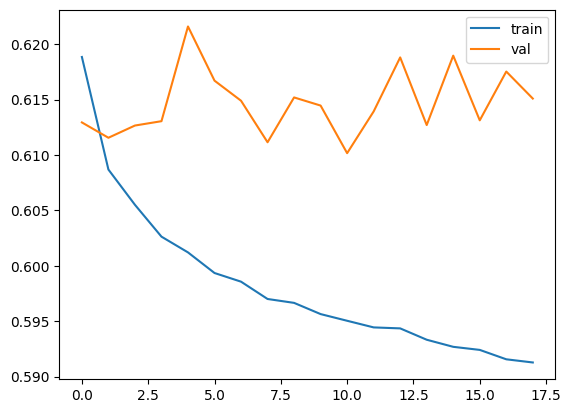

In [31]:
process_and_evaluate1(
    cnn_top30_xform_model,
    X_train, y_train,
    X_test, y_test,
    np.array(df_train1['Ticker_Encoded']), np.array(df_test1['Ticker_Encoded'])
    ,checkpoint_path=rf'{checkpoints_path}\cnn_top30_xform.keras',epochs=30,batch_size=16
)

In [32]:
cnn_top30_xform_model_loaded = tf.keras.models.load_model(rf'{checkpoints_path}\cnn_top30_xform.keras')

In [33]:
pred_probs_test = cnn_top30_xform_model_loaded.predict([ticker_encoded_test, X_test])
pred_probs_train = cnn_top30_xform_model_loaded.predict([ticker_encoded_train, X_train])



338/338 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
1344/1344 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step


In [34]:
np.isnan(pred_probs_test).sum()

np.int64(0)

In [35]:
np.isnan(pred_probs_train).sum()

np.int64(0)

In [36]:

def calculate_metrics1(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':confusion
    }



In [37]:
train_metrics1 = calculate_metrics1(y_train,(pred_probs_train>=0.5).astype(int),pred_probs_train)
test_metrics1 = calculate_metrics1(y_test,(pred_probs_test>=0.5).astype(int),pred_probs_test)

In [38]:
train_metrics_df1 = pd.DataFrame([train_metrics1])
train_metrics_df1['Set'] = "Train"
test_metrics_df1 = pd.DataFrame([test_metrics1])
test_metrics_df1['Set'] = "Test"
model_metrics1 = pd.concat([train_metrics_df1,test_metrics_df1],axis=0)
model_metrics1.reset_index(drop=True,inplace=True)
model_metrics1.head()

,accuracy,roc,precision,recall,f1,confusion_matrix,Set
0,0.697150,0.635255,0.580882,0.065535,0.117783,"[[29098, 627], [12391, 869]]",Train
1,0.774842,0.549506,0.296029,0.035406,0.063247,"[[8277, 195], [2234, 82]]",Test


In [39]:
model_name = 'cnn_top30_xform'
top_n = 30

In [40]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [41]:
df_master = pd.read_excel(master_data_path)

In [42]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [47]:
merged_qtr_summary = pd.merge(
    qtr_summary_df_reset, qtr_summary_df2_reset,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

In [50]:
def label_prediction(row, model_name,top_n):
    in_top_50 = row[f'Top_{top_n}_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_50 and target == 1:
        return 'TP'
    elif in_top_50 and target == 0:
        return 'FP'
    elif not in_top_50 and target == 0:
        return 'TN'
    elif not in_top_50 and target == 1:
        return 'FN'

def flag_top50_nlargest(group, pred_prob_col,top_n):
    # If all pred_probs are zero, return all False
    if group[pred_prob_col].sum() == 0:
        return pd.Series([False] * len(group), index=group.index)
    # Use nlargest to get exactly 50
    top50_idx = group[pred_prob_col].nlargest(top_n).index
    flag = pd.Series(False, index=group.index)
    flag.loc[top50_idx] = True
    return flag

def label_prediction1(row, model_name):
    has_more_prob_than_threshold = row[f'Pred_Prob_Threshold_{model_name}']
    target = row['Target']
    
    if has_more_prob_than_threshold and target == 1:
        return 'TP'
    elif has_more_prob_than_threshold and target == 0:
        return 'FP'
    elif not has_more_prob_than_threshold and target == 0:
        return 'TN'
    elif not has_more_prob_than_threshold and target == 1:
        return 'FN'
    
def add_suffix_to_cols(df, suffix, exclude_cols):
    return df.rename(
        columns={col: f"{col}{suffix}" for col in df.columns if col not in exclude_cols + ['Quarter', 'Set']}
    )


if len(set(['Rank','Returns'])-set(df_train1.columns))!=0:
    print("There are no rank and returns columns, merging now..!")
    df_train1 = df_train1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')
    df_test1 = df_test1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')

if np.isnan(pred_probs_train).all():
    print("All predictionsa re NaNs")

df_train_pred = df_train1[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test1[['Ticker','Quarter','Target','Returns','Rank']]

df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)

#### Top30 as fund - irrespective of the prob values
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)



df_pred.reset_index(drop=True,inplace=True)
df_pred.sort_values(by=['Quarter',f'Pred_Prob_{model_name}'],ascending=False,inplace=True)
df_pred[f'Top_{top_n}_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',top_n)

df_pred[f'Top_50_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',50)
# df_pred[(df_pred['Top_{top_n}_Pred_Prob_lstm_top50']==True)&(df_pred['Quarter']=='2005-12-31')]

# test_qtr_preds = df_pred[(df_pred['Quarter']=='2005-12-31')]['Pred_Prob_lstm_top50']
# test_qtr_preds[test_qtr_preds>0.9].shape
df_pred['Pred_Category_Top30'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=30), axis=1)
df_pred['Pred_Category_Top50'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=50), axis=1)
df_pred.reset_index(drop=True,inplace=True)

qtr_summary_df = df_pred.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Top30=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_30_Pred_Prob_{model_name}'] == True].mean()),
                    Avg_Returns_Predicted_Top50=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_50_Pred_Prob_{model_name}'] == True].mean()),
                    Count_TP_Top30=('Pred_Category_Top30', lambda x: (x == 'TP').sum()),
                    Count_TN_Top30=('Pred_Category_Top30', lambda x: (x == 'TN').sum()),
                    Count_FP_Top30=('Pred_Category_Top30', lambda x: (x == 'FP').sum()),
                    Count_FN_Top30=('Pred_Category_Top30', lambda x: (x == 'FN').sum()),
                    Count_TP_Top50=('Pred_Category_Top50', lambda x: (x == 'TP').sum()),
                    Count_TN_Top50=('Pred_Category_Top50', lambda x: (x == 'TN').sum()),
                    Count_FP_Top50=('Pred_Category_Top50', lambda x: (x == 'FP').sum()),
                    Count_FN_Top50=('Pred_Category_Top50', lambda x: (x == 'FN').sum())
                    
                    ).reset_index()

# set_summary_df = qtr_summary_df.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

df_pred1 = df_pred[['Ticker','Quarter','Target','Returns','Rank',f'Pred_Prob_{model_name}','Set']].copy()
df_pred1[f'Pred_Prob_Threshold_{model_name}'] = df_pred1[f'Pred_Prob_{model_name}'].between(0.5,1)



df_pred1['Pred_Category'] = df_pred1.apply(lambda row: label_prediction1(row, model_name=model_name), axis=1)
quarterly_returns_f2 = df_pred1.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Thresh=('Returns', lambda x: x[df_pred1.loc[x.index, f'Pred_Prob_Threshold_{model_name}'] == True].mean()),
                    Count_TP_Thresh=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN_Thresh=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP_Thresh=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN_Thresh=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()
# if quarterly_returns_f2['Avg_Returns_Predicted'].isna().any():
#     print("there are quarters where there were no 1s by the model")
# else:
#     print("there are no quarters where there were no 1s by the model")
qtr_summary_df2 = pd.DataFrame(quarterly_returns_f2)


#### Actual and Index returns mapping
##### Actual returns
act_returns = df_pred[df_pred['Target']==1].groupby(by='Quarter')['Returns'].mean()
df_act_returns = pd.DataFrame(act_returns)
df_act_returns.reset_index(inplace=True)
df_act_returns.rename(columns={'Returns':'Avg_Returns_Actual'},inplace=True)
qtr_summary_df = qtr_summary_df.merge(df_act_returns,on='Quarter',how='left')

##### Index returns - Qtrly
df_index = pd.read_excel(qtrly_returns_path,sheet_name='Qtrly_Stock_Returns')
df_index1 = df_index[df_index['Ticker'] == 'Nsemcap'].drop(columns=['Industry']).set_index(keys=['Ticker'])
df_index1 = df_index1.T
df_index1.reset_index(inplace=True)
df_index1.rename(columns={'index':'Quarter','Nsemcap':'Index_Returns'},inplace=True)

df_index1['Quarter'] = df_index1['Quarter'].apply(convert_qtr_to_date)
df_index1['Quarter'] = pd.to_datetime(df_index1['Quarter'],dayfirst=True)

qtr_summary_df = qtr_summary_df.merge(df_index1,how='left',on='Quarter')
qtr_summary_df['delta_returns_act_vs_pred_Top30'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top30']
qtr_summary_df['delta_returns_pred_vs_index_Top30'] = qtr_summary_df['Avg_Returns_Predicted_Top30']-qtr_summary_df['Index_Returns']
qtr_summary_df['delta_returns_act_vs_pred_Top50'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top50']
qtr_summary_df['delta_returns_pred_vs_index_Top50'] = qtr_summary_df['Avg_Returns_Predicted_Top50']-qtr_summary_df['Index_Returns']

qtr_summary_df2 = qtr_summary_df2.merge(df_act_returns,on='Quarter',how='left')
qtr_summary_df2 = qtr_summary_df2.merge(df_index1,on='Quarter',how='left')

qtr_summary_df2['delta_returns_act_vs_pred_Thresh'] = qtr_summary_df2['Avg_Returns_Actual']-qtr_summary_df2['Avg_Returns_Predicted_Thresh']
qtr_summary_df2['delta_returns_pred_vs_index_Thresh'] = qtr_summary_df2['Avg_Returns_Predicted_Thresh']-qtr_summary_df2['Index_Returns']

exclude_cols = ['Avg_Returns_Actual', 'Index_Returns']
qtr_summary_df2_reset = qtr_summary_df2.reset_index(drop=True)
qtr_summary_df_reset = qtr_summary_df.reset_index(drop=True)

merged_qtr_summary = pd.merge(
    qtr_summary_df_reset, qtr_summary_df2_reset,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

ordered_cols = [
    'Quarter','Set',
    'Avg_Returns_Predicted_Top30','Avg_Returns_Predicted_Top50',
    'Avg_Returns_Predicted_Thresh',
    'Avg_Returns_Actual', 'Index_Returns',
    'delta_returns_act_vs_pred_Top30','delta_returns_pred_vs_index_Top30',
    'delta_returns_act_vs_pred_Top50','delta_returns_pred_vs_index_Top50',
    'delta_returns_act_vs_pred_Thresh','delta_returns_pred_vs_index_Thresh',
    'Count_TP_Top30', 'Count_TP_Top50', 'Count_TP_Thresh',
    'Count_TN_Top30', 'Count_TN_Top50', 'Count_TN_Thresh',
    'Count_FP_Top30', 'Count_FP_Top50', 'Count_FP_Thresh',
    'Count_FN_Top30', 'Count_FN_Top50', 'Count_FN_Thresh'
]

ordered_cols += [col for col in merged_qtr_summary.columns if col not in ordered_cols]

# Reorder columns
merged_qtr_summary = merged_qtr_summary[ordered_cols]

# merged_qtr_summary.reset_index(inplace=True)

def calc_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return accuracy, precision, recall, f1

for suffix in ['_Top30','_Top50', '_Thresh']:
    print(f"\nMetrics for {suffix}:")
    for set_name, row in set_summary_df3.iterrows():
        tp = row[f'Count_TP{suffix}']
        tn = row[f'Count_TN{suffix}']
        fp = row[f'Count_FP{suffix}']
        fn = row[f'Count_FN{suffix}']
        accuracy, precision, recall, f1 = calc_metrics(tp, tn, fp, fn)
        print(f"{set_name}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")

if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean():
    print("Both the stock picking strategies (Top 30 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 30 and Top 50) have same returns")
else:
    print("All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns")


C:\Users\43737\AppData\Local\Temp\ipykernel_8\4071300849.py:54: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_8\4071300849.py:55: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_8\4071300849.py:58: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataF


Metrics for _Top30:
Test: accuracy=0.7707, precision=0.2806, recall=0.0436, f1=0.0755
Train: accuracy=0.6967, precision=0.5549, recall=0.0854, f1=0.1480

Metrics for _Top50:
Test: accuracy=0.7605, precision=0.2767, recall=0.0717, f1=0.1139
Train: accuracy=0.6958, precision=0.5274, recall=0.1352, f1=0.2152

Metrics for _Thresh:
Test: accuracy=0.7748, precision=0.2960, recall=0.0354, f1=0.0632
Train: accuracy=0.6972, precision=0.5809, recall=0.0655, f1=0.1178
All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns


In [48]:
set_summary_df3 =  merged_qtr_summary.groupby('Set').agg(
    Count_TP_Thresh = ('Count_TP_Thresh','sum'),
    Count_TN_Thresh = ('Count_TN_Thresh','sum'),
    Count_FP_Thresh = ('Count_FP_Thresh','sum'),
    Count_FN_Thresh = ('Count_FN_Thresh','sum'),
    Count_TP_Top30 = ('Count_TP_Top30','sum'),
    Count_TN_Top30 = ('Count_TN_Top30','sum'),
    Count_FP_Top30 = ('Count_FP_Top30','sum'),
    Count_FN_Top30 = ('Count_FN_Top30','sum'),
    Count_TP_Top50 = ('Count_TP_Top50','sum'),
    Count_TN_Top50 = ('Count_TN_Top50','sum'),
    Count_FP_Top50 = ('Count_FP_Top50','sum'),
    Count_FN_Top50 = ('Count_FN_Top50','sum')
)
set_summary_df3


,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,82,8277,195,2234,101,8213,259,2215,166,8038,434,2150
Train,869,29098,627,12391,1132,28817,908,12128,1793,28118,1607,11467


In [49]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'] = merged_qtr_summary['Avg_Returns_Predicted_Top30'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top50'] = merged_qtr_summary['Avg_Returns_Predicted_Top50'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Thresh'] = merged_qtr_summary['Avg_Returns_Predicted_Thresh'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Top50'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].fillna(0,inplace=True)
merged_qtr_summary.head()

C:\Users\43737\AppData\Local\Temp\ipykernel_8\2271013527.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
C:\Users\43737\AppData\Local\Temp\ipykernel_8\2271013527.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as 

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,...,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50,Avg_Returns_Predicted_Thresh,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,delta_returns_act_vs_pred_Thresh,delta_returns_pred_vs_index_Thresh
0,2005-03-31,Train,0.356667,0.347036,25,286,5,169,38,279,...,0.376043,0.115201,0.366412,0.353959,37,281,10,157,0.108279,0.373334
1,2005-06-30,Train,0.362725,0.547476,26,288,4,167,41,283,...,0.317249,-0.052057,0.502000,0.494605,48,278,14,145,0.000814,0.449129
2,2005-09-30,Train,0.091456,0.088459,16,275,14,180,25,264,...,-0.152821,0.091808,-0.155818,0.107894,16,277,12,180,0.072373,-0.136383
3,2005-12-31,Train,0.172242,0.127160,19,279,11,176,25,265,...,0.113658,0.280623,0.068576,0.308819,5,289,1,190,0.098963,0.250236
4,2006-03-31,Train,0.000005,-0.043973,20,285,10,175,33,278,...,-0.187741,0.062115,-0.231719,0.117203,13,291,4,182,-0.099061,-0.070543


In [51]:
(merged_qtr_summary[merged_qtr_summary['Set']=='Train']['Avg_Returns_Predicted_Thresh']==0).sum()


np.int64(0)

In [52]:
df_pred.tail()

,Ticker,Quarter,Target,Returns,Rank,Pred_Prob_cnn_top30_xform,Set,Top_30_Pred_Prob_cnn_top30_xform,Top_50_Pred_Prob_cnn_top30_xform,Pred_Category_Top30,Pred_Category_Top50
53768,ifci,2005-03-31,0,-0.003759,394.0,0.147347,Train,False,False,TN,TN
53769,hcba,2005-03-31,0,0.008764,366.0,0.144787,Train,False,False,TN,TN
53770,glin,2005-03-31,0,0.000000,382.5,0.139391,Train,False,False,TN,TN
53771,baluforg,2005-03-31,0,0.000000,382.5,0.092551,Train,False,False,TN,TN
53772,udaiceme,2005-03-31,0,0.000000,382.5,0.091893,Train,False,False,TN,TN


In [53]:
df_pred['Set'].unique()

array(['Test', 'Train'], dtype=object)

In [54]:
qtr_summary_df.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
0,2005-03-31,Train,0.356667,0.347036,25,286,5,169,38,279,12,156,0.462237,-0.019376,0.105570,0.376043,0.115201,0.366412
1,2005-06-30,Train,0.362725,0.547476,26,288,4,167,41,283,9,152,0.495418,0.045476,0.132694,0.317249,-0.052057,0.502000
2,2005-09-30,Train,0.091456,0.088459,16,275,14,180,25,264,25,171,0.180268,0.244277,0.088811,-0.152821,0.091808,-0.155818
3,2005-12-31,Train,0.172242,0.127160,19,279,11,176,25,265,25,170,0.407782,0.058583,0.235541,0.113658,0.280623,0.068576
4,2006-03-31,Train,0.000005,-0.043973,20,285,10,175,33,278,17,162,0.018142,0.187746,0.018136,-0.187741,0.062115,-0.231719


In [55]:
qtr_summary_df['Set'].value_counts()

Set
Train    68
Test     12
Name: count, dtype: int64

In [56]:
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,82,8277,195,2234,101,8213,259,2215,166,8038,434,2150
Train,869,29098,627,12391,1132,28817,908,12128,1793,28118,1607,11467


In [57]:
with pd.ExcelWriter(r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\results\lag\top30\3yrs_as_test_data_ts\Pred_Vs_Act_CNN_xform_time_split_25_07_2025.xlsx", ) as writer:
    merged_qtr_summary.to_excel(writer, sheet_name='Qtr_Summary', index=False)
    qtr_summary_df.to_excel(writer, sheet_name='Qtr_Summary_Top', index=False)
    qtr_summary_df2.to_excel(writer, sheet_name='Qtr_Summary_Thresh', index=False)
    df_pred.to_excel(writer, sheet_name='Pred_Vs_Act_Top', index=False)
    df_pred1.to_excel(writer, sheet_name='Pred_Vs_Act_Thresh', index=False)
    set_summary_df3.to_excel(writer, sheet_name='Set_Summary')

### Top 50 as Tgt

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Flatten, Concatenate, Reshape, RepeatVector
from tensorflow.keras.models import Model
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,roc_auc_score
from tensorflow.keras.metrics import AUC, Precision
import os

In [2]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [3]:
train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
test_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\test_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
master_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

df_train = pd.read_excel(train_data_path)
df_test = pd.read_excel(test_data_path)
df_master = pd.read_excel(master_data_path)
qtrly_returns_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\lag\Quarterly_Price_Returns_Labels.xlsx"

In [4]:
df_train.reset_index(drop=True,inplace=True)
df_test.reset_index(drop=True,inplace=True)

In [5]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

In [6]:
print(df_train['Quarter'].dtypes,df_test['Quarter'].dtypes,df_master['Quarter'].dtypes)

datetime64[ns] datetime64[ns] object


In [7]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [8]:
df_train = df_train.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])
df_test = df_test.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])

##### Scaling

In [9]:
scaler = StandardScaler()

In [10]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target', 'Returns',
       'Rank'],
      dtype='object')

In [11]:
df_train['Target'] = np.where(df_train['Rank']<=50,1,0)
df_test['Target'] = np.where(df_test['Rank']<=50,1,0)

In [153]:
# df_train.drop()

In [12]:
vif_cols = list(df_train.columns)
for col in ['Ticker','Quarter','Set','Rank','Returns','Target']:
    if col in vif_cols:
        vif_cols.remove(col)

In [13]:
vif_cols

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [14]:
df_test.replace([np.inf, -np.inf], 0, inplace=True)

In [15]:
train_data = scaler.fit_transform(df_train[vif_cols])
test_data = scaler.transform(df_test[vif_cols])

In [16]:
df_train1 = pd.DataFrame(train_data,columns=vif_cols)
df_test1 = pd.DataFrame(test_data,columns=vif_cols)

In [17]:
for col in ['Ticker','Target', 'Quarter','Rank','Returns']:
    df_train1[col] = df_train[col]
    df_test1[col] = df_test[col]

In [18]:


# 1. Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the La
# belEncoder on the entire set of unique labels across train, validation, and test data
all_tickers = pd.concat([df_train1['Ticker'], df_test1['Ticker']]).unique()
label_encoder.fit(all_tickers)

LabelEncoder()

In [19]:
df_train1['Ticker_Encoded'] = label_encoder.transform(df_train1['Ticker'])
df_test1['Ticker_Encoded'] = label_encoder.transform(df_test1['Ticker'])

In [162]:
# df_train1['Ticker_Encoded']

In [20]:
def create_ticker_embedding(input_dim, output_dim):
    return Embedding(input_dim=input_dim, output_dim=output_dim, input_length=1)

In [21]:
# Now, the LabelEncoder is aware of all the possible tickers in all datasets
embedding_size = len(df_train1['Ticker_Encoded'].unique())  # Size of the embedding

# You can now proceed with creating your ticker embedding layer and other steps
ticker_embedding_layer = create_ticker_embedding(input_dim=embedding_size, output_dim=10)


d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [22]:
features = vif_cols.copy()
features.append("Quarter")
features

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore',
 'Quarter']

In [23]:
features.remove("Quarter")
X_train = df_train1[features].values
y_train = df_train1['Target'].values

df_test1['Quarter'] = pd.to_datetime(df_test1['Quarter'])
df_test1['Year'] = df_test1['Quarter'].dt.year
df_test1['Quarter_number'] = df_test1['Quarter'].dt.quarter

X_test = df_test1[features].values
y_test = df_test1['Target'].values

# X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
# X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (42985, 11)
y_train shape: (42985,)
X_test shape: (10788, 11)
y_test shape: (10788,)


In [24]:
ticker_encoded_train = df_train1['Ticker_Encoded'].values
ticker_encoded_test = df_test1['Ticker_Encoded'].values

In [25]:

def calculate_metrics(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':f'{confusion}'
    }


def process_and_evaluate1(model, X_train, y_train,X_test, y_test, ticker_encoded_train,ticker_encoded_test,epochs,checkpoint_path,batch_size,k=5):
    
    
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    for train_index, val_index in kf.split(X_train):
        X_train1, X_val = X_train[train_index], X_train[val_index]
        y_train1, y_val = y_train[train_index], y_train[val_index]
        ticker_train, ticker_val = ticker_encoded_train[train_index], ticker_encoded_train[val_index]

    early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                    save_weights_only=False,save_freq=epochs*batch_size,
                                                    verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.25, patience=7, min_lr=1e-6, verbose=1)
    history = model.fit([ticker_train, X_train1], y_train1,
            validation_data=([ticker_val, X_val], y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[early_stop, reduce_lr, cp_callback], verbose=0)

    # history = model.fit([ticker_encoded_train, X_train], y_train, epochs=epochs, batch_size=batch_size, validation_data=([ticker_encoded_test, X_test], y_test),callbacks=[cp_callback,early_stop])
    # model.load_weights(checkpoint_path)

    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.legend()
    

#### CNN

In [26]:
from tensorflow.keras.layers import Input, Embedding, Flatten, RepeatVector, Concatenate, Conv1D, GlobalAveragePooling1D, Dense, Reshape
from tensorflow.keras.models import Model
from tensorflow.keras.metrics import AUC, Precision

def build_cnn_top50_model(input_shape, embedding_size, num_tickers):
    continuous_input = Input(shape=input_shape[1:], name="continuous_input")  # shape: (11,)
    ticker_input = Input(shape=(1,), name="ticker_input")

    # Ticker embedding
    ticker_embedding = Embedding(input_dim=num_tickers, output_dim=embedding_size)(ticker_input)
    ticker_embedding = Flatten()(ticker_embedding)
    ticker_embedding = RepeatVector(input_shape[1])(ticker_embedding)  # shape: (None, 11, embedding_size)

    # Reshape continuous input to match dimensions
    reshaped_continuous = Reshape((input_shape[1], 1))(continuous_input)  # shape: (None, 11, 1)

    # Merge inputs
    merged = Concatenate(axis=2)([ticker_embedding, reshaped_continuous])  # shape: (None, 11, embedding_size + 1)

    # CNN layers
    x = Conv1D(filters=64, kernel_size=1, activation='relu')(merged)
    x = GlobalAveragePooling1D()(x)
    output = Dense(1, activation='sigmoid')(x)

    model = Model(inputs=[ticker_input, continuous_input], outputs=output)
    return model


In [27]:
num_tickers = len(label_encoder.classes_)

In [28]:

# Define cnn model
cnn_top50_model = build_cnn_top50_model(X_train.shape, embedding_size, num_tickers)
cnn_top50_model.compile(optimizer='adam', 
                   loss='binary_crossentropy',  # Binary classification problem
                   metrics=[AUC(),Precision()])

In [29]:
X_train.shape

(42985, 11)

In [30]:
y_train.shape

(42985,)

In [32]:
checkpoints_path = r"D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts"


Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top50.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top50.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top50.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top50.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top50.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top50.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top50.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top50.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top50.keras



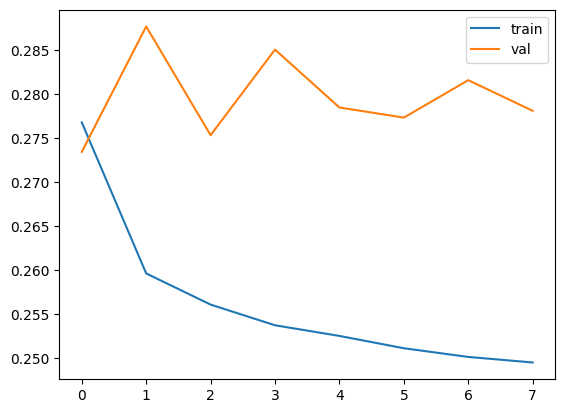

In [33]:
process_and_evaluate1(
    cnn_top50_model,
    X_train, y_train,
    X_test, y_test,
    np.array(df_train1['Ticker_Encoded']), np.array(df_test1['Ticker_Encoded'])
    ,checkpoint_path=rf'{checkpoints_path}\cnn_top50.keras',epochs=40,batch_size=8
)

In [34]:
bi_lstm_top50_model_loaded = tf.keras.models.load_model(rf'{checkpoints_path}\cnn_top50.keras')

In [35]:
pred_probs_test = bi_lstm_top50_model_loaded.predict([ticker_encoded_test, X_test])
pred_probs_train = bi_lstm_top50_model_loaded.predict([ticker_encoded_train, X_train])



338/338 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
1344/1344 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step


In [36]:
np.isnan(pred_probs_test).sum()

np.int64(0)

In [37]:
np.isnan(pred_probs_train).sum()

np.int64(0)

In [38]:

def calculate_metrics1(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':confusion
    }



In [39]:
train_metrics1 = calculate_metrics1(y_train,(pred_probs_train>=0.5).astype(int),pred_probs_train)
test_metrics1 = calculate_metrics1(y_test,(pred_probs_test>=0.5).astype(int),pred_probs_test)

In [40]:
train_metrics_df1 = pd.DataFrame([train_metrics1])
train_metrics_df1['Set'] = "Train"
test_metrics_df1 = pd.DataFrame([test_metrics1])
test_metrics_df1['Set'] = "Test"
model_metrics1 = pd.concat([train_metrics_df1,test_metrics_df1],axis=0)
model_metrics1.reset_index(drop=True,inplace=True)
model_metrics1.head()

,accuracy,roc,precision,recall,f1,confusion_matrix,Set
0,0.925183,0.683900,0.437500,0.002178,0.004334,"[[39762, 9], [3207, 7]]",Train
1,0.945866,0.555889,0.133333,0.003490,0.006803,"[[10202, 13], [571, 2]]",Test


In [41]:
model_name = 'cnn_top50'
top_n = 30

In [42]:
def label_prediction(row, model_name,top_n):
    in_top_50 = row[f'Top_{top_n}_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_50 and target == 1:
        return 'TP'
    elif in_top_50 and target == 0:
        return 'FP'
    elif not in_top_50 and target == 0:
        return 'TN'
    elif not in_top_50 and target == 1:
        return 'FN'

def flag_top50_nlargest(group, pred_prob_col,top_n):
    # If all pred_probs are zero, return all False
    if group[pred_prob_col].sum() == 0:
        return pd.Series([False] * len(group), index=group.index)
    # Use nlargest to get exactly 50
    top50_idx = group[pred_prob_col].nlargest(top_n).index
    flag = pd.Series(False, index=group.index)
    flag.loc[top50_idx] = True
    return flag

def label_prediction1(row, model_name):
    has_more_prob_than_threshold = row[f'Pred_Prob_Threshold_{model_name}']
    target = row['Target']
    
    if has_more_prob_than_threshold and target == 1:
        return 'TP'
    elif has_more_prob_than_threshold and target == 0:
        return 'FP'
    elif not has_more_prob_than_threshold and target == 0:
        return 'TN'
    elif not has_more_prob_than_threshold and target == 1:
        return 'FN'
    
def add_suffix_to_cols(df, suffix, exclude_cols):
    return df.rename(
        columns={col: f"{col}{suffix}" for col in df.columns if col not in exclude_cols + ['Quarter', 'Set']}
    )


In [43]:

if len(set(['Rank','Returns'])-set(df_train1.columns))!=0:
    print("There are no rank and returns columns, merging now..!")
    df_train1 = df_train1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')
    df_test1 = df_test1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')

if np.isnan(pred_probs_train).all():
    print("All predictionsa re NaNs")

df_train_pred = df_train1[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test1[['Ticker','Quarter','Target','Returns','Rank']]

df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)

#### Top30 as fund - irrespective of the prob values
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)



df_pred.reset_index(drop=True,inplace=True)
df_pred.sort_values(by=['Quarter',f'Pred_Prob_{model_name}'],ascending=False,inplace=True)
df_pred[f'Top_{top_n}_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',top_n)

df_pred[f'Top_50_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',50)
# df_pred[(df_pred['Top_{top_n}_Pred_Prob_lstm_top50']==True)&(df_pred['Quarter']=='2005-12-31')]

# test_qtr_preds = df_pred[(df_pred['Quarter']=='2005-12-31')]['Pred_Prob_lstm_top50']
# test_qtr_preds[test_qtr_preds>0.9].shape
df_pred['Pred_Category_Top30'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=30), axis=1)
df_pred['Pred_Category_Top50'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=50), axis=1)
df_pred.reset_index(drop=True,inplace=True)

qtr_summary_df = df_pred.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Top30=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_30_Pred_Prob_{model_name}'] == True].mean()),
                    Avg_Returns_Predicted_Top50=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_50_Pred_Prob_{model_name}'] == True].mean()),
                    Count_TP_Top30=('Pred_Category_Top30', lambda x: (x == 'TP').sum()),
                    Count_TN_Top30=('Pred_Category_Top30', lambda x: (x == 'TN').sum()),
                    Count_FP_Top30=('Pred_Category_Top30', lambda x: (x == 'FP').sum()),
                    Count_FN_Top30=('Pred_Category_Top30', lambda x: (x == 'FN').sum()),
                    Count_TP_Top50=('Pred_Category_Top50', lambda x: (x == 'TP').sum()),
                    Count_TN_Top50=('Pred_Category_Top50', lambda x: (x == 'TN').sum()),
                    Count_FP_Top50=('Pred_Category_Top50', lambda x: (x == 'FP').sum()),
                    Count_FN_Top50=('Pred_Category_Top50', lambda x: (x == 'FN').sum())
                    
                    ).reset_index()

# set_summary_df = qtr_summary_df.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

df_pred1 = df_pred[['Ticker','Quarter','Target','Returns','Rank',f'Pred_Prob_{model_name}','Set']].copy()
df_pred1[f'Pred_Prob_Threshold_{model_name}'] = df_pred1[f'Pred_Prob_{model_name}'].between(0.5,1)



df_pred1['Pred_Category'] = df_pred1.apply(lambda row: label_prediction1(row, model_name=model_name), axis=1)
quarterly_returns_f2 = df_pred1.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Thresh=('Returns', lambda x: x[df_pred1.loc[x.index, f'Pred_Prob_Threshold_{model_name}'] == True].mean()),
                    Count_TP_Thresh=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN_Thresh=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP_Thresh=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN_Thresh=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()

qtr_summary_df2 = pd.DataFrame(quarterly_returns_f2)


#### Actual and Index returns mapping
##### Actual returns
act_returns = df_pred[df_pred['Target']==1].groupby(by='Quarter')['Returns'].mean()
df_act_returns = pd.DataFrame(act_returns)
df_act_returns.reset_index(inplace=True)
df_act_returns.rename(columns={'Returns':'Avg_Returns_Actual'},inplace=True)
qtr_summary_df = qtr_summary_df.merge(df_act_returns,on='Quarter',how='left')

##### Index returns - Qtrly
df_index = pd.read_excel(qtrly_returns_path,sheet_name='Qtrly_Stock_Returns')
df_index1 = df_index[df_index['Ticker'] == 'Nsemcap'].drop(columns=['Industry']).set_index(keys=['Ticker'])
df_index1 = df_index1.T
df_index1.reset_index(inplace=True)
df_index1.rename(columns={'index':'Quarter','Nsemcap':'Index_Returns'},inplace=True)

df_index1['Quarter'] = df_index1['Quarter'].apply(convert_qtr_to_date)
df_index1['Quarter'] = pd.to_datetime(df_index1['Quarter'],dayfirst=True)

qtr_summary_df = qtr_summary_df.merge(df_index1,how='left',on='Quarter')
qtr_summary_df['delta_returns_act_vs_pred_Top30'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top30']
qtr_summary_df['delta_returns_pred_vs_index_Top30'] = qtr_summary_df['Avg_Returns_Predicted_Top30']-qtr_summary_df['Index_Returns']
qtr_summary_df['delta_returns_act_vs_pred_Top50'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top50']
qtr_summary_df['delta_returns_pred_vs_index_Top50'] = qtr_summary_df['Avg_Returns_Predicted_Top50']-qtr_summary_df['Index_Returns']

qtr_summary_df2 = qtr_summary_df2.merge(df_act_returns,on='Quarter',how='left')
qtr_summary_df2 = qtr_summary_df2.merge(df_index1,on='Quarter',how='left')

qtr_summary_df2['delta_returns_act_vs_pred_Thresh'] = qtr_summary_df2['Avg_Returns_Actual']-qtr_summary_df2['Avg_Returns_Predicted_Thresh']
qtr_summary_df2['delta_returns_pred_vs_index_Thresh'] = qtr_summary_df2['Avg_Returns_Predicted_Thresh']-qtr_summary_df2['Index_Returns']


exclude_cols = ['Avg_Returns_Actual', 'Index_Returns']

# Reset index for merge
qtr_summary_df2_reset = qtr_summary_df2.reset_index(drop=True)
qtr_summary_df_reset = qtr_summary_df.reset_index(drop=True)

# Merge as before
merged_qtr_summary = pd.merge(
    qtr_summary_df_reset, qtr_summary_df2_reset,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

# Define the desired column order
ordered_cols = [
    'Quarter','Set',
    'Avg_Returns_Predicted_Top30','Avg_Returns_Predicted_Top50',
    'Avg_Returns_Predicted_Thresh',
    'Avg_Returns_Actual', 'Index_Returns',
    'delta_returns_act_vs_pred_Top30','delta_returns_pred_vs_index_Top30',
    'delta_returns_act_vs_pred_Top50','delta_returns_pred_vs_index_Top50',
    'delta_returns_act_vs_pred_Thresh','delta_returns_pred_vs_index_Thresh',
    'Count_TP_Top30', 'Count_TP_Top50', 'Count_TP_Thresh',
    'Count_TN_Top30', 'Count_TN_Top50', 'Count_TN_Thresh',
    'Count_FP_Top30', 'Count_FP_Top50', 'Count_FP_Thresh',
    'Count_FN_Top30', 'Count_FN_Top50', 'Count_FN_Thresh'
]

# Add any other columns that might exist but are not in the list
ordered_cols += [col for col in merged_qtr_summary.columns if col not in ordered_cols]

# Reorder columns
merged_qtr_summary = merged_qtr_summary[ordered_cols]
# merged_qtr_summary.reset_index(inplace=True)
merged_qtr_summary.head()

C:\Users\43737\AppData\Local\Temp\ipykernel_34640\1919607964.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_34640\1919607964.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_34640\1919607964.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.490058,0.491039,NaN,1.165694,-0.019376,0.675636,0.509434,0.674655,...,0,415,402,438,23,36,0,40,33,47
1,2005-06-30,Train,0.466140,0.352141,NaN,1.375535,0.045476,0.909396,0.420664,1.023394,...,0,414,396,439,25,43,0,41,39,46
2,2005-09-30,Train,-0.031836,-0.020922,NaN,0.426376,0.244277,0.458212,-0.276113,0.447298,...,0,409,393,436,27,43,0,46,42,49
3,2005-12-31,Train,0.070125,0.098629,NaN,0.932621,0.058583,0.862495,0.011542,0.833992,...,0,410,393,437,27,44,0,45,42,48
4,2006-03-31,Train,-0.001601,0.037324,NaN,0.503488,0.187746,0.505089,-0.189347,0.466165,...,0,423,408,441,18,33,0,37,32,49


In [44]:
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].isna().all()

np.False_

In [45]:
merged_qtr_summary.columns

Index(['Quarter', 'Set', 'Avg_Returns_Predicted_Top30',
       'Avg_Returns_Predicted_Top50', 'Avg_Returns_Predicted_Thresh',
       'Avg_Returns_Actual', 'Index_Returns',
       'delta_returns_act_vs_pred_Top30', 'delta_returns_pred_vs_index_Top30',
       'delta_returns_act_vs_pred_Top50', 'delta_returns_pred_vs_index_Top50',
       'delta_returns_act_vs_pred_Thresh',
       'delta_returns_pred_vs_index_Thresh', 'Count_TP_Top30',
       'Count_TP_Top50', 'Count_TP_Thresh', 'Count_TN_Top30', 'Count_TN_Top50',
       'Count_TN_Thresh', 'Count_FP_Top30', 'Count_FP_Top50',
       'Count_FP_Thresh', 'Count_FN_Top30', 'Count_FN_Top50',
       'Count_FN_Thresh'],
      dtype='object')

In [46]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.7033973 , 0.4304681 , 0.37902632, ..., 0.00077015, 0.00076556,
       0.00072408], dtype=float32)

In [47]:
set_summary_df3 =  merged_qtr_summary.groupby('Set').agg(
    Count_TP_Thresh = ('Count_TP_Thresh','sum'),
    Count_TN_Thresh = ('Count_TN_Thresh','sum'),
    Count_FP_Thresh = ('Count_FP_Thresh','sum'),
    Count_FN_Thresh = ('Count_FN_Thresh','sum'),
    Count_TP_Top30 = ('Count_TP_Top30','sum'),
    Count_TN_Top30 = ('Count_TN_Top30','sum'),
    Count_FP_Top30 = ('Count_FP_Top30','sum'),
    Count_FN_Top30 = ('Count_FN_Top30','sum'),
    Count_TP_Top50 = ('Count_TP_Top50','sum'),
    Count_TN_Top50 = ('Count_TN_Top50','sum'),
    Count_FP_Top50 = ('Count_FP_Top50','sum'),
    Count_FN_Top50 = ('Count_FN_Top50','sum')
)
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,2,10202,13,571,31,9886,329,542,46,9661,554,527
Train,7,39762,9,3207,397,38128,1643,2817,628,36999,2772,2586


In [48]:

def calc_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return accuracy, precision, recall, f1


In [49]:
for suffix in ['_Top30','_Top50', '_Thresh']:
    print(f"\nMetrics for {suffix}:")
    for set_name, row in set_summary_df3.iterrows():
        tp = row[f'Count_TP{suffix}']
        tn = row[f'Count_TN{suffix}']
        fp = row[f'Count_FP{suffix}']
        fn = row[f'Count_FN{suffix}']
        accuracy, precision, recall, f1 = calc_metrics(tp, tn, fp, fn)
        print(f"{set_name}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")


Metrics for _Top30:
Test: accuracy=0.9193, precision=0.0861, recall=0.0541, f1=0.0665
Train: accuracy=0.8962, precision=0.1946, recall=0.1235, f1=0.1511

Metrics for _Top50:
Test: accuracy=0.8998, precision=0.0767, recall=0.0803, f1=0.0784
Train: accuracy=0.8754, precision=0.1847, recall=0.1954, f1=0.1899

Metrics for _Thresh:
Test: accuracy=0.9459, precision=0.1333, recall=0.0035, f1=0.0068
Train: accuracy=0.9252, precision=0.4375, recall=0.0022, f1=0.0043


In [50]:
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean():
    print("Both the stock picking strategies (Top 30 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 30 and Top 50) have same returns")
else:
    print("All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns")

All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns


In [51]:
merged_qtr_summary[merged_qtr_summary['Avg_Returns_Predicted_Top30'].isna()].shape

(2, 25)

In [52]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.7033973 , 0.4304681 , 0.37902632, ..., 0.00077015, 0.00076556,
       0.00072408], dtype=float32)

In [53]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].describe()

count    10788.000000
mean         0.083765
std          0.065669
min          0.000724
25%          0.039472
50%          0.071347
75%          0.116766
max          0.999878
Name: Pred_Prob_cnn_top50, dtype: float64

In [54]:
merged_qtr_summary['Quarter'].is_monotonic_increasing

True

In [55]:
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,2,10202,13,571,31,9886,329,542,46,9661,554,527
Train,7,39762,9,3207,397,38128,1643,2817,628,36999,2772,2586


In [56]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'] = merged_qtr_summary['Avg_Returns_Predicted_Top30'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top50'] = merged_qtr_summary['Avg_Returns_Predicted_Top50'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Thresh'] = merged_qtr_summary['Avg_Returns_Predicted_Thresh'].ffill()

In [57]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Top50'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].fillna(0,inplace=True)

C:\Users\43737\AppData\Local\Temp\ipykernel_34640\4263771019.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
C:\Users\43737\AppData\Local\Temp\ipykernel_34640\4263771019.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beh

In [58]:
merged_qtr_summary.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.490058,0.491039,0.0,1.165694,-0.019376,0.675636,0.509434,0.674655,...,0,415,402,438,23,36,0,40,33,47
1,2005-06-30,Train,0.466140,0.352141,0.0,1.375535,0.045476,0.909396,0.420664,1.023394,...,0,414,396,439,25,43,0,41,39,46
2,2005-09-30,Train,-0.031836,-0.020922,0.0,0.426376,0.244277,0.458212,-0.276113,0.447298,...,0,409,393,436,27,43,0,46,42,49
3,2005-12-31,Train,0.070125,0.098629,0.0,0.932621,0.058583,0.862495,0.011542,0.833992,...,0,410,393,437,27,44,0,45,42,48
4,2006-03-31,Train,-0.001601,0.037324,0.0,0.503488,0.187746,0.505089,-0.189347,0.466165,...,0,423,408,441,18,33,0,37,32,49


In [59]:
df_pred.head()

,Ticker,Quarter,Target,Returns,Rank,Pred_Prob_cnn_top50,Set,Top_30_Pred_Prob_cnn_top50,Top_50_Pred_Prob_cnn_top50,Pred_Category_Top30,Pred_Category_Top50
0,adanigr,2024-12-31,0,-0.088450,240.0,0.703397,Test,True,True,FP,FP
1,uel,2024-12-31,0,NaN,NaN,0.430468,Test,True,True,FP,FP
2,aiil,2024-12-31,0,0.015105,101.0,0.379026,Test,True,True,FP,FP
3,sbglp,2024-12-31,0,-0.732508,803.0,0.378447,Test,True,True,FP,FP
4,jinw,2024-12-31,0,-0.099205,265.0,0.279209,Test,True,True,FP,FP


In [60]:
qtr_summary_df.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
0,2005-03-31,Train,0.490058,0.491039,7,415,23,40,14,402,36,33,1.165694,-0.019376,0.675636,0.509434,0.674655,0.510414
1,2005-06-30,Train,0.466140,0.352141,5,414,25,41,7,396,43,39,1.375535,0.045476,0.909396,0.420664,1.023394,0.306666
2,2005-09-30,Train,-0.031836,-0.020922,3,409,27,46,7,393,43,42,0.426376,0.244277,0.458212,-0.276113,0.447298,-0.265199
3,2005-12-31,Train,0.070125,0.098629,3,410,27,45,6,393,44,42,0.932621,0.058583,0.862495,0.011542,0.833992,0.040045
4,2006-03-31,Train,-0.001601,0.037324,12,423,18,37,17,408,33,32,0.503488,0.187746,0.505089,-0.189347,0.466165,-0.150422


In [61]:
qtr_summary_df['Set'].value_counts()

Set
Train    68
Test     12
Name: count, dtype: int64

In [62]:
with pd.ExcelWriter(r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\results\lag\top50\3yrs_as_test_data_ts\Pred_Vs_Act_CNN_time_split_25_07_2025.xlsx", ) as writer:
    merged_qtr_summary.to_excel(writer, sheet_name='Qtr_Summary', index=False)
    qtr_summary_df.to_excel(writer, sheet_name='Qtr_Summary_Top', index=False)
    qtr_summary_df2.to_excel(writer, sheet_name='Qtr_Summary_Thresh', index=False)
    df_pred.to_excel(writer, sheet_name='Pred_Vs_Act_Top', index=False)
    df_pred1.to_excel(writer, sheet_name='Pred_Vs_Act_Thresh', index=False)
    set_summary_df3.to_excel(writer, sheet_name='Set_Summary')

### Top50 xform

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Flatten, Concatenate, Reshape, RepeatVector
from tensorflow.keras.models import Model
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,roc_auc_score
from tensorflow.keras.metrics import AUC, Precision
import os
from scipy.stats import skew

In [2]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [3]:
train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
test_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\test_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
master_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

df_train = pd.read_excel(train_data_path)
df_test = pd.read_excel(test_data_path)
df_master = pd.read_excel(master_data_path)
qtrly_returns_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\lag\Quarterly_Price_Returns_Labels.xlsx"

In [4]:
df_train.reset_index(drop=True,inplace=True)
df_test.reset_index(drop=True,inplace=True)

In [5]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

In [6]:
print(df_train['Quarter'].dtypes,df_test['Quarter'].dtypes,df_master['Quarter'].dtypes)

datetime64[ns] datetime64[ns] object


In [7]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [8]:
df_train = df_train.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])
df_test = df_test.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])

In [9]:
df_train[df_train['Target']==1]['Rank'].max()

np.float64(860.0)

In [10]:
df_train['Target'] = np.where(df_train['Rank']<=50,1,0)
df_test['Target'] = np.where(df_test['Rank']<=50,1,0)

In [11]:
vif_cols = list(df_train.columns)
for col in ['Ticker','Quarter','Set','Returns','Rank','Target']:
    if col in vif_cols:
        vif_cols.remove(col)

In [12]:
vif_cols

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [13]:
skewness = df_train[vif_cols].apply(lambda x: skew(x.dropna()))

In [14]:
skewness

TMR               13.086663
Momentum          12.412323
Beta               5.806239
Alpha             23.272412
EP                16.510138
BP               111.210752
SP                49.816550
Dividend_Flag     -1.256040
DE                37.320149
EPS              -40.005117
Zscore             2.836515
dtype: float64

In [15]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox

for col in vif_cols:
    x = df_train[col].dropna()
    print(f"\nFeature: {col}")
    print(f"Original skewness: {skew(x)}")
    if (x <= 0).any():
        # Use Yeo-Johnson for non-positive data
        pt = PowerTransformer(method='yeo-johnson')
        x_trans = pt.fit_transform(x.values.reshape(-1, 1)).flatten()
        print(f"Yeo-Johnson skewness: {skew(x_trans)}")
    else:
        # Try log and Box-Cox for positive data
        x_log = np.log1p(x)
        print(f"log1p skewness: {skew(x_log)}")
        x_bc, _ = boxcox(x)
        print(f"Box-Cox skewness: {skew(x_bc)}")
# ...existing code...


Feature: TMR
Original skewness: 13.086662785414012
Yeo-Johnson skewness: 1.3741422367307328

Feature: Momentum
Original skewness: 12.412322770259664
Yeo-Johnson skewness: -0.37304497754437993

Feature: Beta
Original skewness: 5.8062388351951615
Yeo-Johnson skewness: 4.617342875794953

Feature: Alpha
Original skewness: 23.272412041065202
Yeo-Johnson skewness: -2.9388817602113577

Feature: EP
Original skewness: 16.51013828757582
log1p skewness: 7.797053632006263
Box-Cox skewness: 0.11026200411795387

Feature: BP
Original skewness: 111.2107515117538
Yeo-Johnson skewness: 0.20590787331072397

Feature: SP
Original skewness: 49.8165504035785
log1p skewness: 2.490688401374147
Box-Cox skewness: 0.044374265589872564

Feature: Dividend_Flag
Original skewness: -1.2560396990530387
Yeo-Johnson skewness: -1.2560396990530391

Feature: DE
Original skewness: 37.32014887171092
Yeo-Johnson skewness: 0.04913837052975297

Feature: EPS
Original skewness: -40.00511654482117
Yeo-Johnson skewness: 1.696789070

In [16]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox
import numpy as np

best_transform_map = {}
for col in vif_cols:
    x = df_train[col].dropna()
    results = {}
    if (x <= 0).any():
        # Only Yeo-Johnson possible
        pt = PowerTransformer(method='yeo-johnson')
        x_yj = pt.fit_transform(x.values.reshape(-1, 1)).flatten()
        results['yeo-johnson'] = abs(skew(x_yj))
    else:
        x_log = np.log1p(x)
        results['log1p'] = abs(skew(x_log))
        try:
            x_bc, _ = boxcox(x)
            results['boxcox'] = abs(skew(x_bc))
        except Exception:
            results['boxcox'] = np.nan
    # Always include original for comparison
    results['original'] = abs(skew(x))
    # Pick the transform with minimum absolute skewness
    best = min(results, key=lambda k: results[k] if not np.isnan(results[k]) else np.inf)
    best_transform_map[col] = best
    print(f"{col}: Best transform = {best}, skewness = {results[best]:.3f}")
# ...existing code...

TMR: Best transform = yeo-johnson, skewness = 1.374
Momentum: Best transform = yeo-johnson, skewness = 0.373
Beta: Best transform = yeo-johnson, skewness = 4.617
Alpha: Best transform = yeo-johnson, skewness = 2.939
EP: Best transform = boxcox, skewness = 0.110
BP: Best transform = yeo-johnson, skewness = 0.206
SP: Best transform = boxcox, skewness = 0.044
Dividend_Flag: Best transform = original, skewness = 1.256
DE: Best transform = yeo-johnson, skewness = 0.049
EPS: Best transform = yeo-johnson, skewness = 1.697
Zscore: Best transform = yeo-johnson, skewness = 0.086


In [17]:
df_test.replace([np.inf, -np.inf], 0, inplace=True)

#### Power xforms

In [18]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox
import numpy as np

# 1. Decide best transform for each feature based on your previous results
# best_transform_map = {
#     'TMR': 'yeo-johnson',
#     'Momentum': 'yeo-johnson',
#     'Beta': 'yeo-johnson',
#     'Alpha': 'yeo-johnson',
#     'EP': 'boxcox',
#     'BP': 'yeo-johnson',
#     'SP': 'boxcox',
#     'EPS': 'yeo-johnson',
#     'Zscore': 'yeo-johnson',
#     'FCF': 'yeo-johnson',
#     'ICR': 'yeo-johnson',
#     'Year': 'log1p',
#     'Quarter_number': 'boxcox',  # or 'log1p', both are close
#     # 'Target': 'none',  # Target is not a feature
# }
best_transform_map = {
    'TMR': 'yeo-johnson',
    'Momentum': 'yeo-johnson',
    'Beta': 'yeo-johnson',
    'Alpha': 'yeo-johnson',
    'EP': 'boxcox',
    'BP': 'yeo-johnson',
    'SP': 'boxcox',
    'EPS': 'yeo-johnson',
    'Zscore': 'yeo-johnson',
    'DE': 'yeo-johnson', # Added based on your result
    
    # Keep these commented as they were not in your latest results:
    # 'FCF': 'yeo-johnson',
    # 'ICR': 'yeo-johnson',
    # 'Year': 'log1p',
    # 'Quarter_number': 'boxcox',
}
def transform_feature(col, x, method):
    if method == 'yeo-johnson':
        pt = PowerTransformer(method='yeo-johnson')
        return pt.fit_transform(x.values.reshape(-1, 1)).flatten()
    elif method == 'boxcox':
        # Box-Cox requires strictly positive values
        # Add a small constant if min(x) == 0
        x_pos = x.copy()
        if (x_pos <= 0).any():
            x_pos = x_pos - x_pos.min() + 1e-6
        return boxcox(x_pos)[0]
    elif method == 'log1p':
        x_pos = x.copy()
        if (x_pos < 0).any():
            x_pos = x_pos - x_pos.min() + 1e-6
        return np.log1p(x_pos)
    else:
        return x.values

# 2. Apply transforms to train and test
df_train_trans = df_train.copy()
df_test_trans = df_test.copy()

for col in vif_cols:
    method = best_transform_map.get(col, 'none')
    if method != 'none':
        df_train_trans[col] = transform_feature(col, df_train[col], method)
        df_test_trans[col] = transform_feature(col, df_test[col], method)

# 3. Scaling
scaler = StandardScaler()
train_data = scaler.fit_transform(df_train_trans[vif_cols])
test_data = scaler.transform(df_test_trans[vif_cols])

df_train1 = pd.DataFrame(train_data, columns=vif_cols)
df_test1 = pd.DataFrame(test_data, columns=vif_cols)

for col in ['Ticker', 'Target', 'Quarter']:
    df_train1[col] = df_train[col]
    df_test1[col] = df_test[col]

# 4. Prepare X_train, y_train, X_test, y_test
features = vif_cols.copy()
X_train = df_train1[features].values
y_train = df_train1['Target'].values
X_test = df_test1[features].values
y_test = df_test1['Target'].values

# If your model expects 3D input (samples, timesteps, features):
# X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
# X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
# ...existing code...

X_train shape: (42985, 11)
y_train shape: (42985,)
X_test shape: (10788, 11)
y_test shape: (10788,)


In [19]:
check = pd.Series(y_train)
check.unique()

array([0, 1])

In [20]:


# 1. Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the La
# belEncoder on the entire set of unique labels across train, validation, and test data
all_tickers = pd.concat([df_train1['Ticker'], df_test1['Ticker']]).unique()
label_encoder.fit(all_tickers)

LabelEncoder()

In [21]:
df_train1['Ticker_Encoded'] = label_encoder.transform(df_train1['Ticker'])
df_test1['Ticker_Encoded'] = label_encoder.transform(df_test1['Ticker'])

In [22]:
def create_ticker_embedding(input_dim, output_dim):
    return Embedding(input_dim=input_dim, output_dim=output_dim, input_length=1)

In [23]:
# Now, the LabelEncoder is aware of all the possible tickers in all datasets
embedding_size = len(df_train1['Ticker_Encoded'].unique())  # Size of the embedding

# You can now proceed with creating your ticker embedding layer and other steps
ticker_embedding_layer = create_ticker_embedding(input_dim=embedding_size, output_dim=10)


d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [24]:
features = vif_cols.copy()
features.append("Quarter")

In [25]:
ticker_encoded_train = df_train1['Ticker_Encoded'].values
ticker_encoded_test = df_test1['Ticker_Encoded'].values

#### Model Definition

In [26]:

def calculate_metrics(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':f'{confusion}'
    }


def process_and_evaluate1(model, X_train, y_train,X_test, y_test, ticker_encoded_train,ticker_encoded_test,epochs,checkpoint_path,batch_size,k=5):
    
    
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    for train_index, val_index in kf.split(X_train):
        X_train1, X_val = X_train[train_index], X_train[val_index]
        y_train1, y_val = y_train[train_index], y_train[val_index]
        ticker_train, ticker_val = ticker_encoded_train[train_index], ticker_encoded_train[val_index]

    early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                    save_weights_only=False,save_freq=epochs*batch_size,
                                                    verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.35, patience=5, min_lr=1e-6, verbose=1)
    history = model.fit([ticker_train, X_train1], y_train1,
            validation_data=([ticker_val, X_val], y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[early_stop, reduce_lr, cp_callback], verbose=0)

    # history = model.fit([ticker_encoded_train, X_train], y_train, epochs=epochs, batch_size=batch_size, validation_data=([ticker_encoded_test, X_test], y_test),callbacks=[cp_callback,early_stop])
    # model.load_weights(checkpoint_path)

    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.legend()
    

#### CNN

In [27]:
from tensorflow.keras.layers import Input, Embedding, Flatten, RepeatVector, Concatenate, Conv1D, GlobalAveragePooling1D, Dense, Reshape
from tensorflow.keras.models import Model
from tensorflow.keras.metrics import AUC, Precision

def build_cnn_top50_xform_model(input_shape, embedding_size, num_tickers):
    continuous_input = Input(shape=input_shape[1:], name="continuous_input")  # shape: (11,)
    ticker_input = Input(shape=(1,), name="ticker_input")

    # Ticker embedding
    ticker_embedding = Embedding(input_dim=num_tickers, output_dim=embedding_size)(ticker_input)
    ticker_embedding = Flatten()(ticker_embedding)
    ticker_embedding = RepeatVector(input_shape[1])(ticker_embedding)  # shape: (None, 11, embedding_size)

    # Reshape continuous input to match dimensions
    reshaped_continuous = Reshape((input_shape[1], 1))(continuous_input)  # shape: (None, 11, 1)

    # Merge inputs
    merged = Concatenate(axis=2)([ticker_embedding, reshaped_continuous])  # shape: (None, 11, embedding_size + 1)

    # CNN layers
    x = Conv1D(filters=64, kernel_size=1, activation='relu')(merged)
    x = GlobalAveragePooling1D()(x)
    output = Dense(1, activation='sigmoid')(x)

    model = Model(inputs=[ticker_input, continuous_input], outputs=output)
    return model


In [28]:
num_tickers = len(label_encoder.classes_)

In [29]:

# Define cnn model
cnn_top50_xform_model = build_cnn_top50_xform_model(X_train.shape, embedding_size, num_tickers)
cnn_top50_xform_model.compile(optimizer='adam', 
                   loss='binary_crossentropy',  # Binary classification problem
                   metrics=[AUC(),Precision()])

In [30]:
X_train.shape

(42985, 11)

In [32]:
checkpoints_path = r"D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts"


Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top50_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top50_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top50_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top50_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top50_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top50_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top50_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top50_xform.keras

Epoch 3: saving model to D:\Python\Final Quant Fund\Quant Fund\

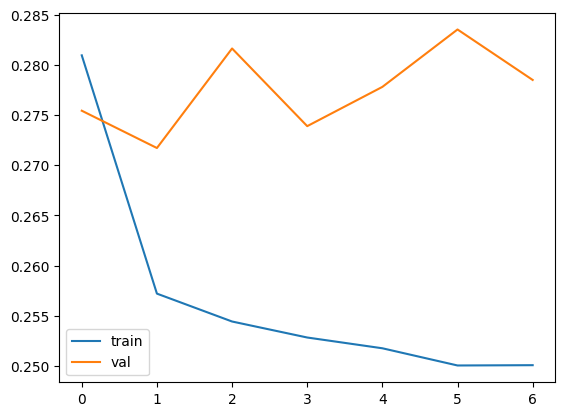

In [33]:
process_and_evaluate1(
    cnn_top50_xform_model,
    X_train, y_train,
    X_test, y_test,
    np.array(df_train1['Ticker_Encoded']), np.array(df_test1['Ticker_Encoded'])
    ,checkpoint_path=rf'{checkpoints_path}\cnn_top50_xform.keras',epochs=30,batch_size=16
)

In [34]:
cnn_top50_xform_model_loaded = tf.keras.models.load_model(rf'{checkpoints_path}\cnn_top50_xform.keras')

In [35]:
pred_probs_test = cnn_top50_xform_model_loaded.predict([ticker_encoded_test, X_test])
pred_probs_train = cnn_top50_xform_model_loaded.predict([ticker_encoded_train, X_train])



338/338 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
1344/1344 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step


In [36]:
np.isnan(pred_probs_test).sum()

np.int64(0)

In [37]:
np.isnan(pred_probs_train).sum()

np.int64(0)

In [38]:

def calculate_metrics1(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':confusion
    }



In [39]:
train_metrics1 = calculate_metrics1(y_train,(pred_probs_train>=0.5).astype(int),pred_probs_train)
test_metrics1 = calculate_metrics1(y_test,(pred_probs_test>=0.5).astype(int),pred_probs_test)

d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [40]:
train_metrics_df1 = pd.DataFrame([train_metrics1])
train_metrics_df1['Set'] = "Train"
test_metrics_df1 = pd.DataFrame([test_metrics1])
test_metrics_df1['Set'] = "Test"
model_metrics1 = pd.concat([train_metrics_df1,test_metrics_df1],axis=0)
model_metrics1.reset_index(drop=True,inplace=True)
model_metrics1.head()

,accuracy,roc,precision,recall,f1,confusion_matrix,Set
0,0.925276,0.683915,0.666667,0.001245,0.002484,"[[39769, 2], [3210, 4]]",Train
1,0.946885,0.559862,0.000000,0.000000,0.000000,"[[10215, 0], [573, 0]]",Test


In [41]:
model_name = 'cnn_top50_xform'
top_n = 30

In [42]:
def label_prediction(row, model_name,top_n):
    in_top_50 = row[f'Top_{top_n}_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_50 and target == 1:
        return 'TP'
    elif in_top_50 and target == 0:
        return 'FP'
    elif not in_top_50 and target == 0:
        return 'TN'
    elif not in_top_50 and target == 1:
        return 'FN'

def flag_top50_nlargest(group, pred_prob_col,top_n):
    # If all pred_probs are zero, return all False
    if group[pred_prob_col].sum() == 0:
        return pd.Series([False] * len(group), index=group.index)
    # Use nlargest to get exactly 50
    top50_idx = group[pred_prob_col].nlargest(top_n).index
    flag = pd.Series(False, index=group.index)
    flag.loc[top50_idx] = True
    return flag

def label_prediction1(row, model_name):
    has_more_prob_than_threshold = row[f'Pred_Prob_Threshold_{model_name}']
    target = row['Target']
    
    if has_more_prob_than_threshold and target == 1:
        return 'TP'
    elif has_more_prob_than_threshold and target == 0:
        return 'FP'
    elif not has_more_prob_than_threshold and target == 0:
        return 'TN'
    elif not has_more_prob_than_threshold and target == 1:
        return 'FN'
    
def add_suffix_to_cols(df, suffix, exclude_cols):
    return df.rename(
        columns={col: f"{col}{suffix}" for col in df.columns if col not in exclude_cols + ['Quarter', 'Set']}
    )


In [43]:

if len(set(['Rank','Returns'])-set(df_train1.columns))!=0:
    print("There are no rank and returns columns, merging now..!")
    df_train1 = df_train1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')
    df_test1 = df_test1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')

if np.isnan(pred_probs_train).all():
    print("All predictionsa re NaNs")

df_train_pred = df_train1[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test1[['Ticker','Quarter','Target','Returns','Rank']]

df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)

#### Top30 as fund - irrespective of the prob values
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)



df_pred.reset_index(drop=True,inplace=True)
df_pred.sort_values(by=['Quarter',f'Pred_Prob_{model_name}'],ascending=False,inplace=True)
df_pred[f'Top_{top_n}_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',top_n)

df_pred[f'Top_50_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',50)
# df_pred[(df_pred['Top_{top_n}_Pred_Prob_lstm_top50']==True)&(df_pred['Quarter']=='2005-12-31')]

# test_qtr_preds = df_pred[(df_pred['Quarter']=='2005-12-31')]['Pred_Prob_lstm_top50']
# test_qtr_preds[test_qtr_preds>0.9].shape
df_pred['Pred_Category_Top30'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=30), axis=1)
df_pred['Pred_Category_Top50'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=50), axis=1)
df_pred.reset_index(drop=True,inplace=True)

qtr_summary_df = df_pred.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Top30=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_30_Pred_Prob_{model_name}'] == True].mean()),
                    Avg_Returns_Predicted_Top50=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_50_Pred_Prob_{model_name}'] == True].mean()),
                    Count_TP_Top30=('Pred_Category_Top30', lambda x: (x == 'TP').sum()),
                    Count_TN_Top30=('Pred_Category_Top30', lambda x: (x == 'TN').sum()),
                    Count_FP_Top30=('Pred_Category_Top30', lambda x: (x == 'FP').sum()),
                    Count_FN_Top30=('Pred_Category_Top30', lambda x: (x == 'FN').sum()),
                    Count_TP_Top50=('Pred_Category_Top50', lambda x: (x == 'TP').sum()),
                    Count_TN_Top50=('Pred_Category_Top50', lambda x: (x == 'TN').sum()),
                    Count_FP_Top50=('Pred_Category_Top50', lambda x: (x == 'FP').sum()),
                    Count_FN_Top50=('Pred_Category_Top50', lambda x: (x == 'FN').sum())
                    
                    ).reset_index()

# set_summary_df = qtr_summary_df.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

df_pred1 = df_pred[['Ticker','Quarter','Target','Returns','Rank',f'Pred_Prob_{model_name}','Set']].copy()
df_pred1[f'Pred_Prob_Threshold_{model_name}'] = df_pred1[f'Pred_Prob_{model_name}'].between(0.5,1)



df_pred1['Pred_Category'] = df_pred1.apply(lambda row: label_prediction1(row, model_name=model_name), axis=1)
quarterly_returns_f2 = df_pred1.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Thresh=('Returns', lambda x: x[df_pred1.loc[x.index, f'Pred_Prob_Threshold_{model_name}'] == True].mean()),
                    Count_TP_Thresh=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN_Thresh=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP_Thresh=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN_Thresh=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()

qtr_summary_df2 = pd.DataFrame(quarterly_returns_f2)


#### Actual and Index returns mapping
##### Actual returns
act_returns = df_pred[df_pred['Target']==1].groupby(by='Quarter')['Returns'].mean()
df_act_returns = pd.DataFrame(act_returns)
df_act_returns.reset_index(inplace=True)
df_act_returns.rename(columns={'Returns':'Avg_Returns_Actual'},inplace=True)
qtr_summary_df = qtr_summary_df.merge(df_act_returns,on='Quarter',how='left')

##### Index returns - Qtrly
df_index = pd.read_excel(qtrly_returns_path,sheet_name='Qtrly_Stock_Returns')
df_index1 = df_index[df_index['Ticker'] == 'Nsemcap'].drop(columns=['Industry']).set_index(keys=['Ticker'])
df_index1 = df_index1.T
df_index1.reset_index(inplace=True)
df_index1.rename(columns={'index':'Quarter','Nsemcap':'Index_Returns'},inplace=True)

df_index1['Quarter'] = df_index1['Quarter'].apply(convert_qtr_to_date)
df_index1['Quarter'] = pd.to_datetime(df_index1['Quarter'],dayfirst=True)

qtr_summary_df = qtr_summary_df.merge(df_index1,how='left',on='Quarter')
qtr_summary_df['delta_returns_act_vs_pred_Top30'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top30']
qtr_summary_df['delta_returns_pred_vs_index_Top30'] = qtr_summary_df['Avg_Returns_Predicted_Top30']-qtr_summary_df['Index_Returns']
qtr_summary_df['delta_returns_act_vs_pred_Top50'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top50']
qtr_summary_df['delta_returns_pred_vs_index_Top50'] = qtr_summary_df['Avg_Returns_Predicted_Top50']-qtr_summary_df['Index_Returns']

qtr_summary_df2 = qtr_summary_df2.merge(df_act_returns,on='Quarter',how='left')
qtr_summary_df2 = qtr_summary_df2.merge(df_index1,on='Quarter',how='left')

qtr_summary_df2['delta_returns_act_vs_pred_Thresh'] = qtr_summary_df2['Avg_Returns_Actual']-qtr_summary_df2['Avg_Returns_Predicted_Thresh']
qtr_summary_df2['delta_returns_pred_vs_index_Thresh'] = qtr_summary_df2['Avg_Returns_Predicted_Thresh']-qtr_summary_df2['Index_Returns']


exclude_cols = ['Avg_Returns_Actual', 'Index_Returns']

# Reset index for merge
qtr_summary_df2_reset = qtr_summary_df2.reset_index(drop=True)
qtr_summary_df_reset = qtr_summary_df.reset_index(drop=True)

# Merge as before
merged_qtr_summary = pd.merge(
    qtr_summary_df_reset, qtr_summary_df2_reset,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

# Define the desired column order
ordered_cols = [
    'Quarter','Set',
    'Avg_Returns_Predicted_Top30','Avg_Returns_Predicted_Top50',
    'Avg_Returns_Predicted_Thresh',
    'Avg_Returns_Actual', 'Index_Returns',
    'delta_returns_act_vs_pred_Top30','delta_returns_pred_vs_index_Top30',
    'delta_returns_act_vs_pred_Top50','delta_returns_pred_vs_index_Top50',
    'delta_returns_act_vs_pred_Thresh','delta_returns_pred_vs_index_Thresh',
    'Count_TP_Top30', 'Count_TP_Top50', 'Count_TP_Thresh',
    'Count_TN_Top30', 'Count_TN_Top50', 'Count_TN_Thresh',
    'Count_FP_Top30', 'Count_FP_Top50', 'Count_FP_Thresh',
    'Count_FN_Top30', 'Count_FN_Top50', 'Count_FN_Thresh'
]

# Add any other columns that might exist but are not in the list
ordered_cols += [col for col in merged_qtr_summary.columns if col not in ordered_cols]

# Reorder columns
merged_qtr_summary = merged_qtr_summary[ordered_cols]
# merged_qtr_summary.reset_index(inplace=True)
merged_qtr_summary.head()

There are no rank and returns columns, merging now..!


C:\Users\43737\AppData\Local\Temp\ipykernel_34636\1919607964.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_34636\1919607964.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_34636\1919607964.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.599431,0.531543,NaN,1.165694,-0.019376,0.566263,0.618806,0.634151,...,0,417,402,438,21,36,0,38,33,47
1,2005-06-30,Train,0.388528,0.406210,NaN,1.375535,0.045476,0.987007,0.343052,0.969326,...,0,414,398,439,25,41,0,41,37,46
2,2005-09-30,Train,-0.006414,-0.038839,NaN,0.426376,0.244277,0.432790,-0.250691,0.465215,...,0,409,391,436,27,45,0,46,44,49
3,2005-12-31,Train,0.105029,0.139579,NaN,0.932621,0.058583,0.827592,0.046446,0.793042,...,0,411,394,437,26,43,0,44,41,48
4,2006-03-31,Train,-0.078327,-0.074323,NaN,0.503488,0.187746,0.581816,-0.266073,0.577811,...,0,419,404,441,22,37,0,41,36,49


In [44]:
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].isna().all()

np.False_

In [45]:
merged_qtr_summary.columns

Index(['Quarter', 'Set', 'Avg_Returns_Predicted_Top30',
       'Avg_Returns_Predicted_Top50', 'Avg_Returns_Predicted_Thresh',
       'Avg_Returns_Actual', 'Index_Returns',
       'delta_returns_act_vs_pred_Top30', 'delta_returns_pred_vs_index_Top30',
       'delta_returns_act_vs_pred_Top50', 'delta_returns_pred_vs_index_Top50',
       'delta_returns_act_vs_pred_Thresh',
       'delta_returns_pred_vs_index_Thresh', 'Count_TP_Top30',
       'Count_TP_Top50', 'Count_TP_Thresh', 'Count_TN_Top30', 'Count_TN_Top50',
       'Count_TN_Thresh', 'Count_FP_Top30', 'Count_FP_Top50',
       'Count_FP_Thresh', 'Count_FN_Top30', 'Count_FN_Top50',
       'Count_FN_Thresh'],
      dtype='object')

In [46]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([3.6602327e-01, 2.5472388e-01, 2.4735542e-01, ..., 3.7066813e-04,
       3.6849431e-04, 3.3530954e-04], dtype=float32)

In [47]:
set_summary_df3 =  merged_qtr_summary.groupby('Set').agg(
    Count_TP_Thresh = ('Count_TP_Thresh','sum'),
    Count_TN_Thresh = ('Count_TN_Thresh','sum'),
    Count_FP_Thresh = ('Count_FP_Thresh','sum'),
    Count_FN_Thresh = ('Count_FN_Thresh','sum'),
    Count_TP_Top30 = ('Count_TP_Top30','sum'),
    Count_TN_Top30 = ('Count_TN_Top30','sum'),
    Count_FP_Top30 = ('Count_FP_Top30','sum'),
    Count_FN_Top30 = ('Count_FN_Top30','sum'),
    Count_TP_Top50 = ('Count_TP_Top50','sum'),
    Count_TN_Top50 = ('Count_TN_Top50','sum'),
    Count_FP_Top50 = ('Count_FP_Top50','sum'),
    Count_FN_Top50 = ('Count_FN_Top50','sum')
)
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,0,10215,0,573,38,9893,322,535,62,9677,538,511
Train,4,39769,2,3210,399,38130,1641,2815,605,36976,2795,2609


In [48]:

def calc_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return accuracy, precision, recall, f1


In [49]:
for suffix in ['_Top30','_Top50', '_Thresh']:
    print(f"\nMetrics for {suffix}:")
    for set_name, row in set_summary_df3.iterrows():
        tp = row[f'Count_TP{suffix}']
        tn = row[f'Count_TN{suffix}']
        fp = row[f'Count_FP{suffix}']
        fn = row[f'Count_FN{suffix}']
        accuracy, precision, recall, f1 = calc_metrics(tp, tn, fp, fn)
        print(f"{set_name}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")


Metrics for _Top30:
Test: accuracy=0.9206, precision=0.1056, recall=0.0663, f1=0.0815
Train: accuracy=0.8963, precision=0.1956, recall=0.1241, f1=0.1519

Metrics for _Top50:
Test: accuracy=0.9028, precision=0.1033, recall=0.1082, f1=0.1057
Train: accuracy=0.8743, precision=0.1779, recall=0.1882, f1=0.1829

Metrics for _Thresh:
Test: accuracy=0.9469, precision=0.0000, recall=0.0000, f1=0.0000
Train: accuracy=0.9253, precision=0.6667, recall=0.0012, f1=0.0025


In [50]:
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean():
    print("Both the stock picking strategies (Top 30 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 30 and Top 50) have same returns")
else:
    print("All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns")

All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns


In [51]:
merged_qtr_summary[merged_qtr_summary['Avg_Returns_Predicted_Top30'].isna()].shape

(2, 25)

In [52]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([3.6602327e-01, 2.5472388e-01, 2.4735542e-01, ..., 3.7066813e-04,
       3.6849431e-04, 3.3530954e-04], dtype=float32)

In [53]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].describe()

count    10788.000000
mean         0.074803
std          0.053658
min          0.000300
25%          0.034272
50%          0.066847
75%          0.108363
max          0.442680
Name: Pred_Prob_cnn_top50_xform, dtype: float64

In [54]:
merged_qtr_summary['Quarter'].is_monotonic_increasing

True

In [55]:
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,0,10215,0,573,38,9893,322,535,62,9677,538,511
Train,4,39769,2,3210,399,38130,1641,2815,605,36976,2795,2609


In [56]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'] = merged_qtr_summary['Avg_Returns_Predicted_Top30'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top50'] = merged_qtr_summary['Avg_Returns_Predicted_Top50'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Thresh'] = merged_qtr_summary['Avg_Returns_Predicted_Thresh'].ffill()

In [57]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Top50'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].fillna(0,inplace=True)

C:\Users\43737\AppData\Local\Temp\ipykernel_34636\4263771019.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
C:\Users\43737\AppData\Local\Temp\ipykernel_34636\4263771019.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beh

In [58]:
merged_qtr_summary.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.599431,0.531543,0.0,1.165694,-0.019376,0.566263,0.618806,0.634151,...,0,417,402,438,21,36,0,38,33,47
1,2005-06-30,Train,0.388528,0.406210,0.0,1.375535,0.045476,0.987007,0.343052,0.969326,...,0,414,398,439,25,41,0,41,37,46
2,2005-09-30,Train,-0.006414,-0.038839,0.0,0.426376,0.244277,0.432790,-0.250691,0.465215,...,0,409,391,436,27,45,0,46,44,49
3,2005-12-31,Train,0.105029,0.139579,0.0,0.932621,0.058583,0.827592,0.046446,0.793042,...,0,411,394,437,26,43,0,44,41,48
4,2006-03-31,Train,-0.078327,-0.074323,0.0,0.503488,0.187746,0.581816,-0.266073,0.577811,...,0,419,404,441,22,37,0,41,36,49


In [59]:
df_pred.head()

,Ticker,Quarter,Target,Returns,Rank,Pred_Prob_cnn_top50_xform,Set,Top_30_Pred_Prob_cnn_top50_xform,Top_50_Pred_Prob_cnn_top50_xform,Pred_Category_Top30,Pred_Category_Top50
0,adanigr,2024-12-31,0,-0.088450,240.0,0.366023,Test,True,True,FP,FP
1,aiil,2024-12-31,0,0.015105,101.0,0.254724,Test,True,True,FP,FP
2,manorama,2024-12-31,0,-0.013804,132.0,0.247355,Test,True,True,FP,FP
3,syil,2024-12-31,0,-0.254829,576.0,0.229643,Test,True,True,FP,FP
4,swh,2024-12-31,1,0.497791,3.0,0.220937,Test,True,True,TP,TP


In [60]:
qtr_summary_df.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
0,2005-03-31,Train,0.599431,0.531543,9,417,21,38,14,402,36,33,1.165694,-0.019376,0.566263,0.618806,0.634151,0.550918
1,2005-06-30,Train,0.388528,0.406210,5,414,25,41,9,398,41,37,1.375535,0.045476,0.987007,0.343052,0.969326,0.360734
2,2005-09-30,Train,-0.006414,-0.038839,3,409,27,46,5,391,45,44,0.426376,0.244277,0.432790,-0.250691,0.465215,-0.283116
3,2005-12-31,Train,0.105029,0.139579,4,411,26,44,7,394,43,41,0.932621,0.058583,0.827592,0.046446,0.793042,0.080996
4,2006-03-31,Train,-0.078327,-0.074323,8,419,22,41,13,404,37,36,0.503488,0.187746,0.581816,-0.266073,0.577811,-0.262069


In [61]:
qtr_summary_df['Set'].value_counts()

Set
Train    68
Test     12
Name: count, dtype: int64

In [62]:
with pd.ExcelWriter(r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\results\lag\top50\3yrs_as_test_data_ts\Pred_Vs_Act_CNN_xform_time_split_25_07_2025.xlsx", ) as writer:
    merged_qtr_summary.to_excel(writer, sheet_name='Qtr_Summary', index=False)
    qtr_summary_df.to_excel(writer, sheet_name='Qtr_Summary_Top', index=False)
    qtr_summary_df2.to_excel(writer, sheet_name='Qtr_Summary_Thresh', index=False)
    df_pred.to_excel(writer, sheet_name='Pred_Vs_Act_Top', index=False)
    df_pred1.to_excel(writer, sheet_name='Pred_Vs_Act_Thresh', index=False)
    set_summary_df3.to_excel(writer, sheet_name='Set_Summary')

### Top 100 as Tgt

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Flatten, Concatenate, Reshape, RepeatVector
from tensorflow.keras.models import Model
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,roc_auc_score
from tensorflow.keras.metrics import AUC, Precision
import os

In [2]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [3]:
train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
test_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\test_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
master_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"
# train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"

df_train = pd.read_excel(train_data_path)
df_test = pd.read_excel(test_data_path)
df_master = pd.read_excel(master_data_path)
qtrly_returns_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\lag\Quarterly_Price_Returns_Labels.xlsx"
# qtrly_returns_path = r"D:\FY25-26\Quant Fund\data\Quarterly_Price_Returns_Labels.xlsx"

In [4]:
df_train.reset_index(drop=True,inplace=True)
df_test.reset_index(drop=True,inplace=True)

In [5]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

In [6]:
print(df_train['Quarter'].dtypes,df_test['Quarter'].dtypes,df_master['Quarter'].dtypes)

datetime64[ns] datetime64[ns] object


In [7]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [8]:
df_train = df_train.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])
df_test = df_test.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])

In [9]:
df_train['Target'] = np.where(df_train['Rank']<=100,1,0)
df_test['Target'] = np.where(df_test['Rank']<=100,1,0)

##### Scaling

In [10]:
scaler = StandardScaler()

In [11]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target', 'Returns',
       'Rank'],
      dtype='object')

In [80]:
# df_train.drop()

In [12]:
vif_cols = list(df_train.columns)
for col in ['Ticker','Quarter','Set','Rank','Returns','Target']:
    if col in vif_cols:
        vif_cols.remove(col)

In [13]:
vif_cols

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [14]:
df_test.replace([np.inf, -np.inf], 0, inplace=True)

In [15]:
train_data = scaler.fit_transform(df_train[vif_cols])
test_data = scaler.transform(df_test[vif_cols])

In [16]:
df_train1 = pd.DataFrame(train_data,columns=vif_cols)
df_test1 = pd.DataFrame(test_data,columns=vif_cols)

In [17]:
for col in ['Ticker','Target', 'Quarter','Rank','Returns']:
    df_train1[col] = df_train[col]
    df_test1[col] = df_test[col]

In [18]:


# 1. Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the La
# belEncoder on the entire set of unique labels across train, validation, and test data
all_tickers = pd.concat([df_train1['Ticker'], df_test1['Ticker']]).unique()
label_encoder.fit(all_tickers)

LabelEncoder()

In [19]:
df_train1['Ticker_Encoded'] = label_encoder.transform(df_train1['Ticker'])
df_test1['Ticker_Encoded'] = label_encoder.transform(df_test1['Ticker'])

In [89]:
# df_train1['Ticker_Encoded']

In [20]:
def create_ticker_embedding(input_dim, output_dim):
    return Embedding(input_dim=input_dim, output_dim=output_dim, input_length=1)

In [21]:
# Now, the LabelEncoder is aware of all the possible tickers in all datasets
embedding_size = len(df_train1['Ticker_Encoded'].unique())  # Size of the embedding

# You can now proceed with creating your ticker embedding layer and other steps
ticker_embedding_layer = create_ticker_embedding(input_dim=embedding_size, output_dim=10)


d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [22]:
features = vif_cols.copy()
features.append("Quarter")
features

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore',
 'Quarter']

In [23]:
features.remove("Quarter")
X_train = df_train1[features].values
y_train = df_train1['Target'].values

df_test1['Quarter'] = pd.to_datetime(df_test1['Quarter'])
df_test1['Year'] = df_test1['Quarter'].dt.year
df_test1['Quarter_number'] = df_test1['Quarter'].dt.quarter

X_test = df_test1[features].values
y_test = df_test1['Target'].values

# X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
# X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (42985, 11)
y_train shape: (42985,)
X_test shape: (10788, 11)
y_test shape: (10788,)


In [24]:
ticker_encoded_train = df_train1['Ticker_Encoded'].values
ticker_encoded_test = df_test1['Ticker_Encoded'].values

In [25]:

def calculate_metrics(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':f'{confusion}'
    }


def process_and_evaluate1(model, X_train, y_train,X_test, y_test, ticker_encoded_train,ticker_encoded_test,epochs,checkpoint_path,batch_size,k=5):
    
    
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    for train_index, val_index in kf.split(X_train):
        X_train1, X_val = X_train[train_index], X_train[val_index]
        y_train1, y_val = y_train[train_index], y_train[val_index]
        ticker_train, ticker_val = ticker_encoded_train[train_index], ticker_encoded_train[val_index]

    early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                    save_weights_only=False,save_freq=epochs*batch_size,
                                                    verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.25, patience=7, min_lr=1e-6, verbose=1)
    history = model.fit([ticker_train, X_train1], y_train1,
            validation_data=([ticker_val, X_val], y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[early_stop, reduce_lr, cp_callback], verbose=0)

    # history = model.fit([ticker_encoded_train, X_train], y_train, epochs=epochs, batch_size=batch_size, validation_data=([ticker_encoded_test, X_test], y_test),callbacks=[cp_callback,early_stop])
    # model.load_weights(checkpoint_path)

    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.legend()
    

#### CNN

In [26]:
from tensorflow.keras.layers import Input, Embedding, Flatten, RepeatVector, Concatenate, Conv1D, GlobalAveragePooling1D, Dense, Reshape
from tensorflow.keras.models import Model
from tensorflow.keras.metrics import AUC, Precision

def build_cnn_top100_model(input_shape, embedding_size, num_tickers):
    continuous_input = Input(shape=input_shape[1:], name="continuous_input")  # shape: (11,)
    ticker_input = Input(shape=(1,), name="ticker_input")

    # Ticker embedding
    ticker_embedding = Embedding(input_dim=num_tickers, output_dim=embedding_size)(ticker_input)
    ticker_embedding = Flatten()(ticker_embedding)
    ticker_embedding = RepeatVector(input_shape[1])(ticker_embedding)  # shape: (None, 11, embedding_size)

    # Reshape continuous input to match dimensions
    reshaped_continuous = Reshape((input_shape[1], 1))(continuous_input)  # shape: (None, 11, 1)

    # Merge inputs
    merged = Concatenate(axis=2)([ticker_embedding, reshaped_continuous])  # shape: (None, 11, embedding_size + 1)

    # CNN layers
    x = Conv1D(filters=64, kernel_size=1, activation='relu')(merged)
    x = GlobalAveragePooling1D()(x)
    output = Dense(1, activation='sigmoid')(x)

    model = Model(inputs=[ticker_input, continuous_input], outputs=output)
    return model


In [27]:
df_test1[df_test1['Quarter']=='2006-03-31']['Target'].value_counts()

Series([], Name: count, dtype: int64)

In [28]:
num_tickers = len(label_encoder.classes_)

In [29]:

# Define cnn model
cnn_top100_model = build_cnn_top100_model(X_train.shape, embedding_size, num_tickers)
cnn_top100_model.compile(optimizer='adam', 
                   loss='binary_crossentropy',  # Binary classification problem
                   metrics=[AUC(),Precision()])

In [30]:
X_train.shape

(42985, 11)

In [31]:
y_train.shape

(42985,)

In [33]:
checkpoints_path = r"D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts"


Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top100.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top100.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top100.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top100.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top100.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top100.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top100.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top100.keras

Epoch 3: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top10

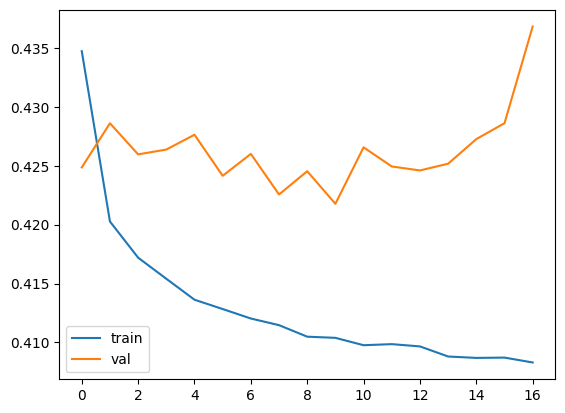

In [34]:
process_and_evaluate1(
    cnn_top100_model,
    X_train, y_train,
    X_test, y_test,
    np.array(df_train1['Ticker_Encoded']), np.array(df_test1['Ticker_Encoded'])
    ,checkpoint_path=rf'{checkpoints_path}\cnn_top100.keras',epochs=30,batch_size=16
)

In [35]:
cnn_top100_model_loaded = tf.keras.models.load_model(rf'{checkpoints_path}\cnn_top100.keras')

In [36]:
pred_probs_test = cnn_top100_model_loaded.predict([ticker_encoded_test, X_test])
pred_probs_train = cnn_top100_model_loaded.predict([ticker_encoded_train, X_train])

338/338 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
1344/1344 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step


In [37]:
np.isnan(pred_probs_test).sum()

np.int64(0)

In [38]:
np.isnan(pred_probs_train).sum()

np.int64(0)

In [39]:

def calculate_metrics1(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':confusion
    }



In [40]:
train_metrics1 = calculate_metrics1(y_train,(pred_probs_train>=0.5).astype(int),pred_probs_train)
test_metrics1 = calculate_metrics1(y_test,(pred_probs_test>=0.5).astype(int),pred_probs_test)

In [41]:
train_metrics_df1 = pd.DataFrame([train_metrics1])
train_metrics_df1['Set'] = "Train"
test_metrics_df1 = pd.DataFrame([test_metrics1])
test_metrics_df1['Set'] = "Test"
model_metrics1 = pd.concat([train_metrics_df1,test_metrics_df1],axis=0)
model_metrics1.reset_index(drop=True,inplace=True)
model_metrics1.head()

,accuracy,roc,precision,recall,f1,confusion_matrix,Set
0,0.849738,0.625283,0.389831,0.007151,0.014044,"[[36480, 72], [6387, 46]]",Train
1,0.883760,0.512173,0.105263,0.010309,0.018779,"[[9522, 102], [1152, 12]]",Test


In [42]:
model_name = 'cnn_top100'
top_n = 30

In [43]:
def label_prediction(row, model_name,top_n):
    in_top_50 = row[f'Top_{top_n}_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_50 and target == 1:
        return 'TP'
    elif in_top_50 and target == 0:
        return 'FP'
    elif not in_top_50 and target == 0:
        return 'TN'
    elif not in_top_50 and target == 1:
        return 'FN'

def flag_top50_nlargest(group, pred_prob_col,top_n):
    # If all pred_probs are zero, return all False
    if group[pred_prob_col].sum() == 0:
        return pd.Series([False] * len(group), index=group.index)
    # Use nlargest to get exactly 50
    top50_idx = group[pred_prob_col].nlargest(top_n).index
    flag = pd.Series(False, index=group.index)
    flag.loc[top50_idx] = True
    return flag

def label_prediction1(row, model_name):
    has_more_prob_than_threshold = row[f'Pred_Prob_Threshold_{model_name}']
    target = row['Target']
    
    if has_more_prob_than_threshold and target == 1:
        return 'TP'
    elif has_more_prob_than_threshold and target == 0:
        return 'FP'
    elif not has_more_prob_than_threshold and target == 0:
        return 'TN'
    elif not has_more_prob_than_threshold and target == 1:
        return 'FN'
    
def add_suffix_to_cols(df, suffix, exclude_cols):
    return df.rename(
        columns={col: f"{col}{suffix}" for col in df.columns if col not in exclude_cols + ['Quarter', 'Set']}
    )


In [44]:

if len(set(['Rank','Returns'])-set(df_train1.columns))!=0:
    print("There are no rank and returns columns, merging now..!")
    df_train1 = df_train1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')
    df_test1 = df_test1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')

if np.isnan(pred_probs_train).all():
    print("All predictionsa re NaNs")

df_train_pred = df_train1[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test1[['Ticker','Quarter','Target','Returns','Rank']]

df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)

#### Top30 as fund - irrespective of the prob values
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)



df_pred.reset_index(drop=True,inplace=True)
df_pred.sort_values(by=['Quarter',f'Pred_Prob_{model_name}'],ascending=False,inplace=True)
df_pred[f'Top_{top_n}_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',top_n)

df_pred[f'Top_50_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',50)
# df_pred[(df_pred['Top_{top_n}_Pred_Prob_lstm_top50']==True)&(df_pred['Quarter']=='2005-12-31')]

# test_qtr_preds = df_pred[(df_pred['Quarter']=='2005-12-31')]['Pred_Prob_lstm_top50']
# test_qtr_preds[test_qtr_preds>0.9].shape
df_pred['Pred_Category_Top30'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=30), axis=1)
df_pred['Pred_Category_Top50'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=50), axis=1)
df_pred.reset_index(drop=True,inplace=True)

qtr_summary_df = df_pred.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Top30=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_30_Pred_Prob_{model_name}'] == True].mean()),
                    Avg_Returns_Predicted_Top50=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_50_Pred_Prob_{model_name}'] == True].mean()),
                    Count_TP_Top30=('Pred_Category_Top30', lambda x: (x == 'TP').sum()),
                    Count_TN_Top30=('Pred_Category_Top30', lambda x: (x == 'TN').sum()),
                    Count_FP_Top30=('Pred_Category_Top30', lambda x: (x == 'FP').sum()),
                    Count_FN_Top30=('Pred_Category_Top30', lambda x: (x == 'FN').sum()),
                    Count_TP_Top50=('Pred_Category_Top50', lambda x: (x == 'TP').sum()),
                    Count_TN_Top50=('Pred_Category_Top50', lambda x: (x == 'TN').sum()),
                    Count_FP_Top50=('Pred_Category_Top50', lambda x: (x == 'FP').sum()),
                    Count_FN_Top50=('Pred_Category_Top50', lambda x: (x == 'FN').sum())
                    
                    ).reset_index()

# set_summary_df = qtr_summary_df.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

df_pred1 = df_pred[['Ticker','Quarter','Target','Returns','Rank',f'Pred_Prob_{model_name}','Set']].copy()
df_pred1[f'Pred_Prob_Threshold_{model_name}'] = df_pred1[f'Pred_Prob_{model_name}'].between(0.5,1)



df_pred1['Pred_Category'] = df_pred1.apply(lambda row: label_prediction1(row, model_name=model_name), axis=1)
quarterly_returns_f2 = df_pred1.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Thresh=('Returns', lambda x: x[df_pred1.loc[x.index, f'Pred_Prob_Threshold_{model_name}'] == True].mean()),
                    Count_TP_Thresh=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN_Thresh=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP_Thresh=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN_Thresh=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()

qtr_summary_df2 = pd.DataFrame(quarterly_returns_f2)


#### Actual and Index returns mapping
##### Actual returns
act_returns = df_pred[df_pred['Target']==1].groupby(by='Quarter')['Returns'].mean()
df_act_returns = pd.DataFrame(act_returns)
df_act_returns.reset_index(inplace=True)
df_act_returns.rename(columns={'Returns':'Avg_Returns_Actual'},inplace=True)
qtr_summary_df = qtr_summary_df.merge(df_act_returns,on='Quarter',how='left')

##### Index returns - Qtrly
df_index = pd.read_excel(qtrly_returns_path,sheet_name='Qtrly_Stock_Returns')
df_index1 = df_index[df_index['Ticker'] == 'Nsemcap'].drop(columns=['Industry']).set_index(keys=['Ticker'])
df_index1 = df_index1.T
df_index1.reset_index(inplace=True)
df_index1.rename(columns={'index':'Quarter','Nsemcap':'Index_Returns'},inplace=True)

df_index1['Quarter'] = df_index1['Quarter'].apply(convert_qtr_to_date)
df_index1['Quarter'] = pd.to_datetime(df_index1['Quarter'],dayfirst=True)

qtr_summary_df = qtr_summary_df.merge(df_index1,how='left',on='Quarter')
qtr_summary_df['delta_returns_act_vs_pred_Top30'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top30']
qtr_summary_df['delta_returns_pred_vs_index_Top30'] = qtr_summary_df['Avg_Returns_Predicted_Top30']-qtr_summary_df['Index_Returns']
qtr_summary_df['delta_returns_act_vs_pred_Top50'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top50']
qtr_summary_df['delta_returns_pred_vs_index_Top50'] = qtr_summary_df['Avg_Returns_Predicted_Top50']-qtr_summary_df['Index_Returns']

qtr_summary_df2 = qtr_summary_df2.merge(df_act_returns,on='Quarter',how='left')
qtr_summary_df2 = qtr_summary_df2.merge(df_index1,on='Quarter',how='left')

qtr_summary_df2['delta_returns_act_vs_pred_Thresh'] = qtr_summary_df2['Avg_Returns_Actual']-qtr_summary_df2['Avg_Returns_Predicted_Thresh']
qtr_summary_df2['delta_returns_pred_vs_index_Thresh'] = qtr_summary_df2['Avg_Returns_Predicted_Thresh']-qtr_summary_df2['Index_Returns']


exclude_cols = ['Avg_Returns_Actual', 'Index_Returns']

# Reset index for merge
qtr_summary_df2_reset = qtr_summary_df2.reset_index(drop=True)
qtr_summary_df_reset = qtr_summary_df.reset_index(drop=True)

# Merge as before
merged_qtr_summary = pd.merge(
    qtr_summary_df_reset, qtr_summary_df2_reset,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

# Define the desired column order
ordered_cols = [
    'Quarter','Set',
    'Avg_Returns_Predicted_Top30','Avg_Returns_Predicted_Top50',
    'Avg_Returns_Predicted_Thresh',
    'Avg_Returns_Actual', 'Index_Returns',
    'delta_returns_act_vs_pred_Top30','delta_returns_pred_vs_index_Top30',
    'delta_returns_act_vs_pred_Top50','delta_returns_pred_vs_index_Top50',
    'delta_returns_act_vs_pred_Thresh','delta_returns_pred_vs_index_Thresh',
    'Count_TP_Top30', 'Count_TP_Top50', 'Count_TP_Thresh',
    'Count_TN_Top30', 'Count_TN_Top50', 'Count_TN_Thresh',
    'Count_FP_Top30', 'Count_FP_Top50', 'Count_FP_Thresh',
    'Count_FN_Top30', 'Count_FN_Top50', 'Count_FN_Thresh'
]

# Add any other columns that might exist but are not in the list
ordered_cols += [col for col in merged_qtr_summary.columns if col not in ordered_cols]

# Reorder columns
merged_qtr_summary = merged_qtr_summary[ordered_cols]
# merged_qtr_summary.reset_index(inplace=True)
merged_qtr_summary.head()

C:\Users\43737\AppData\Local\Temp\ipykernel_14952\1919607964.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_14952\1919607964.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_14952\1919607964.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.497622,0.436572,0.043011,0.832432,-0.019376,0.334810,0.516998,0.395860,...,0,376,363,390,15,28,1,79,72,94
1,2005-06-30,Train,0.319595,0.315499,0.007732,0.952000,0.045476,0.632406,0.274119,0.636502,...,0,368,352,389,22,38,1,87,83,95
2,2005-09-30,Train,0.035328,0.022234,-0.063939,0.331440,0.244277,0.296112,-0.208949,0.309205,...,0,365,351,386,22,36,1,90,84,98
3,2005-12-31,Train,0.201714,0.204555,0.016393,0.682739,0.058583,0.481025,0.143131,0.478185,...,0,367,352,387,21,36,1,88,83,97
4,2006-03-31,Train,-0.009165,0.159443,1.169355,0.254938,0.187746,0.264102,-0.196910,0.095495,...,1,374,361,391,17,30,0,86,79,98


In [45]:
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].isna().all()

np.False_

In [46]:
merged_qtr_summary.columns

Index(['Quarter', 'Set', 'Avg_Returns_Predicted_Top30',
       'Avg_Returns_Predicted_Top50', 'Avg_Returns_Predicted_Thresh',
       'Avg_Returns_Actual', 'Index_Returns',
       'delta_returns_act_vs_pred_Top30', 'delta_returns_pred_vs_index_Top30',
       'delta_returns_act_vs_pred_Top50', 'delta_returns_pred_vs_index_Top50',
       'delta_returns_act_vs_pred_Thresh',
       'delta_returns_pred_vs_index_Thresh', 'Count_TP_Top30',
       'Count_TP_Top50', 'Count_TP_Thresh', 'Count_TN_Top30', 'Count_TN_Top50',
       'Count_TN_Thresh', 'Count_FP_Top30', 'Count_FP_Top50',
       'Count_FP_Thresh', 'Count_FN_Top30', 'Count_FN_Top50',
       'Count_FN_Thresh'],
      dtype='object')

In [47]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([9.4741118e-01, 9.1188395e-01, 9.0887558e-01, ..., 3.8243446e-04,
       3.7709385e-04, 1.1656801e-04], dtype=float32)

In [48]:
set_summary_df3 =  merged_qtr_summary.groupby('Set').agg(
    Count_TP_Thresh = ('Count_TP_Thresh','sum'),
    Count_TN_Thresh = ('Count_TN_Thresh','sum'),
    Count_FP_Thresh = ('Count_FP_Thresh','sum'),
    Count_FN_Thresh = ('Count_FN_Thresh','sum'),
    Count_TP_Top30 = ('Count_TP_Top30','sum'),
    Count_TN_Top30 = ('Count_TN_Top30','sum'),
    Count_FP_Top30 = ('Count_FP_Top30','sum'),
    Count_FN_Top30 = ('Count_FN_Top30','sum'),
    Count_TP_Top50 = ('Count_TP_Top50','sum'),
    Count_TN_Top50 = ('Count_TN_Top50','sum'),
    Count_FP_Top50 = ('Count_FP_Top50','sum'),
    Count_FN_Top50 = ('Count_FN_Top50','sum')
)
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,12,9522,102,1152,48,9312,312,1116,71,9095,529,1093
Train,46,36480,72,6387,592,35104,1448,5841,926,34078,2474,5507


In [49]:

def calc_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return accuracy, precision, recall, f1


In [50]:
for suffix in ['_Top30','_Top50', '_Thresh']:
    print(f"\nMetrics for {suffix}:")
    for set_name, row in set_summary_df3.iterrows():
        tp = row[f'Count_TP{suffix}']
        tn = row[f'Count_TN{suffix}']
        fp = row[f'Count_FP{suffix}']
        fn = row[f'Count_FN{suffix}']
        accuracy, precision, recall, f1 = calc_metrics(tp, tn, fp, fn)
        print(f"{set_name}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")


Metrics for _Top30:
Test: accuracy=0.8676, precision=0.1333, recall=0.0412, f1=0.0630
Train: accuracy=0.8304, precision=0.2902, recall=0.0920, f1=0.1397

Metrics for _Top50:
Test: accuracy=0.8496, precision=0.1183, recall=0.0610, f1=0.0805
Train: accuracy=0.8143, precision=0.2724, recall=0.1439, f1=0.1883

Metrics for _Thresh:
Test: accuracy=0.8838, precision=0.1053, recall=0.0103, f1=0.0188
Train: accuracy=0.8497, precision=0.3898, recall=0.0072, f1=0.0140


In [51]:
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean():
    print("Both the stock picking strategies (Top 30 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 30 and Top 50) have same returns")
else:
    print("All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns")

All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns


In [52]:
merged_qtr_summary[merged_qtr_summary['Avg_Returns_Predicted_Top30'].isna()].shape

(2, 25)

In [53]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([9.4741118e-01, 9.1188395e-01, 9.0887558e-01, ..., 3.8243446e-04,
       3.7709385e-04, 1.1656801e-04], dtype=float32)

In [54]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].describe()

count    10788.000000
mean         0.140177
std          0.103616
min          0.000116
25%          0.072146
50%          0.126770
75%          0.193463
max          1.000000
Name: Pred_Prob_cnn_top100, dtype: float64

In [55]:
merged_qtr_summary['Quarter'].is_monotonic_increasing

True

In [56]:
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,12,9522,102,1152,48,9312,312,1116,71,9095,529,1093
Train,46,36480,72,6387,592,35104,1448,5841,926,34078,2474,5507


In [57]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'] = merged_qtr_summary['Avg_Returns_Predicted_Top30'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top50'] = merged_qtr_summary['Avg_Returns_Predicted_Top50'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Thresh'] = merged_qtr_summary['Avg_Returns_Predicted_Thresh'].ffill()

In [58]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Top50'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].fillna(0,inplace=True)

C:\Users\43737\AppData\Local\Temp\ipykernel_14952\4263771019.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
C:\Users\43737\AppData\Local\Temp\ipykernel_14952\4263771019.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beh

In [59]:
merged_qtr_summary.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.497622,0.436572,0.043011,0.832432,-0.019376,0.334810,0.516998,0.395860,...,0,376,363,390,15,28,1,79,72,94
1,2005-06-30,Train,0.319595,0.315499,0.007732,0.952000,0.045476,0.632406,0.274119,0.636502,...,0,368,352,389,22,38,1,87,83,95
2,2005-09-30,Train,0.035328,0.022234,-0.063939,0.331440,0.244277,0.296112,-0.208949,0.309205,...,0,365,351,386,22,36,1,90,84,98
3,2005-12-31,Train,0.201714,0.204555,0.016393,0.682739,0.058583,0.481025,0.143131,0.478185,...,0,367,352,387,21,36,1,88,83,97
4,2006-03-31,Train,-0.009165,0.159443,1.169355,0.254938,0.187746,0.264102,-0.196910,0.095495,...,1,374,361,391,17,30,0,86,79,98


In [60]:
df_pred.head()

,Ticker,Quarter,Target,Returns,Rank,Pred_Prob_cnn_top100,Set,Top_30_Pred_Prob_cnn_top100,Top_50_Pred_Prob_cnn_top100,Pred_Category_Top30,Pred_Category_Top50
0,easemytr,2024-12-31,0,-0.261665,589.0,0.947411,Test,True,True,FP,FP
1,adanigr,2024-12-31,0,-0.088450,240.0,0.911884,Test,True,True,FP,FP
2,metrobra,2024-12-31,0,-0.167276,387.0,0.908876,Test,True,True,FP,FP
3,sonacoms,2024-12-31,0,-0.224613,510.0,0.894435,Test,True,True,FP,FP
4,jublingr,2024-12-31,0,-0.210376,477.0,0.856333,Test,True,True,FP,FP


In [61]:
qtr_summary_df.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
0,2005-03-31,Train,0.497622,0.436572,15,376,15,79,22,363,28,72,0.832432,-0.019376,0.334810,0.516998,0.395860,0.455948
1,2005-06-30,Train,0.319595,0.315499,8,368,22,87,12,352,38,83,0.952000,0.045476,0.632406,0.274119,0.636502,0.270023
2,2005-09-30,Train,0.035328,0.022234,8,365,22,90,14,351,36,84,0.331440,0.244277,0.296112,-0.208949,0.309205,-0.222043
3,2005-12-31,Train,0.201714,0.204555,9,367,21,88,14,352,36,83,0.682739,0.058583,0.481025,0.143131,0.478185,0.145971
4,2006-03-31,Train,-0.009165,0.159443,13,374,17,86,20,361,30,79,0.254938,0.187746,0.264102,-0.196910,0.095495,-0.028303


In [62]:
qtr_summary_df['Set'].value_counts()

Set
Train    68
Test     12
Name: count, dtype: int64

In [63]:
model_name

'cnn_top100'

In [64]:
with pd.ExcelWriter(r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\results\lag\top100\3yrs_as_test_data_ts\Pred_Vs_Act_CNN_time_split_25_07_2025.xlsx", ) as writer:
    merged_qtr_summary.to_excel(writer, sheet_name='Qtr_Summary', index=False)
    qtr_summary_df.to_excel(writer, sheet_name='Qtr_Summary_Top', index=False)
    qtr_summary_df2.to_excel(writer, sheet_name='Qtr_Summary_Thresh', index=False)
    df_pred.to_excel(writer, sheet_name='Pred_Vs_Act_Top', index=False)
    df_pred1.to_excel(writer, sheet_name='Pred_Vs_Act_Thresh', index=False)
    set_summary_df3.to_excel(writer, sheet_name='Set_Summary')

### Top100 xform

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Flatten, Concatenate, Reshape, RepeatVector
from tensorflow.keras.models import Model
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,roc_auc_score
from tensorflow.keras.metrics import AUC, Precision
import os
from scipy.stats import skew

In [3]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [5]:
train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
# train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"

test_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\test_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
master_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

df_train = pd.read_excel(train_data_path)
df_test = pd.read_excel(test_data_path)
df_master = pd.read_excel(master_data_path)
qtrly_returns_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\lag\Quarterly_Price_Returns_Labels.xlsx"

In [6]:
df_train.reset_index(drop=True,inplace=True)
df_test.reset_index(drop=True,inplace=True)

In [7]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

In [8]:
print(df_train['Quarter'].dtypes,df_test['Quarter'].dtypes,df_master['Quarter'].dtypes)

datetime64[ns] datetime64[ns] object


In [9]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [10]:
df_train = df_train.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])
df_test = df_test.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])

In [11]:
vif_cols = list(df_train.columns)
for col in ['Ticker','Quarter','Set','Returns','Rank','Target']:
    if col in vif_cols:
        vif_cols.remove(col)

In [12]:
vif_cols

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [13]:
df_train['Target'] = np.where(df_train['Rank']<=100,1,0)
df_test['Target'] = np.where(df_test['Rank']<=100,1,0)

In [14]:
skewness = df_train[vif_cols].apply(lambda x: skew(x.dropna()))

In [15]:
skewness

TMR               13.086663
Momentum          12.412323
Beta               5.806239
Alpha             23.272412
EP                16.510138
BP               111.210752
SP                49.816550
Dividend_Flag     -1.256040
DE                37.320149
EPS              -40.005117
Zscore             2.836515
dtype: float64

In [16]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox

for col in vif_cols:
    x = df_train[col].dropna()
    print(f"\nFeature: {col}")
    print(f"Original skewness: {skew(x)}")
    if (x <= 0).any():
        # Use Yeo-Johnson for non-positive data
        pt = PowerTransformer(method='yeo-johnson')
        x_trans = pt.fit_transform(x.values.reshape(-1, 1)).flatten()
        print(f"Yeo-Johnson skewness: {skew(x_trans)}")
    else:
        # Try log and Box-Cox for positive data
        x_log = np.log1p(x)
        print(f"log1p skewness: {skew(x_log)}")
        x_bc, _ = boxcox(x)
        print(f"Box-Cox skewness: {skew(x_bc)}")
# ...existing code...


Feature: TMR
Original skewness: 13.086662785414012
Yeo-Johnson skewness: 1.3741422367307328

Feature: Momentum
Original skewness: 12.412322770259664
Yeo-Johnson skewness: -0.37304497754437993

Feature: Beta
Original skewness: 5.8062388351951615
Yeo-Johnson skewness: 4.617342875794953

Feature: Alpha
Original skewness: 23.272412041065202
Yeo-Johnson skewness: -2.9388817602113577

Feature: EP
Original skewness: 16.51013828757582
log1p skewness: 7.797053632006263
Box-Cox skewness: 0.11026200411795387

Feature: BP
Original skewness: 111.2107515117538
Yeo-Johnson skewness: 0.20590787331072397

Feature: SP
Original skewness: 49.8165504035785
log1p skewness: 2.490688401374147
Box-Cox skewness: 0.044374265589872564

Feature: Dividend_Flag
Original skewness: -1.2560396990530387
Yeo-Johnson skewness: -1.2560396990530391

Feature: DE
Original skewness: 37.32014887171092
Yeo-Johnson skewness: 0.04913837052975297

Feature: EPS
Original skewness: -40.00511654482117
Yeo-Johnson skewness: 1.696789070

In [17]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox
import numpy as np

best_transform_map = {}
for col in vif_cols:
    x = df_train[col].dropna()
    results = {}
    if (x <= 0).any():
        # Only Yeo-Johnson possible
        pt = PowerTransformer(method='yeo-johnson')
        x_yj = pt.fit_transform(x.values.reshape(-1, 1)).flatten()
        results['yeo-johnson'] = abs(skew(x_yj))
    else:
        x_log = np.log1p(x)
        results['log1p'] = abs(skew(x_log))
        try:
            x_bc, _ = boxcox(x)
            results['boxcox'] = abs(skew(x_bc))
        except Exception:
            results['boxcox'] = np.nan
    # Always include original for comparison
    results['original'] = abs(skew(x))
    # Pick the transform with minimum absolute skewness
    best = min(results, key=lambda k: results[k] if not np.isnan(results[k]) else np.inf)
    best_transform_map[col] = best
    print(f"{col}: Best transform = {best}, skewness = {results[best]:.3f}")
# ...existing code...

TMR: Best transform = yeo-johnson, skewness = 1.374
Momentum: Best transform = yeo-johnson, skewness = 0.373
Beta: Best transform = yeo-johnson, skewness = 4.617
Alpha: Best transform = yeo-johnson, skewness = 2.939
EP: Best transform = boxcox, skewness = 0.110
BP: Best transform = yeo-johnson, skewness = 0.206
SP: Best transform = boxcox, skewness = 0.044
Dividend_Flag: Best transform = original, skewness = 1.256
DE: Best transform = yeo-johnson, skewness = 0.049
EPS: Best transform = yeo-johnson, skewness = 1.697
Zscore: Best transform = yeo-johnson, skewness = 0.086


In [18]:
df_test.replace([np.inf, -np.inf], 0, inplace=True)

In [19]:
df_test[df_test['Quarter']=='31-03-2021']['Target'].value_counts()

Series([], Name: count, dtype: int64)

#### Power xforms

In [20]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox
import numpy as np

# 1. Decide best transform for each feature based on your previous results
# best_transform_map = {
#     'TMR': 'yeo-johnson',
#     'Momentum': 'yeo-johnson',
#     'Beta': 'yeo-johnson',
#     'Alpha': 'yeo-johnson',
#     'EP': 'boxcox',
#     'BP': 'yeo-johnson',
#     'SP': 'boxcox',
#     'EPS': 'yeo-johnson',
#     'Zscore': 'yeo-johnson',
#     'FCF': 'yeo-johnson',
#     'ICR': 'yeo-johnson',
#     'Year': 'log1p',
#     'Quarter_number': 'boxcox',  # or 'log1p', both are close
#     # 'Target': 'none',  # Target is not a feature
# }
best_transform_map = {
    'TMR': 'yeo-johnson',
    'Momentum': 'yeo-johnson',
    'Beta': 'yeo-johnson',
    'Alpha': 'yeo-johnson',
    'EP': 'boxcox',
    'BP': 'yeo-johnson',
    'SP': 'boxcox',
    'EPS': 'yeo-johnson',
    'Zscore': 'yeo-johnson',
    'DE': 'yeo-johnson', # Added based on your result: Best transform = yeo-johnson
    
    # Keep these commented as they were not in your latest results:
    # 'FCF': 'yeo-johnson',
    # 'ICR': 'yeo-johnson',
    # 'Year': 'log1p',
    # 'Quarter_number': 'boxcox',
}
def transform_feature(col, x, method):
    if method == 'yeo-johnson':
        pt = PowerTransformer(method='yeo-johnson')
        return pt.fit_transform(x.values.reshape(-1, 1)).flatten()
    elif method == 'boxcox':
        # Box-Cox requires strictly positive values
        # Add a small constant if min(x) == 0
        x_pos = x.copy()
        if (x_pos <= 0).any():
            x_pos = x_pos - x_pos.min() + 1e-6
        return boxcox(x_pos)[0]
    elif method == 'log1p':
        x_pos = x.copy()
        if (x_pos < 0).any():
            x_pos = x_pos - x_pos.min() + 1e-6
        return np.log1p(x_pos)
    else:
        return x.values

# 2. Apply transforms to train and test
df_train_trans = df_train.copy()
df_test_trans = df_test.copy()

for col in vif_cols:
    method = best_transform_map.get(col, 'none')
    if method != 'none':
        df_train_trans[col] = transform_feature(col, df_train[col], method)
        df_test_trans[col] = transform_feature(col, df_test[col], method)

# 3. Scaling
scaler = StandardScaler()
train_data = scaler.fit_transform(df_train_trans[vif_cols])
test_data = scaler.transform(df_test_trans[vif_cols])

df_train1 = pd.DataFrame(train_data, columns=vif_cols)
df_test1 = pd.DataFrame(test_data, columns=vif_cols)

for col in ['Ticker', 'Target', 'Quarter']:
    df_train1[col] = df_train[col]
    df_test1[col] = df_test[col]

# 4. Prepare X_train, y_train, X_test, y_test
features = vif_cols.copy()
X_train = df_train1[features].values
y_train = df_train1['Target'].values
X_test = df_test1[features].values
y_test = df_test1['Target'].values

# If your model expects 3D input (samples, timesteps, features):
# X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
# X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
# ...existing code...

X_train shape: (42985, 11)
y_train shape: (42985,)
X_test shape: (10788, 11)
y_test shape: (10788,)


In [21]:
check = pd.Series(y_train)
check.unique()

array([0, 1])

In [22]:


# 1. Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the La
# belEncoder on the entire set of unique labels across train, validation, and test data
all_tickers = pd.concat([df_train1['Ticker'], df_test1['Ticker']]).unique()
label_encoder.fit(all_tickers)

LabelEncoder()

In [23]:
df_train1['Ticker_Encoded'] = label_encoder.transform(df_train1['Ticker'])
df_test1['Ticker_Encoded'] = label_encoder.transform(df_test1['Ticker'])

In [24]:
def create_ticker_embedding(input_dim, output_dim):
    return Embedding(input_dim=input_dim, output_dim=output_dim, input_length=1)

In [26]:
# Now, the LabelEncoder is aware of all the possible tickers in all datasets
embedding_size = len(df_train1['Ticker_Encoded'].unique())  # Size of the embedding

# You can now proceed with creating your ticker embedding layer and other steps
ticker_embedding_layer = create_ticker_embedding(input_dim=embedding_size, output_dim=10)


In [27]:
features = vif_cols.copy()
features.append("Quarter")

In [28]:
ticker_encoded_train = df_train1['Ticker_Encoded'].values
ticker_encoded_test = df_test1['Ticker_Encoded'].values

#### Model Definition

In [29]:

def calculate_metrics(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':f'{confusion}'
    }


def process_and_evaluate1(model, X_train, y_train,X_test, y_test, ticker_encoded_train,ticker_encoded_test,epochs,checkpoint_path,batch_size,k=5):
    
    
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    for train_index, val_index in kf.split(X_train):
        X_train1, X_val = X_train[train_index], X_train[val_index]
        y_train1, y_val = y_train[train_index], y_train[val_index]
        ticker_train, ticker_val = ticker_encoded_train[train_index], ticker_encoded_train[val_index]

    early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                    save_weights_only=False,save_freq=epochs*batch_size,
                                                    verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.25, patience=7, min_lr=1e-6, verbose=1)
    history = model.fit([ticker_train, X_train1], y_train1,
            validation_data=([ticker_val, X_val], y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[early_stop, reduce_lr, cp_callback], verbose=0)

    # history = model.fit([ticker_encoded_train, X_train], y_train, epochs=epochs, batch_size=batch_size, validation_data=([ticker_encoded_test, X_test], y_test),callbacks=[cp_callback,early_stop])
    # model.load_weights(checkpoint_path)

    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.legend()
    

#### CNN

In [30]:
from tensorflow.keras.layers import Input, Embedding, Flatten, RepeatVector, Concatenate, Conv1D, GlobalAveragePooling1D, Dense, Reshape
from tensorflow.keras.models import Model
from tensorflow.keras.metrics import AUC, Precision

def build_cnn_top100_xform_model(input_shape, embedding_size, num_tickers):
    continuous_input = Input(shape=input_shape[1:], name="continuous_input")  # shape: (11,)
    ticker_input = Input(shape=(1,), name="ticker_input")

    # Ticker embedding
    ticker_embedding = Embedding(input_dim=num_tickers, output_dim=embedding_size)(ticker_input)
    ticker_embedding = Flatten()(ticker_embedding)
    ticker_embedding = RepeatVector(input_shape[1])(ticker_embedding)  # shape: (None, 11, embedding_size)

    # Reshape continuous input to match dimensions
    reshaped_continuous = Reshape((input_shape[1], 1))(continuous_input)  # shape: (None, 11, 1)

    # Merge inputs
    merged = Concatenate(axis=2)([ticker_embedding, reshaped_continuous])  # shape: (None, 11, embedding_size + 1)

    # CNN layers
    x = Conv1D(filters=64, kernel_size=1, activation='relu')(merged)
    x = GlobalAveragePooling1D()(x)
    output = Dense(1, activation='sigmoid')(x)

    model = Model(inputs=[ticker_input, continuous_input], outputs=output)
    return model


In [31]:
num_tickers = len(label_encoder.classes_)

In [32]:

# Define cnn model
cnn_top100_xform_model = build_cnn_top100_xform_model(X_train.shape, embedding_size, num_tickers)
cnn_top100_xform_model.compile(optimizer='adam', 
                   loss='binary_crossentropy',  # Binary classification problem
                   metrics=[AUC(),Precision()])

In [33]:
X_train.shape

(42985, 11)

In [35]:
checkpoints_path = r"D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts"


Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top100_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top100_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top100_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top100_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top100_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top100_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top100_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top100_xform.keras

Epoch 3: saving model to D:\Python\Final Quant Fund\Qua

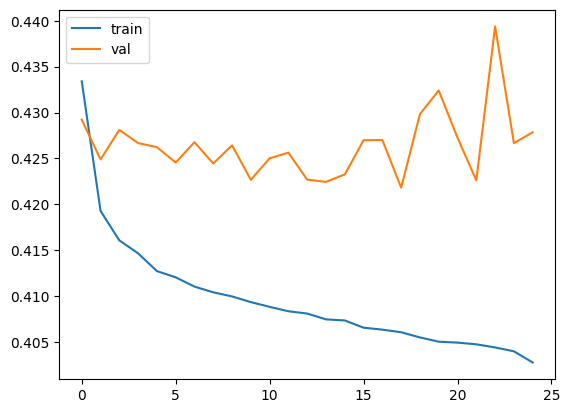

In [36]:
process_and_evaluate1(
    cnn_top100_xform_model,
    X_train, y_train,
    X_test, y_test,
    np.array(df_train1['Ticker_Encoded']), np.array(df_test1['Ticker_Encoded'])
    ,checkpoint_path=rf'{checkpoints_path}\cnn_top100_xform.keras',epochs=30,batch_size=16
)

In [37]:
cnn_top100_xform_model_loaded = tf.keras.models.load_model(rf'{checkpoints_path}\cnn_top100_xform.keras')

In [38]:
pred_probs_test = cnn_top100_xform_model_loaded.predict([ticker_encoded_test, X_test])
pred_probs_train = cnn_top100_xform_model_loaded.predict([ticker_encoded_train, X_train])



338/338 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
1344/1344 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step


In [39]:
np.isnan(pred_probs_test).sum()

np.int64(0)

In [40]:
np.isnan(pred_probs_train).sum()

np.int64(0)

In [41]:

def calculate_metrics1(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':confusion
    }



In [42]:
train_metrics1 = calculate_metrics1(y_train,(pred_probs_train>=0.5).astype(int),pred_probs_train)
test_metrics1 = calculate_metrics1(y_test,(pred_probs_test>=0.5).astype(int),pred_probs_test)

In [43]:
train_metrics_df1 = pd.DataFrame([train_metrics1])
train_metrics_df1['Set'] = "Train"
test_metrics_df1 = pd.DataFrame([test_metrics1])
test_metrics_df1['Set'] = "Test"
model_metrics1 = pd.concat([train_metrics_df1,test_metrics_df1],axis=0)
model_metrics1.reset_index(drop=True,inplace=True)
model_metrics1.head()

,accuracy,roc,precision,recall,f1,confusion_matrix,Set
0,0.850413,0.640921,0.522388,0.005441,0.010769,"[[36520, 32], [6398, 35]]",Train
1,0.887653,0.539126,0.157143,0.009450,0.017828,"[[9565, 59], [1153, 11]]",Test


In [44]:
model_name = 'cnn_top100_xform'
top_n = 30

In [45]:
def label_prediction(row, model_name,top_n):
    in_top_50 = row[f'Top_{top_n}_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_50 and target == 1:
        return 'TP'
    elif in_top_50 and target == 0:
        return 'FP'
    elif not in_top_50 and target == 0:
        return 'TN'
    elif not in_top_50 and target == 1:
        return 'FN'

def flag_top50_nlargest(group, pred_prob_col,top_n):
    # If all pred_probs are zero, return all False
    if group[pred_prob_col].sum() == 0:
        return pd.Series([False] * len(group), index=group.index)
    # Use nlargest to get exactly 50
    top50_idx = group[pred_prob_col].nlargest(top_n).index
    flag = pd.Series(False, index=group.index)
    flag.loc[top50_idx] = True
    return flag

def label_prediction1(row, model_name):
    has_more_prob_than_threshold = row[f'Pred_Prob_Threshold_{model_name}']
    target = row['Target']
    
    if has_more_prob_than_threshold and target == 1:
        return 'TP'
    elif has_more_prob_than_threshold and target == 0:
        return 'FP'
    elif not has_more_prob_than_threshold and target == 0:
        return 'TN'
    elif not has_more_prob_than_threshold and target == 1:
        return 'FN'
    
def add_suffix_to_cols(df, suffix, exclude_cols):
    return df.rename(
        columns={col: f"{col}{suffix}" for col in df.columns if col not in exclude_cols + ['Quarter', 'Set']}
    )


In [46]:

if len(set(['Rank','Returns'])-set(df_train1.columns))!=0:
    print("There are no rank and returns columns, merging now..!")
    df_train1 = df_train1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')
    df_test1 = df_test1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')

if np.isnan(pred_probs_train).all():
    print("All predictionsa re NaNs")

df_train_pred = df_train1[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test1[['Ticker','Quarter','Target','Returns','Rank']]

df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)

#### Top30 as fund - irrespective of the prob values
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)



df_pred.reset_index(drop=True,inplace=True)
df_pred.sort_values(by=['Quarter',f'Pred_Prob_{model_name}'],ascending=False,inplace=True)
df_pred[f'Top_{top_n}_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',top_n)

df_pred[f'Top_50_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',50)
# df_pred[(df_pred['Top_{top_n}_Pred_Prob_lstm_top50']==True)&(df_pred['Quarter']=='2005-12-31')]

# test_qtr_preds = df_pred[(df_pred['Quarter']=='2005-12-31')]['Pred_Prob_lstm_top50']
# test_qtr_preds[test_qtr_preds>0.9].shape
df_pred['Pred_Category_Top30'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=30), axis=1)
df_pred['Pred_Category_Top50'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=50), axis=1)
df_pred.reset_index(drop=True,inplace=True)

qtr_summary_df = df_pred.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Top30=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_30_Pred_Prob_{model_name}'] == True].mean()),
                    Avg_Returns_Predicted_Top50=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_50_Pred_Prob_{model_name}'] == True].mean()),
                    Count_TP_Top30=('Pred_Category_Top30', lambda x: (x == 'TP').sum()),
                    Count_TN_Top30=('Pred_Category_Top30', lambda x: (x == 'TN').sum()),
                    Count_FP_Top30=('Pred_Category_Top30', lambda x: (x == 'FP').sum()),
                    Count_FN_Top30=('Pred_Category_Top30', lambda x: (x == 'FN').sum()),
                    Count_TP_Top50=('Pred_Category_Top50', lambda x: (x == 'TP').sum()),
                    Count_TN_Top50=('Pred_Category_Top50', lambda x: (x == 'TN').sum()),
                    Count_FP_Top50=('Pred_Category_Top50', lambda x: (x == 'FP').sum()),
                    Count_FN_Top50=('Pred_Category_Top50', lambda x: (x == 'FN').sum())
                    
                    ).reset_index()

# set_summary_df = qtr_summary_df.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

df_pred1 = df_pred[['Ticker','Quarter','Target','Returns','Rank',f'Pred_Prob_{model_name}','Set']].copy()
df_pred1[f'Pred_Prob_Threshold_{model_name}'] = df_pred1[f'Pred_Prob_{model_name}'].between(0.5,1)



df_pred1['Pred_Category'] = df_pred1.apply(lambda row: label_prediction1(row, model_name=model_name), axis=1)
quarterly_returns_f2 = df_pred1.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Thresh=('Returns', lambda x: x[df_pred1.loc[x.index, f'Pred_Prob_Threshold_{model_name}'] == True].mean()),
                    Count_TP_Thresh=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN_Thresh=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP_Thresh=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN_Thresh=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()

qtr_summary_df2 = pd.DataFrame(quarterly_returns_f2)


#### Actual and Index returns mapping
##### Actual returns
act_returns = df_pred[df_pred['Target']==1].groupby(by='Quarter')['Returns'].mean()
df_act_returns = pd.DataFrame(act_returns)
df_act_returns.reset_index(inplace=True)
df_act_returns.rename(columns={'Returns':'Avg_Returns_Actual'},inplace=True)
qtr_summary_df = qtr_summary_df.merge(df_act_returns,on='Quarter',how='left')

##### Index returns - Qtrly
df_index = pd.read_excel(qtrly_returns_path,sheet_name='Qtrly_Stock_Returns')
df_index1 = df_index[df_index['Ticker'] == 'Nsemcap'].drop(columns=['Industry']).set_index(keys=['Ticker'])
df_index1 = df_index1.T
df_index1.reset_index(inplace=True)
df_index1.rename(columns={'index':'Quarter','Nsemcap':'Index_Returns'},inplace=True)

df_index1['Quarter'] = df_index1['Quarter'].apply(convert_qtr_to_date)
df_index1['Quarter'] = pd.to_datetime(df_index1['Quarter'],dayfirst=True)

qtr_summary_df = qtr_summary_df.merge(df_index1,how='left',on='Quarter')
qtr_summary_df['delta_returns_act_vs_pred_Top30'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top30']
qtr_summary_df['delta_returns_pred_vs_index_Top30'] = qtr_summary_df['Avg_Returns_Predicted_Top30']-qtr_summary_df['Index_Returns']
qtr_summary_df['delta_returns_act_vs_pred_Top50'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top50']
qtr_summary_df['delta_returns_pred_vs_index_Top50'] = qtr_summary_df['Avg_Returns_Predicted_Top50']-qtr_summary_df['Index_Returns']

qtr_summary_df2 = qtr_summary_df2.merge(df_act_returns,on='Quarter',how='left')
qtr_summary_df2 = qtr_summary_df2.merge(df_index1,on='Quarter',how='left')

qtr_summary_df2['delta_returns_act_vs_pred_Thresh'] = qtr_summary_df2['Avg_Returns_Actual']-qtr_summary_df2['Avg_Returns_Predicted_Thresh']
qtr_summary_df2['delta_returns_pred_vs_index_Thresh'] = qtr_summary_df2['Avg_Returns_Predicted_Thresh']-qtr_summary_df2['Index_Returns']


exclude_cols = ['Avg_Returns_Actual', 'Index_Returns']

# Reset index for merge
qtr_summary_df2_reset = qtr_summary_df2.reset_index(drop=True)
qtr_summary_df_reset = qtr_summary_df.reset_index(drop=True)

# Merge as before
merged_qtr_summary = pd.merge(
    qtr_summary_df_reset, qtr_summary_df2_reset,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

# Define the desired column order
ordered_cols = [
    'Quarter','Set',
    'Avg_Returns_Predicted_Top30','Avg_Returns_Predicted_Top50',
    'Avg_Returns_Predicted_Thresh',
    'Avg_Returns_Actual', 'Index_Returns',
    'delta_returns_act_vs_pred_Top30','delta_returns_pred_vs_index_Top30',
    'delta_returns_act_vs_pred_Top50','delta_returns_pred_vs_index_Top50',
    'delta_returns_act_vs_pred_Thresh','delta_returns_pred_vs_index_Thresh',
    'Count_TP_Top30', 'Count_TP_Top50', 'Count_TP_Thresh',
    'Count_TN_Top30', 'Count_TN_Top50', 'Count_TN_Thresh',
    'Count_FP_Top30', 'Count_FP_Top50', 'Count_FP_Thresh',
    'Count_FN_Top30', 'Count_FN_Top50', 'Count_FN_Thresh'
]

# Add any other columns that might exist but are not in the list
ordered_cols += [col for col in merged_qtr_summary.columns if col not in ordered_cols]

# Reorder columns
merged_qtr_summary = merged_qtr_summary[ordered_cols]
# merged_qtr_summary.reset_index(inplace=True)
merged_qtr_summary.head()

There are no rank and returns columns, merging now..!


C:\Users\43737\AppData\Local\Temp\ipykernel_3732\1919607964.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_3732\1919607964.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_3732\1919607964.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice fro

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.511975,0.563495,0.657143,0.832432,-0.019376,0.320457,0.531351,0.268938,...,1,377,367,391,14,24,0,78,68,93
1,2005-06-30,Train,0.549721,0.507229,-0.051724,0.952000,0.045476,0.402280,0.504245,0.444772,...,0,370,355,389,20,35,1,85,80,95
2,2005-09-30,Train,0.062780,0.012376,NaN,0.331440,0.244277,0.268660,-0.181497,0.319064,...,0,367,349,387,20,38,0,88,86,98
3,2005-12-31,Train,0.189064,0.180596,-0.415730,0.682739,0.058583,0.493675,0.130481,0.502144,...,0,365,351,387,23,37,1,90,84,97
4,2006-03-31,Train,0.090170,0.151922,-0.141026,0.254938,0.187746,0.164768,-0.097576,0.103015,...,0,376,366,390,15,25,1,84,74,99


In [47]:
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].isna().all()

np.False_

In [48]:
merged_qtr_summary.columns

Index(['Quarter', 'Set', 'Avg_Returns_Predicted_Top30',
       'Avg_Returns_Predicted_Top50', 'Avg_Returns_Predicted_Thresh',
       'Avg_Returns_Actual', 'Index_Returns',
       'delta_returns_act_vs_pred_Top30', 'delta_returns_pred_vs_index_Top30',
       'delta_returns_act_vs_pred_Top50', 'delta_returns_pred_vs_index_Top50',
       'delta_returns_act_vs_pred_Thresh',
       'delta_returns_pred_vs_index_Thresh', 'Count_TP_Top30',
       'Count_TP_Top50', 'Count_TP_Thresh', 'Count_TN_Top30', 'Count_TN_Top50',
       'Count_TN_Thresh', 'Count_FP_Top30', 'Count_FP_Top50',
       'Count_FP_Thresh', 'Count_FN_Top30', 'Count_FN_Top50',
       'Count_FN_Thresh'],
      dtype='object')

In [49]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([7.7120459e-01, 6.4161366e-01, 6.3565040e-01, ..., 5.6897890e-04,
       4.7959638e-04, 2.4142147e-04], dtype=float32)

In [50]:
set_summary_df3 =  merged_qtr_summary.groupby('Set').agg(
    Count_TP_Thresh = ('Count_TP_Thresh','sum'),
    Count_TN_Thresh = ('Count_TN_Thresh','sum'),
    Count_FP_Thresh = ('Count_FP_Thresh','sum'),
    Count_FN_Thresh = ('Count_FN_Thresh','sum'),
    Count_TP_Top30 = ('Count_TP_Top30','sum'),
    Count_TN_Top30 = ('Count_TN_Top30','sum'),
    Count_FP_Top30 = ('Count_FP_Top30','sum'),
    Count_FN_Top30 = ('Count_FN_Top30','sum'),
    Count_TP_Top50 = ('Count_TP_Top50','sum'),
    Count_TN_Top50 = ('Count_TN_Top50','sum'),
    Count_FP_Top50 = ('Count_FP_Top50','sum'),
    Count_FN_Top50 = ('Count_FN_Top50','sum')
)
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,11,9565,59,1153,41,9305,319,1123,80,9104,520,1084
Train,35,36520,32,6398,652,35164,1388,5781,1003,34155,2397,5430


In [51]:

def calc_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return accuracy, precision, recall, f1


In [52]:
for suffix in ['_Top30','_Top50', '_Thresh']:
    print(f"\nMetrics for {suffix}:")
    for set_name, row in set_summary_df3.iterrows():
        tp = row[f'Count_TP{suffix}']
        tn = row[f'Count_TN{suffix}']
        fp = row[f'Count_FP{suffix}']
        fn = row[f'Count_FN{suffix}']
        accuracy, precision, recall, f1 = calc_metrics(tp, tn, fp, fn)
        print(f"{set_name}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")


Metrics for _Top30:
Test: accuracy=0.8663, precision=0.1139, recall=0.0352, f1=0.0538
Train: accuracy=0.8332, precision=0.3196, recall=0.1014, f1=0.1539

Metrics for _Top50:
Test: accuracy=0.8513, precision=0.1333, recall=0.0687, f1=0.0907
Train: accuracy=0.8179, precision=0.2950, recall=0.1559, f1=0.2040

Metrics for _Thresh:
Test: accuracy=0.8877, precision=0.1571, recall=0.0095, f1=0.0178
Train: accuracy=0.8504, precision=0.5224, recall=0.0054, f1=0.0108


In [53]:
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean():
    print("Both the stock picking strategies (Top 30 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 30 and Top 50) have same returns")
else:
    print("All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns")

All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns


In [54]:
merged_qtr_summary[merged_qtr_summary['Avg_Returns_Predicted_Top30'].isna()].shape

(2, 25)

In [55]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([7.7120459e-01, 6.4161366e-01, 6.3565040e-01, ..., 5.6897890e-04,
       4.7959638e-04, 2.4142147e-04], dtype=float32)

In [56]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].describe()

count    10788.000000
mean         0.142181
std          0.086297
min          0.000191
25%          0.079888
50%          0.138984
75%          0.195995
max          0.774220
Name: Pred_Prob_cnn_top100_xform, dtype: float64

In [57]:
merged_qtr_summary['Quarter'].is_monotonic_increasing

True

In [58]:
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,11,9565,59,1153,41,9305,319,1123,80,9104,520,1084
Train,35,36520,32,6398,652,35164,1388,5781,1003,34155,2397,5430


In [59]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'] = merged_qtr_summary['Avg_Returns_Predicted_Top30'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top50'] = merged_qtr_summary['Avg_Returns_Predicted_Top50'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Thresh'] = merged_qtr_summary['Avg_Returns_Predicted_Thresh'].ffill()

In [60]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Top50'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].fillna(0,inplace=True)

C:\Users\43737\AppData\Local\Temp\ipykernel_3732\4263771019.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
C:\Users\43737\AppData\Local\Temp\ipykernel_3732\4263771019.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behav

In [61]:
merged_qtr_summary.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.511975,0.563495,0.657143,0.832432,-0.019376,0.320457,0.531351,0.268938,...,1,377,367,391,14,24,0,78,68,93
1,2005-06-30,Train,0.549721,0.507229,-0.051724,0.952000,0.045476,0.402280,0.504245,0.444772,...,0,370,355,389,20,35,1,85,80,95
2,2005-09-30,Train,0.062780,0.012376,-0.051724,0.331440,0.244277,0.268660,-0.181497,0.319064,...,0,367,349,387,20,38,0,88,86,98
3,2005-12-31,Train,0.189064,0.180596,-0.415730,0.682739,0.058583,0.493675,0.130481,0.502144,...,0,365,351,387,23,37,1,90,84,97
4,2006-03-31,Train,0.090170,0.151922,-0.141026,0.254938,0.187746,0.164768,-0.097576,0.103015,...,0,376,366,390,15,25,1,84,74,99


In [62]:
df_pred.head()

,Ticker,Quarter,Target,Returns,Rank,Pred_Prob_cnn_top100_xform,Set,Top_30_Pred_Prob_cnn_top100_xform,Top_50_Pred_Prob_cnn_top100_xform,Pred_Category_Top30,Pred_Category_Top50
0,metrobra,2024-12-31,0,-0.167276,387.0,0.771205,Test,True,True,FP,FP
1,easemytr,2024-12-31,0,-0.261665,589.0,0.641614,Test,True,True,FP,FP
2,atgl,2024-12-31,0,-0.208199,473.0,0.635650,Test,True,True,FP,FP
3,sonacoms,2024-12-31,0,-0.224613,510.0,0.607323,Test,True,True,FP,FP
4,devyani,2024-12-31,0,-0.182571,419.0,0.494109,Test,True,True,FP,FP


In [63]:
qtr_summary_df.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
0,2005-03-31,Train,0.511975,0.563495,16,377,14,78,26,367,24,68,0.832432,-0.019376,0.320457,0.531351,0.268938,0.582870
1,2005-06-30,Train,0.549721,0.507229,10,370,20,85,15,355,35,80,0.952000,0.045476,0.402280,0.504245,0.444772,0.461753
2,2005-09-30,Train,0.062780,0.012376,10,367,20,88,12,349,38,86,0.331440,0.244277,0.268660,-0.181497,0.319064,-0.231901
3,2005-12-31,Train,0.189064,0.180596,7,365,23,90,13,351,37,84,0.682739,0.058583,0.493675,0.130481,0.502144,0.122012
4,2006-03-31,Train,0.090170,0.151922,15,376,15,84,25,366,25,74,0.254938,0.187746,0.164768,-0.097576,0.103015,-0.035823


In [64]:
qtr_summary_df['Set'].value_counts()

Set
Train    68
Test     12
Name: count, dtype: int64

In [65]:
model_name

'cnn_top100_xform'

In [66]:
with pd.ExcelWriter(r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\results\lag\top100\3yrs_as_test_data_ts\Pred_Vs_Act_CNN_xform_time_split_25_07_2025.xlsx", ) as writer:
    merged_qtr_summary.to_excel(writer, sheet_name='Qtr_Summary', index=False)
    qtr_summary_df.to_excel(writer, sheet_name='Qtr_Summary_Top', index=False)
    qtr_summary_df2.to_excel(writer, sheet_name='Qtr_Summary_Thresh', index=False)
    df_pred.to_excel(writer, sheet_name='Pred_Vs_Act_Top', index=False)
    df_pred1.to_excel(writer, sheet_name='Pred_Vs_Act_Thresh', index=False)
    set_summary_df3.to_excel(writer, sheet_name='Set_Summary')

### Top 200 as Tgt

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Flatten, Concatenate, Reshape, RepeatVector
from tensorflow.keras.models import Model
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,roc_auc_score
from tensorflow.keras.metrics import AUC, Precision
import os

In [2]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [3]:
train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
test_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\test_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
master_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"
# train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"

df_train = pd.read_excel(train_data_path)
df_test = pd.read_excel(test_data_path)
df_master = pd.read_excel(master_data_path)
qtrly_returns_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\lag\Quarterly_Price_Returns_Labels.xlsx"
# qtrly_returns_path = r"D:\FY25-26\Quant Fund\data\Quarterly_Price_Returns_Labels.xlsx"

In [4]:
df_train.reset_index(drop=True,inplace=True)
df_test.reset_index(drop=True,inplace=True)

In [5]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

In [6]:
print(df_train['Quarter'].dtypes,df_test['Quarter'].dtypes,df_master['Quarter'].dtypes)

datetime64[ns] datetime64[ns] object


In [7]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [8]:
df_train = df_train.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])
df_test = df_test.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])

In [9]:
df_train['Target'] = np.where(df_train['Rank']<=200,1,0)
df_test['Target'] = np.where(df_test['Rank']<=200,1,0)

##### Scaling

In [10]:
scaler = StandardScaler()

In [11]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target', 'Returns',
       'Rank'],
      dtype='object')

In [206]:
# df_train.drop()

In [12]:
vif_cols = list(df_train.columns)
for col in ['Ticker','Quarter','Set','Rank','Returns','Target']:
    if col in vif_cols:
        vif_cols.remove(col)

In [13]:
vif_cols

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [14]:
df_test.replace([np.inf, -np.inf], 0, inplace=True)

In [15]:
train_data = scaler.fit_transform(df_train[vif_cols])
test_data = scaler.transform(df_test[vif_cols])

In [16]:
df_train1 = pd.DataFrame(train_data,columns=vif_cols)
df_test1 = pd.DataFrame(test_data,columns=vif_cols)

In [17]:
for col in ['Ticker','Target', 'Quarter','Rank','Returns']:
    df_train1[col] = df_train[col]
    df_test1[col] = df_test[col]

In [18]:


# 1. Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the La
# belEncoder on the entire set of unique labels across train, validation, and test data
all_tickers = pd.concat([df_train1['Ticker'], df_test1['Ticker']]).unique()
label_encoder.fit(all_tickers)

LabelEncoder()

In [19]:
df_train1['Ticker_Encoded'] = label_encoder.transform(df_train1['Ticker'])
df_test1['Ticker_Encoded'] = label_encoder.transform(df_test1['Ticker'])

In [215]:
# df_train1['Ticker_Encoded']

In [20]:
def create_ticker_embedding(input_dim, output_dim):
    return Embedding(input_dim=input_dim, output_dim=output_dim, input_length=1)

In [21]:
# Now, the LabelEncoder is aware of all the possible tickers in all datasets
embedding_size = len(df_train1['Ticker_Encoded'].unique())  # Size of the embedding

# You can now proceed with creating your ticker embedding layer and other steps
ticker_embedding_layer = create_ticker_embedding(input_dim=embedding_size, output_dim=10)


d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [22]:
features = vif_cols.copy()
features.append("Quarter")
features

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore',
 'Quarter']

In [23]:
features.remove("Quarter")
X_train = df_train1[features].values
y_train = df_train1['Target'].values

df_test1['Quarter'] = pd.to_datetime(df_test1['Quarter'])
df_test1['Year'] = df_test1['Quarter'].dt.year
df_test1['Quarter_number'] = df_test1['Quarter'].dt.quarter

X_test = df_test1[features].values
y_test = df_test1['Target'].values

# X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
# X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (42985, 11)
y_train shape: (42985,)
X_test shape: (10788, 11)
y_test shape: (10788,)


In [24]:
ticker_encoded_train = df_train1['Ticker_Encoded'].values
ticker_encoded_test = df_test1['Ticker_Encoded'].values

In [25]:

def calculate_metrics(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':f'{confusion}'
    }


def process_and_evaluate1(model, X_train, y_train,X_test, y_test, ticker_encoded_train,ticker_encoded_test,epochs,checkpoint_path,batch_size,k=5):
    
    
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    for train_index, val_index in kf.split(X_train):
        X_train1, X_val = X_train[train_index], X_train[val_index]
        y_train1, y_val = y_train[train_index], y_train[val_index]
        ticker_train, ticker_val = ticker_encoded_train[train_index], ticker_encoded_train[val_index]

    early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                    save_weights_only=False,save_freq=epochs*batch_size,
                                                    verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.25, patience=7, min_lr=1e-6, verbose=1)
    history = model.fit([ticker_train, X_train1], y_train1,
            validation_data=([ticker_val, X_val], y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[early_stop, reduce_lr, cp_callback], verbose=0)

    # history = model.fit([ticker_encoded_train, X_train], y_train, epochs=epochs, batch_size=batch_size, validation_data=([ticker_encoded_test, X_test], y_test),callbacks=[cp_callback,early_stop])
    # model.load_weights(checkpoint_path)

    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.legend()
    

#### CNN

In [26]:
from tensorflow.keras.layers import Input, Embedding, Flatten, RepeatVector, Concatenate, Conv1D, GlobalAveragePooling1D, Dense, Reshape
from tensorflow.keras.models import Model
from tensorflow.keras.metrics import AUC, Precision

def build_cnn_top200_model(input_shape, embedding_size, num_tickers):
    continuous_input = Input(shape=input_shape[1:], name="continuous_input")  # shape: (11,)
    ticker_input = Input(shape=(1,), name="ticker_input")

    # Ticker embedding
    ticker_embedding = Embedding(input_dim=num_tickers, output_dim=embedding_size)(ticker_input)
    ticker_embedding = Flatten()(ticker_embedding)
    ticker_embedding = RepeatVector(input_shape[1])(ticker_embedding)  # shape: (None, 11, embedding_size)

    # Reshape continuous input to match dimensions
    reshaped_continuous = Reshape((input_shape[1], 1))(continuous_input)  # shape: (None, 11, 1)

    # Merge inputs
    merged = Concatenate(axis=2)([ticker_embedding, reshaped_continuous])  # shape: (None, 11, embedding_size + 1)

    # CNN layers
    x = Conv1D(filters=64, kernel_size=1, activation='relu')(merged)
    x = GlobalAveragePooling1D()(x)
    output = Dense(1, activation='sigmoid')(x)

    model = Model(inputs=[ticker_input, continuous_input], outputs=output)
    return model


In [27]:
df_test1[df_test1['Quarter']=='2006-03-31']['Target'].value_counts()

Series([], Name: count, dtype: int64)

In [28]:
num_tickers = len(label_encoder.classes_)

In [29]:

# Define cnn model
cnn_top200_model = build_cnn_top200_model(X_train.shape, embedding_size, num_tickers)
cnn_top200_model.compile(optimizer='adam', 
                   loss='binary_crossentropy',  # Binary classification problem
                   metrics=[AUC(),Precision()])

In [30]:
X_train.shape

(42985, 11)

In [31]:
y_train.shape

(42985,)

In [33]:
checkpoints_path = r"D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts"


Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top200.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top200.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top200.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top200.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top200.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top200.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top200.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top200.keras

Epoch 3: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top20

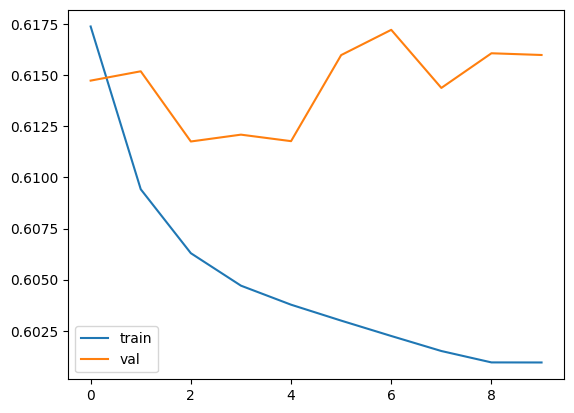

In [34]:
process_and_evaluate1(
    cnn_top200_model,
    X_train, y_train,
    X_test, y_test,
    np.array(df_train1['Ticker_Encoded']), np.array(df_test1['Ticker_Encoded'])
    ,checkpoint_path=rf'{checkpoints_path}\cnn_top200.keras',epochs=30,batch_size=16
)

In [35]:
cnn_top200_model_loaded = tf.keras.models.load_model(rf'{checkpoints_path}\cnn_top200.keras')

In [36]:
pred_probs_test = cnn_top200_model_loaded.predict([ticker_encoded_test, X_test])
pred_probs_train = cnn_top200_model_loaded.predict([ticker_encoded_train, X_train])

338/338 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
1344/1344 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step


In [37]:
np.isnan(pred_probs_test).sum()

np.int64(0)

In [38]:
np.isnan(pred_probs_train).sum()

np.int64(0)

In [39]:

def calculate_metrics1(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':confusion
    }



In [40]:
train_metrics1 = calculate_metrics1(y_train,(pred_probs_train>=0.5).astype(int),pred_probs_train)
test_metrics1 = calculate_metrics1(y_test,(pred_probs_test>=0.5).astype(int),pred_probs_test)

d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [41]:
train_metrics_df1 = pd.DataFrame([train_metrics1])
train_metrics_df1['Set'] = "Train"
test_metrics_df1 = pd.DataFrame([test_metrics1])
test_metrics_df1['Set'] = "Test"
model_metrics1 = pd.concat([train_metrics_df1,test_metrics_df1],axis=0)
model_metrics1.reset_index(drop=True,inplace=True)
model_metrics1.head()

,accuracy,roc,precision,recall,f1,confusion_matrix,Set
0,0.700407,0.577811,0.0,0.0,0.0,"[[30107, 0], [12878, 0]]",Train
1,0.784390,0.474248,0.0,0.0,0.0,"[[8462, 0], [2326, 0]]",Test


In [42]:
model_name = 'cnn_top200'
top_n = 30

In [43]:
def label_prediction(row, model_name,top_n):
    in_top_50 = row[f'Top_{top_n}_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_50 and target == 1:
        return 'TP'
    elif in_top_50 and target == 0:
        return 'FP'
    elif not in_top_50 and target == 0:
        return 'TN'
    elif not in_top_50 and target == 1:
        return 'FN'

def flag_top50_nlargest(group, pred_prob_col,top_n):
    # If all pred_probs are zero, return all False
    if group[pred_prob_col].sum() == 0:
        return pd.Series([False] * len(group), index=group.index)
    # Use nlargest to get exactly 50
    top50_idx = group[pred_prob_col].nlargest(top_n).index
    flag = pd.Series(False, index=group.index)
    flag.loc[top50_idx] = True
    return flag

def label_prediction1(row, model_name):
    has_more_prob_than_threshold = row[f'Pred_Prob_Threshold_{model_name}']
    target = row['Target']
    
    if has_more_prob_than_threshold and target == 1:
        return 'TP'
    elif has_more_prob_than_threshold and target == 0:
        return 'FP'
    elif not has_more_prob_than_threshold and target == 0:
        return 'TN'
    elif not has_more_prob_than_threshold and target == 1:
        return 'FN'
    
def add_suffix_to_cols(df, suffix, exclude_cols):
    return df.rename(
        columns={col: f"{col}{suffix}" for col in df.columns if col not in exclude_cols + ['Quarter', 'Set']}
    )


In [44]:

if len(set(['Rank','Returns'])-set(df_train1.columns))!=0:
    print("There are no rank and returns columns, merging now..!")
    df_train1 = df_train1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')
    df_test1 = df_test1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')

if np.isnan(pred_probs_train).all():
    print("All predictionsa re NaNs")

df_train_pred = df_train1[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test1[['Ticker','Quarter','Target','Returns','Rank']]

df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)

#### Top30 as fund - irrespective of the prob values
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)



df_pred.reset_index(drop=True,inplace=True)
df_pred.sort_values(by=['Quarter',f'Pred_Prob_{model_name}'],ascending=False,inplace=True)
df_pred[f'Top_{top_n}_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',top_n)

df_pred[f'Top_50_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',50)
# df_pred[(df_pred['Top_{top_n}_Pred_Prob_lstm_top50']==True)&(df_pred['Quarter']=='2005-12-31')]

# test_qtr_preds = df_pred[(df_pred['Quarter']=='2005-12-31')]['Pred_Prob_lstm_top50']
# test_qtr_preds[test_qtr_preds>0.9].shape
df_pred['Pred_Category_Top30'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=30), axis=1)
df_pred['Pred_Category_Top50'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=50), axis=1)
df_pred.reset_index(drop=True,inplace=True)

qtr_summary_df = df_pred.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Top30=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_30_Pred_Prob_{model_name}'] == True].mean()),
                    Avg_Returns_Predicted_Top50=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_50_Pred_Prob_{model_name}'] == True].mean()),
                    Count_TP_Top30=('Pred_Category_Top30', lambda x: (x == 'TP').sum()),
                    Count_TN_Top30=('Pred_Category_Top30', lambda x: (x == 'TN').sum()),
                    Count_FP_Top30=('Pred_Category_Top30', lambda x: (x == 'FP').sum()),
                    Count_FN_Top30=('Pred_Category_Top30', lambda x: (x == 'FN').sum()),
                    Count_TP_Top50=('Pred_Category_Top50', lambda x: (x == 'TP').sum()),
                    Count_TN_Top50=('Pred_Category_Top50', lambda x: (x == 'TN').sum()),
                    Count_FP_Top50=('Pred_Category_Top50', lambda x: (x == 'FP').sum()),
                    Count_FN_Top50=('Pred_Category_Top50', lambda x: (x == 'FN').sum())
                    
                    ).reset_index()

# set_summary_df = qtr_summary_df.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

df_pred1 = df_pred[['Ticker','Quarter','Target','Returns','Rank',f'Pred_Prob_{model_name}','Set']].copy()
df_pred1[f'Pred_Prob_Threshold_{model_name}'] = df_pred1[f'Pred_Prob_{model_name}'].between(0.5,1)



df_pred1['Pred_Category'] = df_pred1.apply(lambda row: label_prediction1(row, model_name=model_name), axis=1)
quarterly_returns_f2 = df_pred1.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Thresh=('Returns', lambda x: x[df_pred1.loc[x.index, f'Pred_Prob_Threshold_{model_name}'] == True].mean()),
                    Count_TP_Thresh=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN_Thresh=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP_Thresh=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN_Thresh=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()

qtr_summary_df2 = pd.DataFrame(quarterly_returns_f2)


#### Actual and Index returns mapping
##### Actual returns
act_returns = df_pred[df_pred['Target']==1].groupby(by='Quarter')['Returns'].mean()
df_act_returns = pd.DataFrame(act_returns)
df_act_returns.reset_index(inplace=True)
df_act_returns.rename(columns={'Returns':'Avg_Returns_Actual'},inplace=True)
qtr_summary_df = qtr_summary_df.merge(df_act_returns,on='Quarter',how='left')

##### Index returns - Qtrly
df_index = pd.read_excel(qtrly_returns_path,sheet_name='Qtrly_Stock_Returns')
df_index1 = df_index[df_index['Ticker'] == 'Nsemcap'].drop(columns=['Industry']).set_index(keys=['Ticker'])
df_index1 = df_index1.T
df_index1.reset_index(inplace=True)
df_index1.rename(columns={'index':'Quarter','Nsemcap':'Index_Returns'},inplace=True)

df_index1['Quarter'] = df_index1['Quarter'].apply(convert_qtr_to_date)
df_index1['Quarter'] = pd.to_datetime(df_index1['Quarter'],dayfirst=True)

qtr_summary_df = qtr_summary_df.merge(df_index1,how='left',on='Quarter')
qtr_summary_df['delta_returns_act_vs_pred_Top30'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top30']
qtr_summary_df['delta_returns_pred_vs_index_Top30'] = qtr_summary_df['Avg_Returns_Predicted_Top30']-qtr_summary_df['Index_Returns']
qtr_summary_df['delta_returns_act_vs_pred_Top50'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top50']
qtr_summary_df['delta_returns_pred_vs_index_Top50'] = qtr_summary_df['Avg_Returns_Predicted_Top50']-qtr_summary_df['Index_Returns']

qtr_summary_df2 = qtr_summary_df2.merge(df_act_returns,on='Quarter',how='left')
qtr_summary_df2 = qtr_summary_df2.merge(df_index1,on='Quarter',how='left')

qtr_summary_df2['delta_returns_act_vs_pred_Thresh'] = qtr_summary_df2['Avg_Returns_Actual']-qtr_summary_df2['Avg_Returns_Predicted_Thresh']
qtr_summary_df2['delta_returns_pred_vs_index_Thresh'] = qtr_summary_df2['Avg_Returns_Predicted_Thresh']-qtr_summary_df2['Index_Returns']


exclude_cols = ['Avg_Returns_Actual', 'Index_Returns']

# Reset index for merge
qtr_summary_df2_reset = qtr_summary_df2.reset_index(drop=True)
qtr_summary_df_reset = qtr_summary_df.reset_index(drop=True)

# Merge as before
merged_qtr_summary = pd.merge(
    qtr_summary_df_reset, qtr_summary_df2_reset,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

# Define the desired column order
ordered_cols = [
    'Quarter','Set',
    'Avg_Returns_Predicted_Top30','Avg_Returns_Predicted_Top50',
    'Avg_Returns_Predicted_Thresh',
    'Avg_Returns_Actual', 'Index_Returns',
    'delta_returns_act_vs_pred_Top30','delta_returns_pred_vs_index_Top30',
    'delta_returns_act_vs_pred_Top50','delta_returns_pred_vs_index_Top50',
    'delta_returns_act_vs_pred_Thresh','delta_returns_pred_vs_index_Thresh',
    'Count_TP_Top30', 'Count_TP_Top50', 'Count_TP_Thresh',
    'Count_TN_Top30', 'Count_TN_Top50', 'Count_TN_Thresh',
    'Count_FP_Top30', 'Count_FP_Top50', 'Count_FP_Thresh',
    'Count_FN_Top30', 'Count_FN_Top50', 'Count_FN_Thresh'
]

# Add any other columns that might exist but are not in the list
ordered_cols += [col for col in merged_qtr_summary.columns if col not in ordered_cols]

# Reorder columns
merged_qtr_summary = merged_qtr_summary[ordered_cols]
# merged_qtr_summary.reset_index(inplace=True)
merged_qtr_summary.head()

C:\Users\43737\AppData\Local\Temp\ipykernel_36340\1919607964.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_36340\1919607964.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_36340\1919607964.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.464101,0.403391,NaN,0.532415,-0.019376,0.068314,0.483476,0.129024,...,0,280,273,294,14,21,0,175,162,191
1,2005-06-30,Train,0.278228,0.322799,NaN,0.645971,0.045476,0.367743,0.232752,0.323172,...,0,276,265,291,15,26,0,179,170,194
2,2005-09-30,Train,-0.008310,0.009052,NaN,0.231957,0.244277,0.240268,-0.252587,0.222906,...,0,268,255,287,19,32,0,187,180,198
3,2005-12-31,Train,0.156003,0.153157,NaN,0.471668,0.058583,0.315665,0.097420,0.318511,...,0,271,259,288,17,29,0,184,176,197
4,2006-03-31,Train,-0.124907,-0.112864,NaN,0.085933,0.187746,0.210840,-0.312652,0.198798,...,0,275,265,293,18,28,0,185,175,197


In [45]:
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].isna().all()

np.True_

In [46]:
merged_qtr_summary.columns

Index(['Quarter', 'Set', 'Avg_Returns_Predicted_Top30',
       'Avg_Returns_Predicted_Top50', 'Avg_Returns_Predicted_Thresh',
       'Avg_Returns_Actual', 'Index_Returns',
       'delta_returns_act_vs_pred_Top30', 'delta_returns_pred_vs_index_Top30',
       'delta_returns_act_vs_pred_Top50', 'delta_returns_pred_vs_index_Top50',
       'delta_returns_act_vs_pred_Thresh',
       'delta_returns_pred_vs_index_Thresh', 'Count_TP_Top30',
       'Count_TP_Top50', 'Count_TP_Thresh', 'Count_TN_Top30', 'Count_TN_Top50',
       'Count_TN_Thresh', 'Count_FP_Top30', 'Count_FP_Top50',
       'Count_FP_Thresh', 'Count_FN_Top30', 'Count_FN_Top50',
       'Count_FN_Thresh'],
      dtype='object')

In [47]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.47728372, 0.4588803 , 0.4477072 , ..., 0.01249006, 0.00779517,
       0.00532019], dtype=float32)

In [48]:
set_summary_df3 =  merged_qtr_summary.groupby('Set').agg(
    Count_TP_Thresh = ('Count_TP_Thresh','sum'),
    Count_TN_Thresh = ('Count_TN_Thresh','sum'),
    Count_FP_Thresh = ('Count_FP_Thresh','sum'),
    Count_FN_Thresh = ('Count_FN_Thresh','sum'),
    Count_TP_Top30 = ('Count_TP_Top30','sum'),
    Count_TN_Top30 = ('Count_TN_Top30','sum'),
    Count_FP_Top30 = ('Count_FP_Top30','sum'),
    Count_FN_Top30 = ('Count_FN_Top30','sum'),
    Count_TP_Top50 = ('Count_TP_Top50','sum'),
    Count_TN_Top50 = ('Count_TN_Top50','sum'),
    Count_FP_Top50 = ('Count_FP_Top50','sum'),
    Count_FN_Top50 = ('Count_FN_Top50','sum')
)
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,0,8462,0,2326,78,8180,282,2248,110,7972,490,2216
Train,0,30107,0,12878,875,28942,1165,12003,1407,28114,1993,11471


In [49]:

def calc_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return accuracy, precision, recall, f1


In [50]:
for suffix in ['_Top30','_Top50', '_Thresh']:
    print(f"\nMetrics for {suffix}:")
    for set_name, row in set_summary_df3.iterrows():
        tp = row[f'Count_TP{suffix}']
        tn = row[f'Count_TN{suffix}']
        fp = row[f'Count_FP{suffix}']
        fn = row[f'Count_FN{suffix}']
        accuracy, precision, recall, f1 = calc_metrics(tp, tn, fp, fn)
        print(f"{set_name}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")


Metrics for _Top30:
Test: accuracy=0.7655, precision=0.2167, recall=0.0335, f1=0.0581
Train: accuracy=0.6937, precision=0.4289, recall=0.0679, f1=0.1173

Metrics for _Top50:
Test: accuracy=0.7492, precision=0.1833, recall=0.0473, f1=0.0752
Train: accuracy=0.6868, precision=0.4138, recall=0.1093, f1=0.1729

Metrics for _Thresh:
Test: accuracy=0.7844, precision=0.0000, recall=0.0000, f1=0.0000
Train: accuracy=0.7004, precision=0.0000, recall=0.0000, f1=0.0000


In [51]:
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean():
    print("Both the stock picking strategies (Top 30 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 30 and Top 50) have same returns")
else:
    print("All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns")

All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns


In [52]:
merged_qtr_summary[merged_qtr_summary['Avg_Returns_Predicted_Top30'].isna()].shape

(2, 25)

In [53]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.47728372, 0.4588803 , 0.4477072 , ..., 0.01249006, 0.00779517,
       0.00532019], dtype=float32)

In [54]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].describe()

count    10788.000000
mean         0.272773
std          0.078811
min          0.005304
25%          0.228395
50%          0.286913
75%          0.331094
max          0.483947
Name: Pred_Prob_cnn_top200, dtype: float64

In [55]:
merged_qtr_summary['Quarter'].is_monotonic_increasing

True

In [56]:
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,0,8462,0,2326,78,8180,282,2248,110,7972,490,2216
Train,0,30107,0,12878,875,28942,1165,12003,1407,28114,1993,11471


In [57]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'] = merged_qtr_summary['Avg_Returns_Predicted_Top30'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top50'] = merged_qtr_summary['Avg_Returns_Predicted_Top50'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Thresh'] = merged_qtr_summary['Avg_Returns_Predicted_Thresh'].ffill()

In [58]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Top50'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].fillna(0,inplace=True)

C:\Users\43737\AppData\Local\Temp\ipykernel_36340\4263771019.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
C:\Users\43737\AppData\Local\Temp\ipykernel_36340\4263771019.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beh

In [59]:
merged_qtr_summary.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.464101,0.403391,0.0,0.532415,-0.019376,0.068314,0.483476,0.129024,...,0,280,273,294,14,21,0,175,162,191
1,2005-06-30,Train,0.278228,0.322799,0.0,0.645971,0.045476,0.367743,0.232752,0.323172,...,0,276,265,291,15,26,0,179,170,194
2,2005-09-30,Train,-0.008310,0.009052,0.0,0.231957,0.244277,0.240268,-0.252587,0.222906,...,0,268,255,287,19,32,0,187,180,198
3,2005-12-31,Train,0.156003,0.153157,0.0,0.471668,0.058583,0.315665,0.097420,0.318511,...,0,271,259,288,17,29,0,184,176,197
4,2006-03-31,Train,-0.124907,-0.112864,0.0,0.085933,0.187746,0.210840,-0.312652,0.198798,...,0,275,265,293,18,28,0,185,175,197


In [60]:
df_pred.head()

,Ticker,Quarter,Target,Returns,Rank,Pred_Prob_cnn_top200,Set,Top_30_Pred_Prob_cnn_top200,Top_50_Pred_Prob_cnn_top200,Pred_Category_Top30,Pred_Category_Top50
0,adanigr,2024-12-31,0,-0.088450,240.0,0.477284,Test,True,True,FP,FP
1,aiil,2024-12-31,1,0.015105,101.0,0.458880,Test,True,True,TP,TP
2,atgl,2024-12-31,0,-0.208199,473.0,0.447707,Test,True,True,FP,FP
3,manorama,2024-12-31,1,-0.013804,132.0,0.443476,Test,True,True,TP,TP
4,sisltd,2024-12-31,0,-0.462392,793.0,0.439561,Test,True,True,FP,FP


In [61]:
qtr_summary_df.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
0,2005-03-31,Train,0.464101,0.403391,16,280,14,175,29,273,21,162,0.532415,-0.019376,0.068314,0.483476,0.129024,0.422766
1,2005-06-30,Train,0.278228,0.322799,15,276,15,179,24,265,26,170,0.645971,0.045476,0.367743,0.232752,0.323172,0.277323
2,2005-09-30,Train,-0.008310,0.009052,11,268,19,187,18,255,32,180,0.231957,0.244277,0.240268,-0.252587,0.222906,-0.235225
3,2005-12-31,Train,0.156003,0.153157,13,271,17,184,21,259,29,176,0.471668,0.058583,0.315665,0.097420,0.318511,0.094573
4,2006-03-31,Train,-0.124907,-0.112864,12,275,18,185,22,265,28,175,0.085933,0.187746,0.210840,-0.312652,0.198798,-0.300610


In [62]:
qtr_summary_df['Set'].value_counts()

Set
Train    68
Test     12
Name: count, dtype: int64

In [63]:
with pd.ExcelWriter(r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\results\lag\top200\3yrs_as_test_data_ts\Pred_Vs_Act_CNN_time_split_25_07_2025.xlsx", ) as writer:
    merged_qtr_summary.to_excel(writer, sheet_name='Qtr_Summary', index=False)
    qtr_summary_df.to_excel(writer, sheet_name='Qtr_Summary_Top', index=False)
    qtr_summary_df2.to_excel(writer, sheet_name='Qtr_Summary_Thresh', index=False)
    df_pred.to_excel(writer, sheet_name='Pred_Vs_Act_Top', index=False)
    df_pred1.to_excel(writer, sheet_name='Pred_Vs_Act_Thresh', index=False)
    set_summary_df3.to_excel(writer, sheet_name='Set_Summary')

### Top200 xform

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Flatten, Concatenate, Reshape, RepeatVector
from tensorflow.keras.models import Model
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau
import tensorflow as tf
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,roc_auc_score
from tensorflow.keras.metrics import AUC, Precision
import os
from scipy.stats import skew

In [2]:

def convert_qtr_to_date(qtr):
    y = int(qtr.split("FY")[1])
    q = int(qtr.split("FY")[0][-1])
    quarter_end_dates = {
        "Q1": "30-06-",
        "Q2": "30-09-",
        "Q3": "31-12-",
        "Q4": "31-03-"
    }
    y = y if q==4 else y-1
    fiscal_year = 2000 + int(y)
    end_date = quarter_end_dates.get(f'Q{q}')
    if end_date:
        return end_date + str(fiscal_year)  # Concatenate the end date with the full year
    else:
        raise ValueError("Invalid quarter format")

In [3]:
train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
test_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\test_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"
master_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"
# train_data_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\data\lag\train_data_after_multicollinearity_correlation_3yrs_test_size_time_based_split_2025_07_25.xlsx"

df_train = pd.read_excel(train_data_path)
df_test = pd.read_excel(test_data_path)
df_master = pd.read_excel(master_data_path)
qtrly_returns_path = r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\data\lag\Quarterly_Price_Returns_Labels.xlsx"
# qtrly_returns_path = r"D:\FY25-26\Quant Fund\data\Quarterly_Price_Returns_Labels.xlsx"

In [523]:
# train_data_path = r"D:\FY25-26\Quant Fund\Fund1\data\train_data_after_multicollinearity_correlation_30_test_size_random_split11.xlsx"
# test_data_path = r"D:\FY25-26\Quant Fund\Fund1\data\test_data_after_multicollinearity_correlation_30_test_size_random_split11.xlsx"
# master_data_path = r"D:\FY25-26\Quant Fund\data\Time_Series_Master_wo_Index_Last20Yrs1.xlsx"

# df_train = pd.read_excel(train_data_path)
# df_test = pd.read_excel(test_data_path)
# df_master = pd.read_excel(master_data_path)

# qtrly_returns_path = r"D:\FY25-26\Quant Fund\data\Quarterly_Price_Returns_Labels.xlsx"


In [4]:
df_train.reset_index(drop=True,inplace=True)
df_test.reset_index(drop=True,inplace=True)

In [5]:
df_train.columns

Index(['Ticker', 'Quarter', 'TMR', 'Momentum', 'Beta', 'Alpha', 'EP', 'BP',
       'SP', 'Dividend_Flag', 'DE', 'EPS', 'Zscore', 'Target'],
      dtype='object')

In [6]:
df_test['Quarter'].unique()

<DatetimeArray>
['2022-03-31 00:00:00', '2022-06-30 00:00:00', '2022-09-30 00:00:00',
 '2022-12-31 00:00:00', '2023-03-31 00:00:00', '2023-06-30 00:00:00',
 '2023-09-30 00:00:00', '2023-12-31 00:00:00', '2024-03-31 00:00:00',
 '2024-06-30 00:00:00', '2024-09-30 00:00:00', '2024-12-31 00:00:00']
Length: 12, dtype: datetime64[ns]

In [7]:
print(df_train['Quarter'].dtypes,df_test['Quarter'].dtypes,df_master['Quarter'].dtypes)

datetime64[ns] datetime64[ns] object


In [8]:
df_master['Quarter'] = pd.to_datetime(df_master['Quarter'].apply(convert_qtr_to_date),dayfirst=True)

In [9]:
df_train = df_train.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])
df_test = df_test.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'])

In [10]:
vif_cols = list(df_train.columns)
for col in ['Ticker','Quarter','Set','Returns','Rank','Target']:
    if col in vif_cols:
        vif_cols.remove(col)

In [11]:
vif_cols

['TMR',
 'Momentum',
 'Beta',
 'Alpha',
 'EP',
 'BP',
 'SP',
 'Dividend_Flag',
 'DE',
 'EPS',
 'Zscore']

In [12]:
df_train['Target'] = np.where(df_train['Rank']<=200,1,0)
df_test['Target'] = np.where(df_test['Rank']<=200,1,0)

In [13]:
skewness = df_train[vif_cols].apply(lambda x: skew(x.dropna()))

In [14]:
skewness

TMR               13.086663
Momentum          12.412323
Beta               5.806239
Alpha             23.272412
EP                16.510138
BP               111.210752
SP                49.816550
Dividend_Flag     -1.256040
DE                37.320149
EPS              -40.005117
Zscore             2.836515
dtype: float64

In [15]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox

for col in vif_cols:
    x = df_train[col].dropna()
    print(f"\nFeature: {col}")
    print(f"Original skewness: {skew(x)}")
    if (x <= 0).any():
        # Use Yeo-Johnson for non-positive data
        pt = PowerTransformer(method='yeo-johnson')
        x_trans = pt.fit_transform(x.values.reshape(-1, 1)).flatten()
        print(f"Yeo-Johnson skewness: {skew(x_trans)}")
    else:
        # Try log and Box-Cox for positive data
        x_log = np.log1p(x)
        print(f"log1p skewness: {skew(x_log)}")
        x_bc, _ = boxcox(x)
        print(f"Box-Cox skewness: {skew(x_bc)}")
# ...existing code...


Feature: TMR
Original skewness: 13.086662785414012
Yeo-Johnson skewness: 1.3741422367307328

Feature: Momentum
Original skewness: 12.412322770259664
Yeo-Johnson skewness: -0.37304497754437993

Feature: Beta
Original skewness: 5.8062388351951615
Yeo-Johnson skewness: 4.617342875794953

Feature: Alpha
Original skewness: 23.272412041065202
Yeo-Johnson skewness: -2.9388817602113577

Feature: EP
Original skewness: 16.51013828757582
log1p skewness: 7.797053632006263
Box-Cox skewness: 0.11026200411795387

Feature: BP
Original skewness: 111.2107515117538
Yeo-Johnson skewness: 0.20590787331072397

Feature: SP
Original skewness: 49.8165504035785
log1p skewness: 2.490688401374147
Box-Cox skewness: 0.044374265589872564

Feature: Dividend_Flag
Original skewness: -1.2560396990530387
Yeo-Johnson skewness: -1.2560396990530391

Feature: DE
Original skewness: 37.32014887171092
Yeo-Johnson skewness: 0.04913837052975297

Feature: EPS
Original skewness: -40.00511654482117
Yeo-Johnson skewness: 1.696789070

In [16]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox
import numpy as np

best_transforms = {}
for col in vif_cols:
    x = df_train[col].dropna()
    results = {}
    if (x <= 0).any():
        # Only Yeo-Johnson possible
        pt = PowerTransformer(method='yeo-johnson')
        x_yj = pt.fit_transform(x.values.reshape(-1, 1)).flatten()
        results['yeo-johnson'] = abs(skew(x_yj))
    else:
        x_log = np.log1p(x)
        results['log1p'] = abs(skew(x_log))
        try:
            x_bc, _ = boxcox(x)
            results['boxcox'] = abs(skew(x_bc))
        except Exception:
            results['boxcox'] = np.nan
    # Always include original for comparison
    results['original'] = abs(skew(x))
    # Pick the transform with minimum absolute skewness
    best = min(results, key=lambda k: results[k] if not np.isnan(results[k]) else np.inf)
    best_transforms[col] = best
    print(f"{col}: Best transform = {best}, skewness = {results[best]:.3f}")
# ...existing code...

TMR: Best transform = yeo-johnson, skewness = 1.374
Momentum: Best transform = yeo-johnson, skewness = 0.373
Beta: Best transform = yeo-johnson, skewness = 4.617
Alpha: Best transform = yeo-johnson, skewness = 2.939
EP: Best transform = boxcox, skewness = 0.110
BP: Best transform = yeo-johnson, skewness = 0.206
SP: Best transform = boxcox, skewness = 0.044
Dividend_Flag: Best transform = original, skewness = 1.256
DE: Best transform = yeo-johnson, skewness = 0.049
EPS: Best transform = yeo-johnson, skewness = 1.697
Zscore: Best transform = yeo-johnson, skewness = 0.086


In [17]:
df_test.replace([np.inf, -np.inf], 0, inplace=True)

In [18]:
df_test[df_test['Quarter']=='31-03-2021']['Target'].value_counts()

Series([], Name: count, dtype: int64)

#### Power xforms

In [19]:
# ...existing code...
from sklearn.preprocessing import PowerTransformer
from scipy.stats import boxcox
import numpy as np

# 1. Decide best transform for each feature based on your previous results
# best_transform_map = {
#     'TMR': 'yeo-johnson',
#     'Momentum': 'yeo-johnson',
#     'Beta': 'yeo-johnson',
#     'Alpha': 'yeo-johnson',
#     'EP': 'boxcox',
#     'BP': 'yeo-johnson',
#     'SP': 'boxcox',
#     'EPS': 'yeo-johnson',
#     'Zscore': 'yeo-johnson',
#     'FCF': 'yeo-johnson',
#     'ICR': 'yeo-johnson',
#     'Year': 'log1p',
#     'Quarter_number': 'boxcox',  # or 'log1p', both are close
#     # 'Target': 'none',  # Target is not a feature
# }
best_transform_map = {
    'TMR': 'yeo-johnson',
    'Momentum': 'yeo-johnson',
    'Beta': 'yeo-johnson',
    'Alpha': 'yeo-johnson',
    'EP': 'boxcox',
    'BP': 'yeo-johnson',
    'SP': 'boxcox',
    'EPS': 'yeo-johnson',
    'Zscore': 'yeo-johnson',
    'DE': 'yeo-johnson', # Added based on your result
    
    # Keep these commented as they were not in your results:
    # 'FCF': 'yeo-johnson',
    # 'ICR': 'yeo-johnson',
    # 'Year': 'log1p',
    # 'Quarter_number': 'boxcox',
}
def transform_feature(col, x, method):
    if method == 'yeo-johnson':
        pt = PowerTransformer(method='yeo-johnson')
        return pt.fit_transform(x.values.reshape(-1, 1)).flatten()
    elif method == 'boxcox':
        # Box-Cox requires strictly positive values
        # Add a small constant if min(x) == 0
        x_pos = x.copy()
        if (x_pos <= 0).any():
            x_pos = x_pos - x_pos.min() + 1e-6
        return boxcox(x_pos)[0]
    elif method == 'log1p':
        x_pos = x.copy()
        if (x_pos < 0).any():
            x_pos = x_pos - x_pos.min() + 1e-6
        return np.log1p(x_pos)
    else:
        return x.values

# 2. Apply transforms to train and test
df_train_trans = df_train.copy()
df_test_trans = df_test.copy()

for col in vif_cols:
    method = best_transforms.get(col, 'none')
    if method != 'none':
        df_train_trans[col] = transform_feature(col, df_train[col], method)
        df_test_trans[col] = transform_feature(col, df_test[col], method)

# 3. Scaling
scaler = StandardScaler()
train_data = scaler.fit_transform(df_train_trans[vif_cols])
test_data = scaler.transform(df_test_trans[vif_cols])

df_train1 = pd.DataFrame(train_data, columns=vif_cols)
df_test1 = pd.DataFrame(test_data, columns=vif_cols)

for col in ['Ticker', 'Target', 'Quarter']:
    df_train1[col] = df_train[col]
    df_test1[col] = df_test[col]

# 4. Prepare X_train, y_train, X_test, y_test
features = vif_cols.copy()
X_train = df_train1[features].values
y_train = df_train1['Target'].values
X_test = df_test1[features].values
y_test = df_test1['Target'].values

# If your model expects 3D input (samples, timesteps, features):
# X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
# X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
# ...existing code...

X_train shape: (42985, 11)
y_train shape: (42985,)
X_test shape: (10788, 11)
y_test shape: (10788,)


In [20]:
check = pd.Series(y_train)
check.unique()

array([1, 0])

In [21]:


# 1. Initialize the LabelEncoder
label_encoder = LabelEncoder()

# Fit the La
# belEncoder on the entire set of unique labels across train, validation, and test data
all_tickers = pd.concat([df_train1['Ticker'], df_test1['Ticker']]).unique()
label_encoder.fit(all_tickers)

LabelEncoder()

In [22]:
df_train1['Ticker_Encoded'] = label_encoder.transform(df_train1['Ticker'])
df_test1['Ticker_Encoded'] = label_encoder.transform(df_test1['Ticker'])

In [23]:
def create_ticker_embedding(input_dim, output_dim):
    return Embedding(input_dim=input_dim, output_dim=output_dim, input_length=1)

In [24]:
# Now, the LabelEncoder is aware of all the possible tickers in all datasets
embedding_size = len(df_train1['Ticker_Encoded'].unique())  # Size of the embedding

# You can now proceed with creating your ticker embedding layer and other steps
ticker_embedding_layer = create_ticker_embedding(input_dim=embedding_size, output_dim=10)


d:\Python\Final Quant Fund\tf_219_env\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [25]:
features = vif_cols.copy()
features.append("Quarter")

In [26]:
ticker_encoded_train = df_train1['Ticker_Encoded'].values
ticker_encoded_test = df_test1['Ticker_Encoded'].values

#### Model Definition

In [27]:

def calculate_metrics(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':f'{confusion}'
    }


def process_and_evaluate1(model, X_train, y_train,X_test, y_test, ticker_encoded_train,ticker_encoded_test,epochs,checkpoint_path,batch_size,k=5):
    
    
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    
    for train_index, val_index in kf.split(X_train):
        X_train1, X_val = X_train[train_index], X_train[val_index]
        y_train1, y_val = y_train[train_index], y_train[val_index]
        ticker_train, ticker_val = ticker_encoded_train[train_index], ticker_encoded_train[val_index]

    early_stop = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=checkpoint_path,
                                                    save_weights_only=False,save_freq=epochs*batch_size,
                                                    verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.25, patience=7, min_lr=1e-6, verbose=1)
    history = model.fit([ticker_train, X_train1], y_train1,
            validation_data=([ticker_val, X_val], y_val),
            epochs=epochs, batch_size=batch_size,
            callbacks=[early_stop, reduce_lr, cp_callback], verbose=0)

    # history = model.fit([ticker_encoded_train, X_train], y_train, epochs=epochs, batch_size=batch_size, validation_data=([ticker_encoded_test, X_test], y_test),callbacks=[cp_callback,early_stop])
    # model.load_weights(checkpoint_path)

    plt.plot(history.history['loss'], label='train')
    plt.plot(history.history['val_loss'], label='val')
    plt.legend()
    

#### CNN

In [28]:
from tensorflow.keras.layers import Input, Embedding, Flatten, RepeatVector, Concatenate, Conv1D, GlobalAveragePooling1D, Dense, Reshape
from tensorflow.keras.models import Model
from tensorflow.keras.metrics import AUC, Precision

def build_cnn_top200_cform_model(input_shape, embedding_size, num_tickers):
    continuous_input = Input(shape=input_shape[1:], name="continuous_input")  # shape: (11,)
    ticker_input = Input(shape=(1,), name="ticker_input")

    # Ticker embedding
    ticker_embedding = Embedding(input_dim=num_tickers, output_dim=embedding_size)(ticker_input)
    ticker_embedding = Flatten()(ticker_embedding)
    ticker_embedding = RepeatVector(input_shape[1])(ticker_embedding)  # shape: (None, 11, embedding_size)

    # Reshape continuous input to match dimensions
    reshaped_continuous = Reshape((input_shape[1], 1))(continuous_input)  # shape: (None, 11, 1)

    # Merge inputs
    merged = Concatenate(axis=2)([ticker_embedding, reshaped_continuous])  # shape: (None, 11, embedding_size + 1)

    # CNN layers
    x = Conv1D(filters=64, kernel_size=1, activation='relu')(merged)
    x = GlobalAveragePooling1D()(x)
    output = Dense(1, activation='sigmoid')(x)

    model = Model(inputs=[ticker_input, continuous_input], outputs=output)
    return model


In [29]:
num_tickers = len(label_encoder.classes_)

In [30]:

# Define cnn model
cnn_top200_xform_model = build_cnn_top200_cform_model(X_train.shape, embedding_size, num_tickers)
cnn_top200_xform_model.compile(optimizer='adam', 
                   loss='binary_crossentropy',  # Binary classification problem
                   metrics=[AUC(),Precision()])

In [31]:
X_train.shape

(42985, 11)

In [32]:
checkpoints_path = r"D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts"


Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top200_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top200_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top200_xform.keras

Epoch 1: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top200_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top200_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top200_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top200_xform.keras

Epoch 2: saving model to D:\Python\Final Quant Fund\Quant Fund\Fund1\src\3yrs_as_test_data_ts\cnn_top200_xform.keras

Epoch 3: saving model to D:\Python\Final Quant Fund\Qua

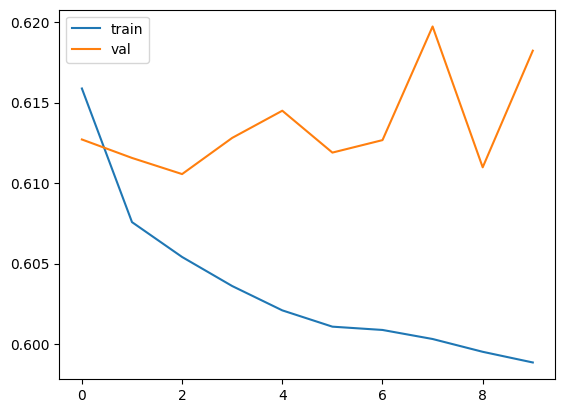

In [33]:
process_and_evaluate1(
    cnn_top200_xform_model,
    X_train, y_train,
    X_test, y_test,
    np.array(df_train1['Ticker_Encoded']), np.array(df_test1['Ticker_Encoded'])
    ,checkpoint_path=rf'{checkpoints_path}\cnn_top200_xform.keras',epochs=30,batch_size=16
)

In [34]:
cnn_top200_xform_model_loaded = tf.keras.models.load_model(rf'{checkpoints_path}\cnn_top200_xform.keras')

In [35]:
pred_probs_test = cnn_top200_xform_model_loaded.predict([ticker_encoded_test, X_test])
pred_probs_train = cnn_top200_xform_model_loaded.predict([ticker_encoded_train, X_train])

338/338 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
1344/1344 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step


In [36]:
np.isnan(pred_probs_test).sum()

np.int64(0)

In [37]:
np.isnan(pred_probs_train).sum()

np.int64(0)

In [38]:

def calculate_metrics1(y_true, y_pred_label,y_pred_prob):
    accuracy = accuracy_score(y_true, y_pred_label)
    precision = precision_score(y_true, y_pred_label)
    recall = recall_score(y_true, y_pred_label)
    f1 = f1_score(y_true, y_pred_label)
    confusion = confusion_matrix(y_true,y_pred_label)
    roc_score = roc_auc_score(y_true,y_pred_prob)
    
    return {
        'accuracy': accuracy,
        'roc':roc_score,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix':confusion
    }



In [39]:
train_metrics1 = calculate_metrics1(y_train,(pred_probs_train>=0.5).astype(int),pred_probs_train)
test_metrics1 = calculate_metrics1(y_test,(pred_probs_test>=0.5).astype(int),pred_probs_test)

In [40]:
train_metrics_df1 = pd.DataFrame([train_metrics1])
train_metrics_df1['Set'] = "Train"
test_metrics_df1 = pd.DataFrame([test_metrics1])
test_metrics_df1['Set'] = "Test"
model_metrics1 = pd.concat([train_metrics_df1,test_metrics_df1],axis=0)
model_metrics1.reset_index(drop=True,inplace=True)
model_metrics1.head()

,accuracy,roc,precision,recall,f1,confusion_matrix,Set
0,0.70071,0.590252,0.582278,0.003572,0.007100,"[[30074, 33], [12832, 46]]",Train
1,0.78337,0.493559,0.342857,0.005159,0.010165,"[[8439, 23], [2314, 12]]",Test


In [41]:
model_name = 'cnn_top200_xform'
top_n = 30

In [42]:
def label_prediction(row, model_name,top_n):
    in_top_50 = row[f'Top_{top_n}_Pred_Prob_{model_name}']
    target = row['Target']
    
    if in_top_50 and target == 1:
        return 'TP'
    elif in_top_50 and target == 0:
        return 'FP'
    elif not in_top_50 and target == 0:
        return 'TN'
    elif not in_top_50 and target == 1:
        return 'FN'

def flag_top50_nlargest(group, pred_prob_col,top_n):
    # If all pred_probs are zero, return all False
    if group[pred_prob_col].sum() == 0:
        return pd.Series([False] * len(group), index=group.index)
    # Use nlargest to get exactly 50
    top50_idx = group[pred_prob_col].nlargest(top_n).index
    flag = pd.Series(False, index=group.index)
    flag.loc[top50_idx] = True
    return flag

def label_prediction1(row, model_name):
    has_more_prob_than_threshold = row[f'Pred_Prob_Threshold_{model_name}']
    target = row['Target']
    
    if has_more_prob_than_threshold and target == 1:
        return 'TP'
    elif has_more_prob_than_threshold and target == 0:
        return 'FP'
    elif not has_more_prob_than_threshold and target == 0:
        return 'TN'
    elif not has_more_prob_than_threshold and target == 1:
        return 'FN'
    
def add_suffix_to_cols(df, suffix, exclude_cols):
    return df.rename(
        columns={col: f"{col}{suffix}" for col in df.columns if col not in exclude_cols + ['Quarter', 'Set']}
    )


In [43]:

if len(set(['Rank','Returns'])-set(df_train1.columns))!=0:
    print("There are no rank and returns columns, merging now..!")
    df_train1 = df_train1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')
    df_test1 = df_test1.merge(df_master[['Ticker','Quarter','Returns','Rank']],on=['Ticker','Quarter'],how='left')

if np.isnan(pred_probs_train).all():
    print("All predictionsa re NaNs")

df_train_pred = df_train1[['Ticker','Quarter','Target','Returns','Rank']]
df_test_pred = df_test1[['Ticker','Quarter','Target','Returns','Rank']]

df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)

#### Top30 as fund - irrespective of the prob values
df_train_pred.loc[:,'Set'] = 'Train'
df_test_pred.loc[:,'Set'] = 'Test'
df_pred = pd.concat([df_train_pred,df_test_pred],axis=0)



df_pred.reset_index(drop=True,inplace=True)
df_pred.sort_values(by=['Quarter',f'Pred_Prob_{model_name}'],ascending=False,inplace=True)
df_pred[f'Top_{top_n}_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',top_n)

df_pred[f'Top_50_Pred_Prob_{model_name}'] = df_pred.groupby('Quarter', group_keys=False).apply(flag_top50_nlargest, f'Pred_Prob_{model_name}',50)
# df_pred[(df_pred['Top_{top_n}_Pred_Prob_lstm_top50']==True)&(df_pred['Quarter']=='2005-12-31')]

# test_qtr_preds = df_pred[(df_pred['Quarter']=='2005-12-31')]['Pred_Prob_lstm_top50']
# test_qtr_preds[test_qtr_preds>0.9].shape
df_pred['Pred_Category_Top30'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=30), axis=1)
df_pred['Pred_Category_Top50'] = df_pred.apply(lambda row: label_prediction(row, model_name=model_name,top_n=50), axis=1)
df_pred.reset_index(drop=True,inplace=True)

qtr_summary_df = df_pred.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Top30=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_30_Pred_Prob_{model_name}'] == True].mean()),
                    Avg_Returns_Predicted_Top50=('Returns',lambda x: x[df_pred.loc[x.index, f'Top_50_Pred_Prob_{model_name}'] == True].mean()),
                    Count_TP_Top30=('Pred_Category_Top30', lambda x: (x == 'TP').sum()),
                    Count_TN_Top30=('Pred_Category_Top30', lambda x: (x == 'TN').sum()),
                    Count_FP_Top30=('Pred_Category_Top30', lambda x: (x == 'FP').sum()),
                    Count_FN_Top30=('Pred_Category_Top30', lambda x: (x == 'FN').sum()),
                    Count_TP_Top50=('Pred_Category_Top50', lambda x: (x == 'TP').sum()),
                    Count_TN_Top50=('Pred_Category_Top50', lambda x: (x == 'TN').sum()),
                    Count_FP_Top50=('Pred_Category_Top50', lambda x: (x == 'FP').sum()),
                    Count_FN_Top50=('Pred_Category_Top50', lambda x: (x == 'FN').sum())
                    
                    ).reset_index()

# set_summary_df = qtr_summary_df.groupby('Set').agg(
#     Count_TP = ('Count_TP','sum'),
#     Count_TN = ('Count_TN','sum'),
#     Count_FP = ('Count_FP','sum'),
#     Count_FN = ('Count_FN','sum')
# )

df_pred1 = df_pred[['Ticker','Quarter','Target','Returns','Rank',f'Pred_Prob_{model_name}','Set']].copy()
df_pred1[f'Pred_Prob_Threshold_{model_name}'] = df_pred1[f'Pred_Prob_{model_name}'].between(0.5,1)



df_pred1['Pred_Category'] = df_pred1.apply(lambda row: label_prediction1(row, model_name=model_name), axis=1)
quarterly_returns_f2 = df_pred1.groupby('Quarter').agg(
                    Set = ('Set','first'),
                    Avg_Returns_Predicted_Thresh=('Returns', lambda x: x[df_pred1.loc[x.index, f'Pred_Prob_Threshold_{model_name}'] == True].mean()),
                    Count_TP_Thresh=('Pred_Category', lambda x: (x == 'TP').sum()),
                    Count_TN_Thresh=('Pred_Category', lambda x: (x == 'TN').sum()),
                    Count_FP_Thresh=('Pred_Category', lambda x: (x == 'FP').sum()),
                    Count_FN_Thresh=('Pred_Category', lambda x: (x == 'FN').sum())
                    ).reset_index()

qtr_summary_df2 = pd.DataFrame(quarterly_returns_f2)


#### Actual and Index returns mapping
##### Actual returns
act_returns = df_pred[df_pred['Target']==1].groupby(by='Quarter')['Returns'].mean()
df_act_returns = pd.DataFrame(act_returns)
df_act_returns.reset_index(inplace=True)
df_act_returns.rename(columns={'Returns':'Avg_Returns_Actual'},inplace=True)
qtr_summary_df = qtr_summary_df.merge(df_act_returns,on='Quarter',how='left')

##### Index returns - Qtrly
df_index = pd.read_excel(qtrly_returns_path,sheet_name='Qtrly_Stock_Returns')
df_index1 = df_index[df_index['Ticker'] == 'Nsemcap'].drop(columns=['Industry']).set_index(keys=['Ticker'])
df_index1 = df_index1.T
df_index1.reset_index(inplace=True)
df_index1.rename(columns={'index':'Quarter','Nsemcap':'Index_Returns'},inplace=True)

df_index1['Quarter'] = df_index1['Quarter'].apply(convert_qtr_to_date)
df_index1['Quarter'] = pd.to_datetime(df_index1['Quarter'],dayfirst=True)

qtr_summary_df = qtr_summary_df.merge(df_index1,how='left',on='Quarter')
qtr_summary_df['delta_returns_act_vs_pred_Top30'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top30']
qtr_summary_df['delta_returns_pred_vs_index_Top30'] = qtr_summary_df['Avg_Returns_Predicted_Top30']-qtr_summary_df['Index_Returns']
qtr_summary_df['delta_returns_act_vs_pred_Top50'] = qtr_summary_df['Avg_Returns_Actual']-qtr_summary_df['Avg_Returns_Predicted_Top50']
qtr_summary_df['delta_returns_pred_vs_index_Top50'] = qtr_summary_df['Avg_Returns_Predicted_Top50']-qtr_summary_df['Index_Returns']

qtr_summary_df2 = qtr_summary_df2.merge(df_act_returns,on='Quarter',how='left')
qtr_summary_df2 = qtr_summary_df2.merge(df_index1,on='Quarter',how='left')

qtr_summary_df2['delta_returns_act_vs_pred_Thresh'] = qtr_summary_df2['Avg_Returns_Actual']-qtr_summary_df2['Avg_Returns_Predicted_Thresh']
qtr_summary_df2['delta_returns_pred_vs_index_Thresh'] = qtr_summary_df2['Avg_Returns_Predicted_Thresh']-qtr_summary_df2['Index_Returns']


exclude_cols = ['Avg_Returns_Actual', 'Index_Returns']

# Reset index for merge
qtr_summary_df2_reset = qtr_summary_df2.reset_index(drop=True)
qtr_summary_df_reset = qtr_summary_df.reset_index(drop=True)

# Merge as before
merged_qtr_summary = pd.merge(
    qtr_summary_df_reset, qtr_summary_df2_reset,
    on=['Quarter', 'Set', 'Avg_Returns_Actual', 'Index_Returns'],
    how='inner',
    suffixes=('', '')
)

# Define the desired column order
ordered_cols = [
    'Quarter','Set',
    'Avg_Returns_Predicted_Top30','Avg_Returns_Predicted_Top50',
    'Avg_Returns_Predicted_Thresh',
    'Avg_Returns_Actual', 'Index_Returns',
    'delta_returns_act_vs_pred_Top30','delta_returns_pred_vs_index_Top30',
    'delta_returns_act_vs_pred_Top50','delta_returns_pred_vs_index_Top50',
    'delta_returns_act_vs_pred_Thresh','delta_returns_pred_vs_index_Thresh',
    'Count_TP_Top30', 'Count_TP_Top50', 'Count_TP_Thresh',
    'Count_TN_Top30', 'Count_TN_Top50', 'Count_TN_Thresh',
    'Count_FP_Top30', 'Count_FP_Top50', 'Count_FP_Thresh',
    'Count_FN_Top30', 'Count_FN_Top50', 'Count_FN_Thresh'
]

# Add any other columns that might exist but are not in the list
ordered_cols += [col for col in merged_qtr_summary.columns if col not in ordered_cols]

# Reorder columns
merged_qtr_summary = merged_qtr_summary[ordered_cols]
# merged_qtr_summary.reset_index(inplace=True)
merged_qtr_summary.head()

There are no rank and returns columns, merging now..!


C:\Users\43737\AppData\Local\Temp\ipykernel_41316\1919607964.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test_pred[f'Pred_Prob_{model_name}'] = pred_probs_test.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_41316\1919607964.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_pred[f'Pred_Prob_{model_name}'] = pred_probs_train.reshape(-1)
C:\Users\43737\AppData\Local\Temp\ipykernel_41316\1919607964.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.389688,0.373269,NaN,0.532415,-0.019376,0.142727,0.409064,0.159146,...,0,281,273,294,13,21,0,174,162,191
1,2005-06-30,Train,0.308446,0.328860,0.417744,0.645971,0.045476,0.337525,0.262970,0.317111,...,1,277,268,291,14,23,0,178,167,193
2,2005-09-30,Train,0.060812,0.043897,0.160409,0.231957,0.244277,0.171145,-0.183465,0.188061,...,1,267,254,287,20,33,0,188,181,197
3,2005-12-31,Train,0.098432,0.203862,NaN,0.471668,0.058583,0.373236,0.039848,0.267806,...,0,269,261,288,19,27,0,186,174,197
4,2006-03-31,Train,-0.134974,-0.036301,-0.333066,0.085933,0.187746,0.220908,-0.322720,0.122235,...,0,277,267,292,16,26,1,183,173,197


In [44]:
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].isna().all()

np.False_

In [45]:
merged_qtr_summary.columns

Index(['Quarter', 'Set', 'Avg_Returns_Predicted_Top30',
       'Avg_Returns_Predicted_Top50', 'Avg_Returns_Predicted_Thresh',
       'Avg_Returns_Actual', 'Index_Returns',
       'delta_returns_act_vs_pred_Top30', 'delta_returns_pred_vs_index_Top30',
       'delta_returns_act_vs_pred_Top50', 'delta_returns_pred_vs_index_Top50',
       'delta_returns_act_vs_pred_Thresh',
       'delta_returns_pred_vs_index_Thresh', 'Count_TP_Top30',
       'Count_TP_Top50', 'Count_TP_Thresh', 'Count_TN_Top30', 'Count_TN_Top50',
       'Count_TN_Thresh', 'Count_FP_Top30', 'Count_FP_Top50',
       'Count_FP_Thresh', 'Count_FN_Top30', 'Count_FN_Top50',
       'Count_FN_Thresh'],
      dtype='object')

In [46]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.5774448 , 0.53883755, 0.5213934 , ..., 0.04775403, 0.03295176,
       0.03068565], dtype=float32)

In [47]:
set_summary_df3 =  merged_qtr_summary.groupby('Set').agg(
    Count_TP_Thresh = ('Count_TP_Thresh','sum'),
    Count_TN_Thresh = ('Count_TN_Thresh','sum'),
    Count_FP_Thresh = ('Count_FP_Thresh','sum'),
    Count_FN_Thresh = ('Count_FN_Thresh','sum'),
    Count_TP_Top30 = ('Count_TP_Top30','sum'),
    Count_TN_Top30 = ('Count_TN_Top30','sum'),
    Count_FP_Top30 = ('Count_FP_Top30','sum'),
    Count_FN_Top30 = ('Count_FN_Top30','sum'),
    Count_TP_Top50 = ('Count_TP_Top50','sum'),
    Count_TN_Top50 = ('Count_TN_Top50','sum'),
    Count_FP_Top50 = ('Count_FP_Top50','sum'),
    Count_FN_Top50 = ('Count_FN_Top50','sum')
)
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,12,8439,23,2314,76,8178,284,2250,121,7983,479,2205
Train,46,30074,33,12832,971,29038,1069,11907,1510,28217,1890,11368


In [49]:

def calc_metrics(tp, tn, fp, fn):
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    return accuracy, precision, recall, f1


In [50]:
for suffix in ['_Top30','_Top50', '_Thresh']:
    print(f"\nMetrics for {suffix}:")
    for set_name, row in set_summary_df3.iterrows():
        tp = row[f'Count_TP{suffix}']
        tn = row[f'Count_TN{suffix}']
        fp = row[f'Count_FP{suffix}']
        fn = row[f'Count_FN{suffix}']
        accuracy, precision, recall, f1 = calc_metrics(tp, tn, fp, fn)
        print(f"{set_name}: accuracy={accuracy:.4f}, precision={precision:.4f}, recall={recall:.4f}, f1={f1:.4f}")


Metrics for _Top30:
Test: accuracy=0.7651, precision=0.2111, recall=0.0327, f1=0.0566
Train: accuracy=0.6981, precision=0.4760, recall=0.0754, f1=0.1302

Metrics for _Top50:
Test: accuracy=0.7512, precision=0.2017, recall=0.0520, f1=0.0827
Train: accuracy=0.6916, precision=0.4441, recall=0.1173, f1=0.1855

Metrics for _Thresh:
Test: accuracy=0.7834, precision=0.3429, recall=0.0052, f1=0.0102
Train: accuracy=0.7007, precision=0.5823, recall=0.0036, f1=0.0071


In [51]:
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean():
    print("Both the stock picking strategies (Top 30 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Thresh'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 50 and Pred prob theshold) have same returns")
if merged_qtr_summary['Avg_Returns_Predicted_Top30'].mean()==merged_qtr_summary['Avg_Returns_Predicted_Top50'].mean():
    print("Both the stock picking strategies (Top 30 and Top 50) have same returns")
else:
    print("All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns")

All of the stock picking strategies (Top 30, Top 50 and Pred prob theshold) have different returns


In [52]:
merged_qtr_summary[merged_qtr_summary['Avg_Returns_Predicted_Top30'].isna()].shape

(2, 25)

In [53]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].unique()

array([0.5774448 , 0.53883755, 0.5213934 , ..., 0.04775403, 0.03295176,
       0.03068565], dtype=float32)

In [54]:
df_pred[df_pred['Set']=='Test'][f'Pred_Prob_{model_name}'].describe()

count    10788.000000
mean         0.305617
std          0.064980
min          0.028781
25%          0.276065
50%          0.313050
75%          0.344995
max          0.590494
Name: Pred_Prob_cnn_top200_xform, dtype: float64

In [55]:
merged_qtr_summary['Quarter'].is_monotonic_increasing

True

In [56]:
set_summary_df3

,Count_TP_Thresh,Count_TN_Thresh,Count_FP_Thresh,Count_FN_Thresh,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50
Set,,,,,,,,,,,,
Test,12,8439,23,2314,76,8178,284,2250,121,7983,479,2205
Train,46,30074,33,12832,971,29038,1069,11907,1510,28217,1890,11368


In [57]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'] = merged_qtr_summary['Avg_Returns_Predicted_Top30'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Top50'] = merged_qtr_summary['Avg_Returns_Predicted_Top50'].ffill()
merged_qtr_summary['Avg_Returns_Predicted_Thresh'] = merged_qtr_summary['Avg_Returns_Predicted_Thresh'].ffill()

In [58]:
merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Top50'].fillna(0,inplace=True)
merged_qtr_summary['Avg_Returns_Predicted_Thresh'].fillna(0,inplace=True)

C:\Users\43737\AppData\Local\Temp\ipykernel_41316\4263771019.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  merged_qtr_summary['Avg_Returns_Predicted_Top30'].fillna(0,inplace=True)
C:\Users\43737\AppData\Local\Temp\ipykernel_41316\4263771019.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always beh

In [59]:
merged_qtr_summary.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Avg_Returns_Predicted_Thresh,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,...,Count_TP_Thresh,Count_TN_Top30,Count_TN_Top50,Count_TN_Thresh,Count_FP_Top30,Count_FP_Top50,Count_FP_Thresh,Count_FN_Top30,Count_FN_Top50,Count_FN_Thresh
0,2005-03-31,Train,0.389688,0.373269,0.000000,0.532415,-0.019376,0.142727,0.409064,0.159146,...,0,281,273,294,13,21,0,174,162,191
1,2005-06-30,Train,0.308446,0.328860,0.417744,0.645971,0.045476,0.337525,0.262970,0.317111,...,1,277,268,291,14,23,0,178,167,193
2,2005-09-30,Train,0.060812,0.043897,0.160409,0.231957,0.244277,0.171145,-0.183465,0.188061,...,1,267,254,287,20,33,0,188,181,197
3,2005-12-31,Train,0.098432,0.203862,0.160409,0.471668,0.058583,0.373236,0.039848,0.267806,...,0,269,261,288,19,27,0,186,174,197
4,2006-03-31,Train,-0.134974,-0.036301,-0.333066,0.085933,0.187746,0.220908,-0.322720,0.122235,...,0,277,267,292,16,26,1,183,173,197


In [60]:
df_pred.head()

,Ticker,Quarter,Target,Returns,Rank,Pred_Prob_cnn_top200_xform,Set,Top_30_Pred_Prob_cnn_top200_xform,Top_50_Pred_Prob_cnn_top200_xform,Pred_Category_Top30,Pred_Category_Top50
0,atgl,2024-12-31,0,-0.208199,473.0,0.577445,Test,True,True,FP,FP
1,aiil,2024-12-31,1,0.015105,101.0,0.538838,Test,True,True,TP,TP
2,dixon,2024-12-31,0,-0.265205,598.0,0.521393,Test,True,True,FP,FP
3,metrobra,2024-12-31,0,-0.167276,387.0,0.472716,Test,True,True,FP,FP
4,easemytr,2024-12-31,0,-0.261665,589.0,0.464564,Test,True,True,FP,FP


In [61]:
qtr_summary_df.head()

,Quarter,Set,Avg_Returns_Predicted_Top30,Avg_Returns_Predicted_Top50,Count_TP_Top30,Count_TN_Top30,Count_FP_Top30,Count_FN_Top30,Count_TP_Top50,Count_TN_Top50,Count_FP_Top50,Count_FN_Top50,Avg_Returns_Actual,Index_Returns,delta_returns_act_vs_pred_Top30,delta_returns_pred_vs_index_Top30,delta_returns_act_vs_pred_Top50,delta_returns_pred_vs_index_Top50
0,2005-03-31,Train,0.389688,0.373269,17,281,13,174,29,273,21,162,0.532415,-0.019376,0.142727,0.409064,0.159146,0.392645
1,2005-06-30,Train,0.308446,0.328860,16,277,14,178,27,268,23,167,0.645971,0.045476,0.337525,0.262970,0.317111,0.283384
2,2005-09-30,Train,0.060812,0.043897,10,267,20,188,17,254,33,181,0.231957,0.244277,0.171145,-0.183465,0.188061,-0.200380
3,2005-12-31,Train,0.098432,0.203862,11,269,19,186,23,261,27,174,0.471668,0.058583,0.373236,0.039848,0.267806,0.145279
4,2006-03-31,Train,-0.134974,-0.036301,14,277,16,183,24,267,26,173,0.085933,0.187746,0.220908,-0.322720,0.122235,-0.224047


In [62]:
qtr_summary_df['Set'].value_counts()

Set
Train    68
Test     12
Name: count, dtype: int64

In [63]:
with pd.ExcelWriter(r"D:\Python\Final Quant Fund\tf_219_env\Quant Fund\Fund1\results\lag\top200\3yrs_as_test_data_ts\Pred_Vs_Act_CNN_xform_time_split_25_07_2025.xlsx", ) as writer:
    merged_qtr_summary.to_excel(writer, sheet_name='Qtr_Summary', index=False)
    qtr_summary_df.to_excel(writer, sheet_name='Qtr_Summary_Top', index=False)
    qtr_summary_df2.to_excel(writer, sheet_name='Qtr_Summary_Thresh', index=False)
    df_pred.to_excel(writer, sheet_name='Pred_Vs_Act_Top', index=False)
    df_pred1.to_excel(writer, sheet_name='Pred_Vs_Act_Thresh', index=False)
    set_summary_df3.to_excel(writer, sheet_name='Set_Summary')